# Climate-Sensitive Death Prediction

Goal: predict whether a death is climate-sensitive (`is_climate_sensitive`) from demographics, location, weather and satellite climate features.

Metric: `0.6 * F1 + 0.4 * ROC-AUC`

Workflow:
1. Load and merge the data
2. Clean and engineer features with one shared function
3. Explore the key patterns
4. Build one scikit-learn `Pipeline` (impute, scale, encode, model)
5. Evaluate, tune the decision threshold, check feature importance
6. Refit on all labelled data and write the submission

In [ ]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance
from sklearn.decomposition import PCA
from IPython.display import display
from scipy import stats

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 200)

In [127]:
# Settings
TARGET = "is_climate_sensitive"
SEED = 42

## 1. Load and merge the data

`climate_features.csv` holds extra climate columns per `ID`. Merge them into Train and Test. `deathdate` already exists in both files, so drop the duplicate copy first.

In [128]:
climate = pd.read_csv("climate_features.csv").drop(columns=["deathdate"])

train = pd.read_csv("Train.csv").merge(climate, on="ID", how="left")
test = pd.read_csv("Test.csv").merge(climate, on="ID", how="left")

# Remove duplicate rows (ignoring ID) from the training data
train = train.drop_duplicates(subset=[c for c in train.columns if c != "ID"])

print("Train:", train.shape, " missing:", train.isna().sum().sum())
print("Test: ", test.shape, " missing:", test.isna().sum().sum())
train.sample(5)

Train: (3144, 29)  missing: 0
Test:  (1030, 28)  missing: 0


,ID,zone,gender,deathdate,age,avg_temperature,max_temperature,min_temperature,precipitation,latitude,longitude,location,is_climate_sensitive,elevation,hot_days_30d,max_daily_rain_30d,ndvi_30d,ndvi_90d,rain_days_30d,rain_sum_30d,rain_sum_7d,rain_sum_90d,slope,tavg_30d,tavg_7d,tavg_90d,temp_range_mean_30d,tmax_30d,tmin_30d
1862,ID_069F26D5,Rural,Female,2014-09-12,0.0,22.146773,27.747067,17.854374,0.162455,0.547201,33.488916,"Nawanzu, Iganga, Uganda",1,1145,0,15.840899,0.62495,0.63940,15,137.625844,18.270661,315.943870,0.299996,21.236000,21.026093,21.322461,7.819119,26.868600,16.922021
607,ID_04F95B39,Peri_urban,Female,2010-02-23,1.0,22.629103,26.082908,20.282848,1.608902,0.601729,33.473515,"Buligo South, Iganga, Uganda",1,1132,0,20.753887,0.52805,0.58690,10,75.948476,59.533750,256.484386,0.166667,23.343174,22.662495,22.435403,8.531199,30.785715,17.011972
1191,ID_9B5E7962,Peri_urban,Male,2011-11-26,81.0,20.259766,24.210973,17.289485,0.111311,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",0,1132,0,72.744766,0.62655,0.58615,18,242.008430,118.907916,569.171465,0.166667,21.112947,20.765114,21.263180,7.270743,27.180841,16.826349
2425,ID_F5DB795D,Rural,Male,2018-08-26,0.0,21.431190,26.343767,17.533959,0.598168,0.553984,33.519695,"Kakombo, Iganga, Uganda",0,1122,0,29.611895,0.63570,0.67440,10,106.409731,56.388574,225.657647,0.356825,21.610675,21.291815,21.347858,8.659354,27.680353,16.200220
2185,ID_25DE439A,Peri_urban,Male,2016-06-18,51.0,19.865934,23.117561,17.584045,4.134843,0.608396,33.482668,"Brac Uganda Iganga Regional Branch, Bikadho Ro...",1,1132,0,18.201681,0.55340,0.53935,9,105.593647,34.985107,553.863611,0.166667,22.116024,21.616520,22.547697,7.891056,27.012231,17.406076


### 1.1 Raw input files at a glance

Every file provided for the challenge, before any merging or cleaning.

In [129]:
raw_files = {
    "Train.csv": pd.read_csv("Train.csv"),
    "Test.csv": pd.read_csv("Test.csv"),
    "climate_features.csv": pd.read_csv("climate_features.csv"),
    "SampleSubmission.csv": pd.read_csv("SampleSubmission.csv"),
}

for name, df in raw_files.items():
    print(f"{name:<24} {df.shape[0]:>5} rows x {df.shape[1]:>2} cols  -  {list(df.columns)}")

Train.csv                 3146 rows x 13 cols  -  ['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'location', 'is_climate_sensitive']
Test.csv                  1030 rows x 12 cols  -  ['ID', 'zone', 'gender', 'deathdate', 'age', 'avg_temperature', 'max_temperature', 'min_temperature', 'precipitation', 'latitude', 'longitude', 'location']
climate_features.csv      4176 rows x 18 cols  -  ['ID', 'deathdate', 'elevation', 'hot_days_30d', 'max_daily_rain_30d', 'ndvi_30d', 'ndvi_90d', 'rain_days_30d', 'rain_sum_30d', 'rain_sum_7d', 'rain_sum_90d', 'slope', 'tavg_30d', 'tavg_7d', 'tavg_90d', 'temp_range_mean_30d', 'tmax_30d', 'tmin_30d']
SampleSubmission.csv      1030 rows x  3 cols  -  ['ID', 'TargetF1', 'TargetRAUC']


### 1.2 Full column-by-column profile

One row per column: type, cardinality, missing values, and either numeric summary stats or the most frequent category. This covers every column in the merged train and test sets, not just the ones singled out later.

In [130]:
def profile(df, name):
    rows = []
    for col in df.columns:
        s = df[col]
        row = {
            "column": col,
            "dtype": str(s.dtype),
            "n_unique": s.nunique(),
            "missing": int(s.isna().sum()),
            "missing_pct": round(100 * s.isna().mean(), 2),
        }
        if pd.api.types.is_numeric_dtype(s):
            row.update({
                "min": s.min(), "mean": round(s.mean(), 3),
                "median": s.median(), "max": s.max(),
                "std": round(s.std(), 3),
                "top_value": np.nan, "top_freq": np.nan,
            })
        else:
            counts = s.value_counts(dropna=True)
            row.update({
                "min": np.nan, "mean": np.nan, "median": np.nan,
                "max": np.nan, "std": np.nan,
                "top_value": counts.index[0] if len(counts) else None,
                "top_freq": int(counts.iloc[0]) if len(counts) else None,
            })
        rows.append(row)
    out = pd.DataFrame(rows).set_index("column")
    print(f" {name}: {df.shape[0]} rows x {df.shape[1]} cols")
    return out

display(profile(train, "train (merged, pre-cleaning)"))
display(profile(test, "test (merged, pre-cleaning)"))

 train (merged, pre-cleaning): 3144 rows x 29 cols


,dtype,n_unique,missing,missing_pct,min,mean,median,max,std,top_value,top_freq
column,,,,,,,,,,,
ID,object,3144,0,0.0,NaN,NaN,NaN,NaN,NaN,ID_1FE951BD,1.0
zone,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Rural,1971.0
gender,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Male,1644.0
deathdate,object,2210,0,0.0,NaN,NaN,NaN,NaN,NaN,2008-11-25,6.0
age,float64,109,0,0.0,0.000000,24.259,3.000000,110.000000,31.433,NaN,NaN
avg_temperature,float64,2210,0,0.0,18.852803,22.066,21.931299,27.012223,1.095,NaN,NaN
max_temperature,float64,2210,0,0.0,20.884623,26.207,26.081829,34.080947,1.692,NaN,NaN
min_temperature,float64,2210,0,0.0,15.018778,18.514,18.510478,21.849602,0.892,NaN,NaN
precipitation,float64,2181,0,0.0,0.000000,1.520,1.034344,16.606523,1.622,NaN,NaN


 test (merged, pre-cleaning): 1030 rows x 28 cols


,dtype,n_unique,missing,missing_pct,min,mean,median,max,std,top_value,top_freq
column,,,,,,,,,,,
ID,object,1030,0,0.0,NaN,NaN,NaN,NaN,NaN,ID_E760D84B,1.0
zone,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Rural,785.0
gender,object,2,0,0.0,NaN,NaN,NaN,NaN,NaN,Male,531.0
deathdate,object,912,0,0.0,NaN,NaN,NaN,NaN,NaN,2021-06-24,3.0
age,float64,102,0,0.0,0.000000,23.922,3.000000,107.000000,31.124,NaN,NaN
avg_temperature,float64,912,0,0.0,18.954983,22.038,21.922381,26.981866,1.071,NaN,NaN
max_temperature,float64,912,0,0.0,21.359154,26.136,26.062903,34.080947,1.603,NaN,NaN
min_temperature,float64,912,0,0.0,15.018778,18.526,18.520424,20.936959,0.861,NaN,NaN
precipitation,float64,909,0,0.0,0.000112,1.614,1.023268,16.606523,1.819,NaN,NaN


## 2. Cleaning and feature engineering

One function prepares both Train and Test. This keeps the two datasets identical in structure and removes the copy-pasted test code from the original notebook.

- **Location**: fix typos, normalise spacing and casing, then extract the `region` (the segment before ", Uganda").
- **Date**: year, month and Uganda's rainy seasons (March to May, September to November).
- **Rainfall**: log precipitation, intensity and recent-vs-longer-term ratios.
- **Temperature**: daily range and short-term anomalies.
- **Vegetation**: NDVI change (drought or crop stress signal).
- **Age**: infant, under-5 and elderly flags, plus an under-5 × rainfall interaction.

In [131]:
RAINY_MONTHS = [3, 4, 5, 9, 10, 11]


def clean_location(s):
    return (
        s.str.replace("Propeer", "Proper", regex=False)
         .str.replace("Buwoya", "Buwaya", regex=False)
         .str.replace(", Eastern Region", "", regex=False)
         .str.replace(r",\s*,", ",", regex=True)
         .str.replace(r"\s+", " ", regex=True)
         .str.strip()
         .str.replace(r"\s*,\s*", ", ", regex=True)
         .str.title()
    )


def prepare(df):
    df = df.copy()

    # Location -> region
    df["location"] = clean_location(df["location"])
    df["region"] = df["location"].str.split(",").str[-2].str.strip()

    # Date
    date = pd.to_datetime(df["deathdate"])
    df["death_year"] = date.dt.year
    df["death_month"] = date.dt.month
    df["is_rainy_season"] = df["death_month"].isin(RAINY_MONTHS).astype(int)

    # Rainfall
    df["log_precipitation"] = np.log1p(df["precipitation"])
    df["rain_intensity_30d"] = df["rain_sum_30d"] / (df["rain_days_30d"] + 1)
    df["rain_recent_ratio"] = df["rain_sum_7d"] / (df["rain_sum_30d"] + 1)
    df["rain_30d_vs_90d"] = df["rain_sum_30d"] / (df["rain_sum_90d"] + 1)

    # Temperature
    df["temp_range"] = df["max_temperature"] - df["min_temperature"]
    df["temp_anomaly_7d"] = df["tavg_7d"] - df["tavg_90d"]
    df["heat_stress_30d"] = df["tmax_30d"] - df["tavg_90d"]

    # Vegetation
    df["ndvi_change"] = df["ndvi_30d"] - df["ndvi_90d"]

    # Age
    df["is_infant"] = (df["age"] == 0).astype(int)
    df["is_under5"] = (df["age"] < 5).astype(int)
    df["is_elderly"] = (df["age"] >= 60).astype(int)
    df["under5_x_rain30"] = df["is_under5"] * df["rain_sum_30d"]

    return df


train = prepare(train)
test = prepare(test)

train[["location", "region", "death_year", "death_month", "is_under5"]].sample(5)

,location,region,death_year,death_month,is_under5
2662,"Wante, Bugweri, Uganda",Bugweri,2020,2,0
2154,"Buluza, Iganga, Uganda",Iganga,2016,4,0
52,"Nawansinge, Iganga, Uganda",Iganga,2008,11,1
1554,"Buligo South, Iganga, Uganda",Iganga,2013,6,1
697,"Nakigo Ii, Iganga, Uganda",Iganga,2010,5,1


### 2.1 Humidity and heat-index data (Open-Meteo)

Loads daily humidity and feels-like temperature for each location and builds 8 window features from them. **These features are not in the final model**: section 6.7's cross-validation showed no gain (+0.0002, p=0.60). The cell stays because later sections reuse its data loader (`om_by_loc`, `add_humidity_features`): sections 10, 13, 17 and 19.

In [132]:
# openmeteo_humidity.csv was fetched once from the free Open-Meteo Historical
# Weather API (https://archive-api.open-meteo.com/v1/archive) for the 55
# unique (latitude, longitude) pairs across Train+Test, covering 2007-07-01
# to 2022-12-13: daily relative humidity and "apparent" (feels-like,
# humidity-adjusted) temperature. 
#
# Why bother: the competition brief explicitly names land-surface temperature
# and humidity-driven indicators as permitted enrichment sources, and the
# error analysis (section 6.7) found the model was weakest for working-age
# adults (18-59) -- precisely the group where occupational/perceived heat
# stress (humidity-adjusted, not raw air temperature) is most plausible as a
# missing driver.
om = pd.read_csv("openmeteo_humidity.csv")
om["time"] = pd.to_datetime(om["time"])
om["latitude"] = om["latitude"].round(6)
om["longitude"] = om["longitude"].round(6)
om_by_loc = {key: g.set_index("time").sort_index() for key, g in om.groupby(["latitude", "longitude"])}


def _window(series_df, end_date, days):
    start = end_date - pd.Timedelta(days=days)
    return series_df.loc[(series_df.index > start) & (series_df.index <= end_date)]


def add_humidity_features(df):
    df = df.copy()
    deathdate = pd.to_datetime(df["deathdate"])
    lat_r = df["latitude"].round(6)
    lon_r = df["longitude"].round(6)

    hum7, hum30 = [], []
    appmax30, appmean30, appmean7, appmean90 = [], [], [], []
    for end, lat, lon in zip(deathdate, lat_r, lon_r):
        loc_series = om_by_loc.get((lat, lon))
        if loc_series is None:
            hum7.append(np.nan); hum30.append(np.nan)
            appmax30.append(np.nan); appmean30.append(np.nan)
            appmean7.append(np.nan); appmean90.append(np.nan)
            continue
        w7 = _window(loc_series, end, 7)
        w30 = _window(loc_series, end, 30)
        w90 = _window(loc_series, end, 90)
        hum7.append(w7["relative_humidity_2m_mean"].mean())
        hum30.append(w30["relative_humidity_2m_mean"].mean())
        appmax30.append(w30["apparent_temperature_max"].max())
        appmean30.append(w30["apparent_temperature_mean"].mean())
        appmean7.append(w7["apparent_temperature_mean"].mean())
        appmean90.append(w90["apparent_temperature_mean"].mean())

    df["humidity_mean_7d"] = hum7
    df["humidity_mean_30d"] = hum30
    df["apptemp_max_30d"] = appmax30
    df["apptemp_mean_30d"] = appmean30
    df["apptemp_mean_7d"] = appmean7
    df["apptemp_mean_90d"] = appmean90
    df["apptemp_anomaly_7d"] = df["apptemp_mean_7d"] - df["apptemp_mean_90d"]
    df["heat_index_stress_30d"] = df["apptemp_max_30d"] - df["apptemp_mean_90d"]
    return df


train = add_humidity_features(train)
test = add_humidity_features(test)

HUMIDITY_COLS = ["humidity_mean_7d", "humidity_mean_30d", "apptemp_max_30d", "apptemp_mean_30d",
                 "apptemp_mean_7d", "apptemp_mean_90d", "apptemp_anomaly_7d", "heat_index_stress_30d"]
print("Missing rate after location join:")
print(train[HUMIDITY_COLS].isna().mean().round(3))
train[["age"] + HUMIDITY_COLS].head()

Missing rate after location join:
humidity_mean_7d         0.0
humidity_mean_30d        0.0
apptemp_max_30d          0.0
apptemp_mean_30d         0.0
apptemp_mean_7d          0.0
apptemp_mean_90d         0.0
apptemp_anomaly_7d       0.0
heat_index_stress_30d    0.0
dtype: float64


,age,humidity_mean_7d,humidity_mean_30d,apptemp_max_30d,apptemp_mean_30d,apptemp_mean_7d,apptemp_mean_90d,apptemp_anomaly_7d,heat_index_stress_30d
0,30.0,82.000000,84.000000,33.6,24.036667,24.457143,23.572222,0.884921,10.027778
1,2.0,73.857143,79.133333,33.3,24.513333,25.557143,24.821111,0.736032,8.478889
2,31.0,83.714286,81.666667,32.8,24.300000,23.985714,24.566667,-0.580952,8.233333
3,1.0,83.142857,82.000000,32.8,24.556667,24.457143,24.807778,-0.350635,7.992222
4,69.0,72.428571,72.400000,29.0,20.903333,21.157143,20.991111,0.166032,8.008889


## 3. Exploratory data analysis

Four views of the target: overall balance, and the climate-sensitive rate by age group, region and year.

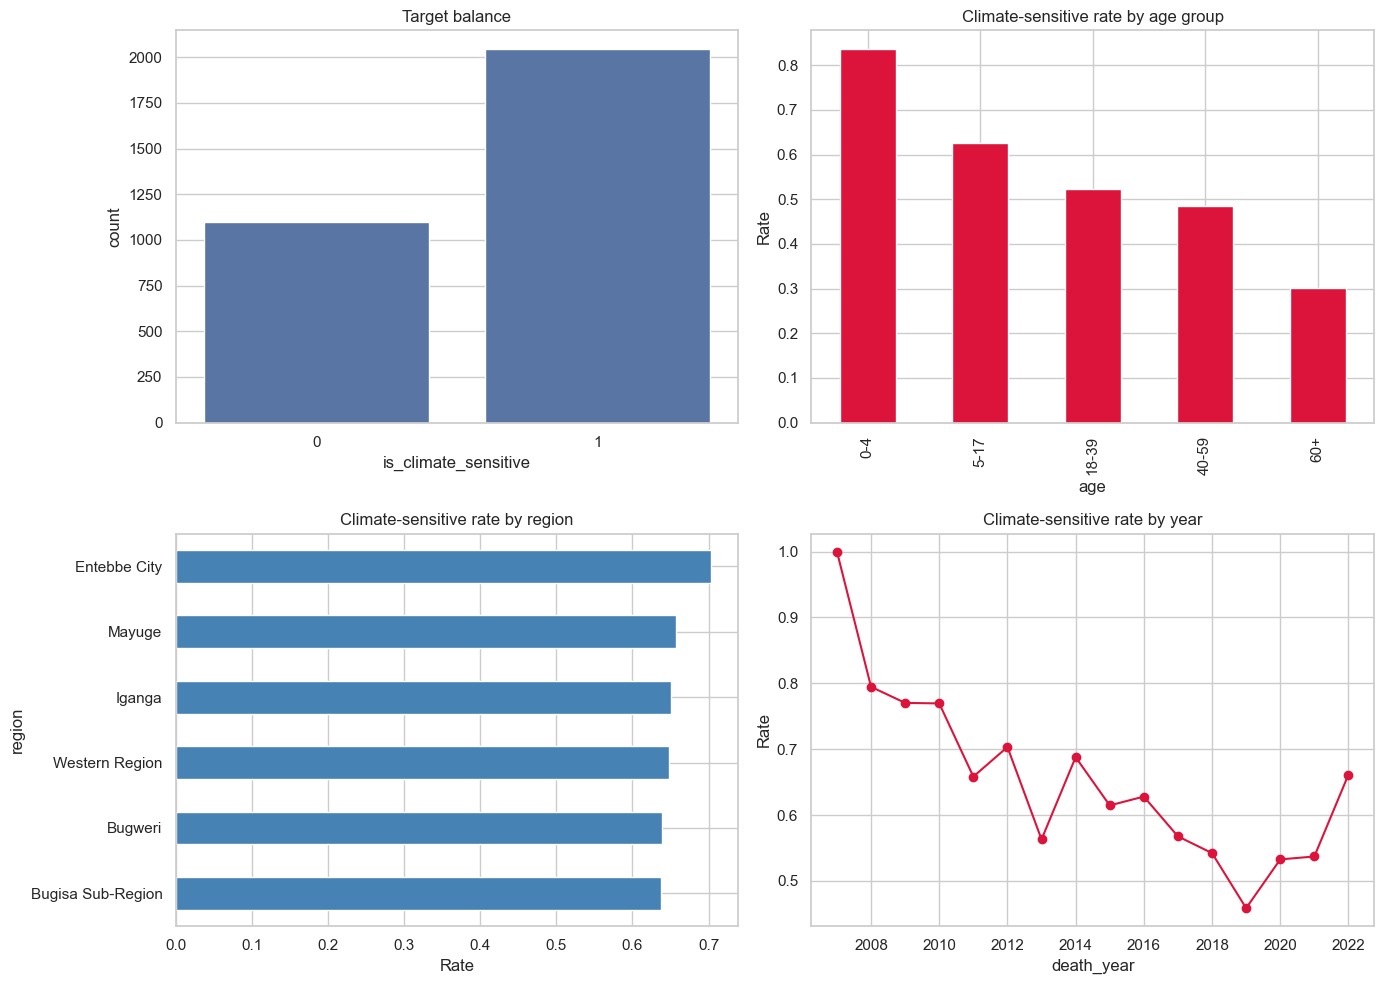

In [133]:
age_group = pd.cut(
    train["age"],
    bins=[-1, 4, 17, 39, 59, np.inf],
    labels=["0-4", "5-17", "18-39", "40-59", "60+"],
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(x=TARGET, data=train, ax=axes[0, 0])
axes[0, 0].set_title("Target balance")

train.groupby(age_group, observed=True)[TARGET].mean().plot(
    kind="bar", ax=axes[0, 1], color="crimson"
)
axes[0, 1].set_title("Climate-sensitive rate by age group")
axes[0, 1].set_ylabel("Rate")

train.groupby("region")[TARGET].mean().sort_values().plot(
    kind="barh", ax=axes[1, 0], color="steelblue"
)
axes[1, 0].set_title("Climate-sensitive rate by region")
axes[1, 0].set_xlabel("Rate")

train.groupby("death_year")[TARGET].mean().plot(
    marker="o", ax=axes[1, 1], color="crimson"
)
axes[1, 1].set_title("Climate-sensitive rate by year")
axes[1, 1].set_ylabel("Rate")

plt.tight_layout()
plt.show()

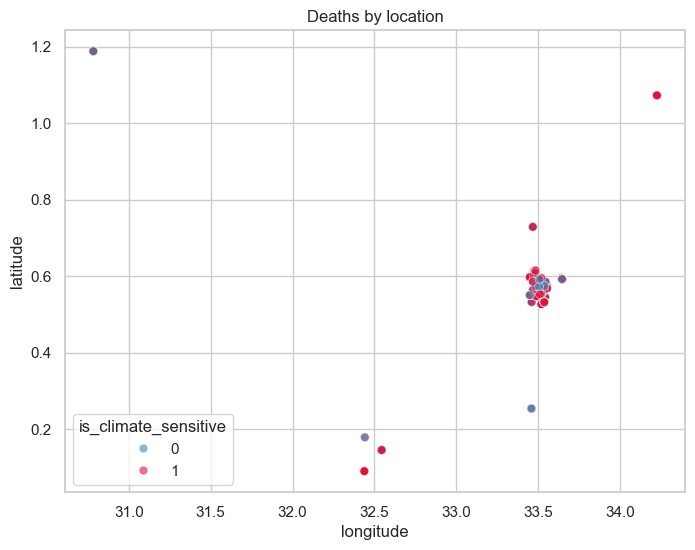

In [134]:
# Where the deaths happened, coloured by target
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=train, x="longitude", y="latitude", hue=TARGET,
    palette={0: "steelblue", 1: "crimson"}, alpha=0.6, s=40,
)
plt.title("Deaths by location")
plt.show()

### 3.1 Data quality checks

In [135]:
raw_train = pd.read_csv("Train.csv")
print("Train shape:", train.shape, "| Test shape:", test.shape)
print("Duplicate rows in raw Train.csv (excl. ID):",
      raw_train.duplicated(subset=[c for c in raw_train.columns if c != "ID"]).sum())
print("Missing values -> train:", train.isna().sum().sum(), "| test:", test.isna().sum().sum())
print("hot_days_30d unique values:", sorted(train["hot_days_30d"].unique()),
      "-> constant column, zero signal, already excluded from the model")
print()
print("Location cardinality -> train:", train["location"].nunique(), "| test:", test["location"].nunique())
unseen_loc = set(test["location"]) - set(train["location"])
print(f"Test locations never seen in train: {len(unseen_loc)} / {test['location'].nunique()}")
print("Test regions never seen in train:  ", sorted(set(test["region"]) - set(train["region"])))

Train shape: (3144, 53) | Test shape: (1030, 52)
Duplicate rows in raw Train.csv (excl. ID): 2
Missing values -> train: 0 | test: 0
hot_days_30d unique values: [0] -> constant column, zero signal, already excluded from the model

Location cardinality -> train: 37 | test: 11
Test locations never seen in train: 10 / 11
Test regions never seen in train:   ['Kalangala', 'Kamuli', 'Sembabule']


### 3.2 Age is the dominant signal

The target is far from independent of age, and the relationship is strongly non-linear (U-shaped rather than monotonic), so age needs to be modelled with enough flexibility (bins/splines, or a tree-based model) rather than as a single linear term.

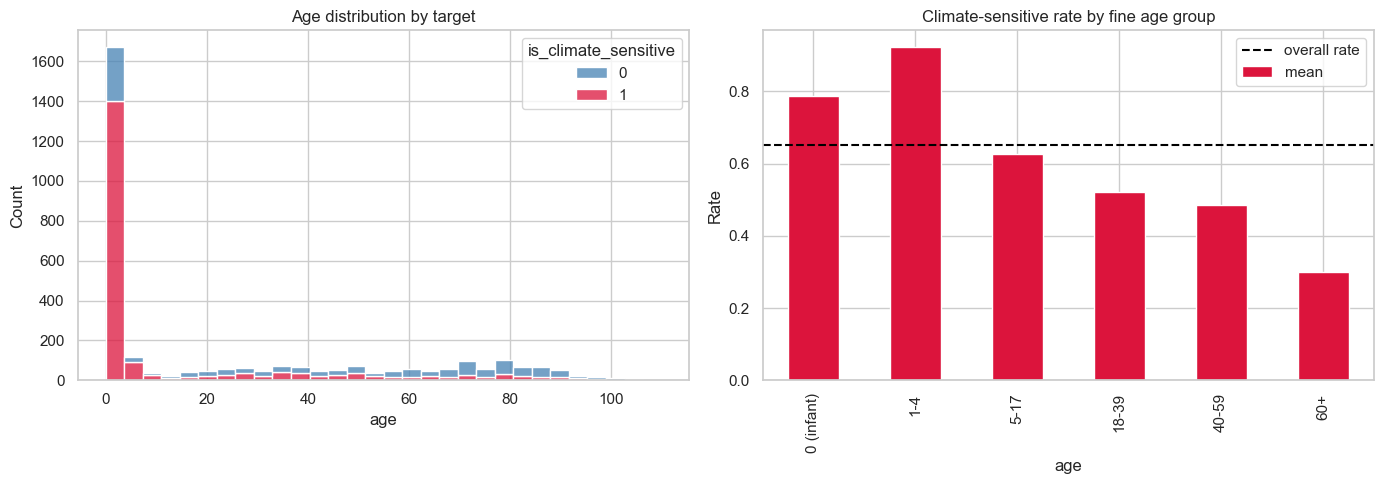

                mean  count
age                        
0 (infant)  0.787387   1110
1-4         0.922705    621
5-17        0.625899    139
18-39       0.522124    339
40-59       0.484429    289
60+         0.300310    646


In [99]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(data=train, x="age", hue=TARGET, bins=30, multiple="stack",
             palette={0: "steelblue", 1: "crimson"}, ax=axes[0])
axes[0].set_title("Age distribution by target")

age_bins = pd.cut(train["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                   labels=["0 (infant)", "1-4", "5-17", "18-39", "40-59", "60+"])
rate_by_age = train.groupby(age_bins, observed=True)[TARGET].agg(["mean", "count"])
rate_by_age["mean"].plot(kind="bar", ax=axes[1], color="crimson")
axes[1].axhline(train[TARGET].mean(), color="black", linestyle="--", label="overall rate")
axes[1].set_title("Climate-sensitive rate by fine age group")
axes[1].set_ylabel("Rate")
axes[1].legend()
plt.tight_layout()
plt.show()

print(rate_by_age)

### 3.3 Ranking every numeric feature by correlation with the target

Point-biserial correlation (equivalent to Pearson correlation against the 0/1 target) for every numeric column, including the engineered features.

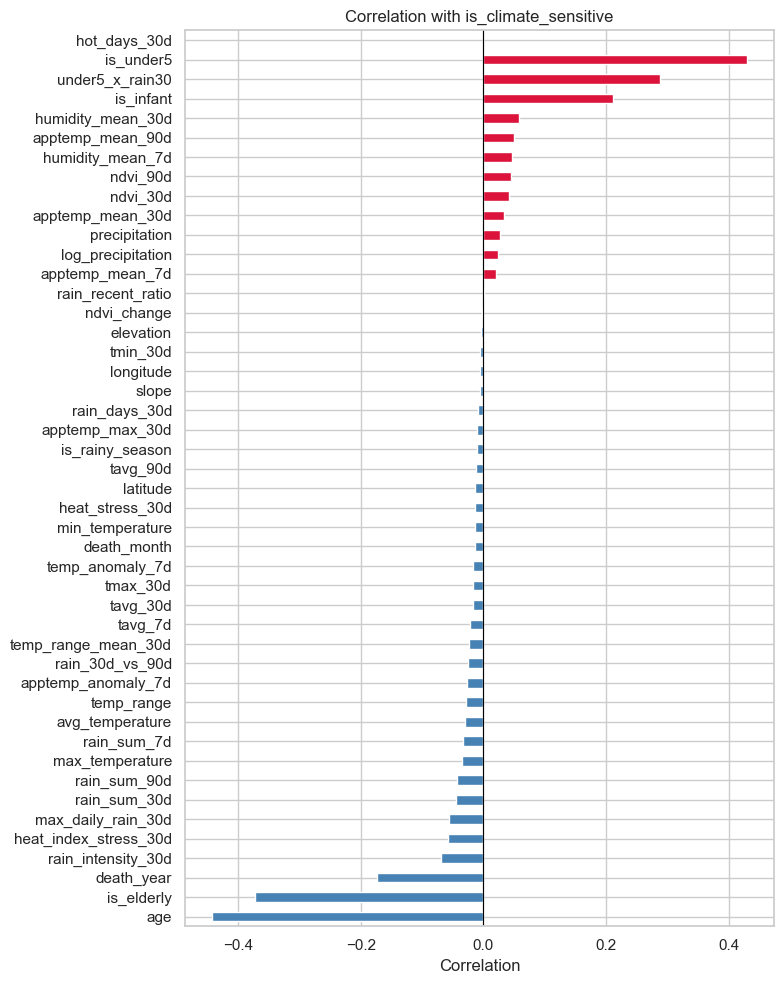

age                     -0.443
is_under5                0.431
is_elderly              -0.373
under5_x_rain30          0.288
is_infant                0.212
death_year              -0.174
rain_intensity_30d      -0.069
humidity_mean_30d        0.058
heat_index_stress_30d   -0.058
max_daily_rain_30d      -0.057
apptemp_mean_90d         0.049
humidity_mean_7d         0.046
ndvi_90d                 0.045
rain_sum_30d            -0.044
rain_sum_90d            -0.043
ndvi_30d                 0.041
max_temperature         -0.036
apptemp_mean_30d         0.034
rain_sum_7d             -0.033
avg_temperature         -0.030
temp_range              -0.028
precipitation            0.028
apptemp_anomaly_7d      -0.027
rain_30d_vs_90d         -0.025
temp_range_mean_30d     -0.023
log_precipitation        0.023
tavg_7d                 -0.021
apptemp_mean_7d          0.020
tavg_30d                -0.018
tmax_30d                -0.018
temp_anomaly_7d         -0.016
death_month             -0.014
min_temp

In [100]:
num_cols = [c for c in train.select_dtypes(include=[np.number]).columns if c != TARGET]
corr = train[num_cols + [TARGET]].corr()[TARGET].drop(TARGET).sort_values()

plt.figure(figsize=(8, 10))
colors = ["crimson" if v > 0 else "steelblue" for v in corr.values]
corr.plot(kind="barh", color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Correlation with is_climate_sensitive")
plt.xlabel("Correlation")
plt.tight_layout()
plt.show()

print(corr.reindex(corr.abs().sort_values(ascending=False).index).round(3))

### 3.4 Categorical features: zone, gender, region

Chi-square test of independence for each categorical feature against the target, plus the climate-sensitive rate per category.

In [101]:
from scipy import stats

for col in ["zone", "gender", "region"]:
    ct = pd.crosstab(train[col], train[TARGET])
    chi2, p, _, _ = stats.chi2_contingency(ct)
    rates = train.groupby(col)[TARGET].agg(["mean", "count"]).sort_values("mean")
    print(f"--- {col} (chi2 p-value = {p:.4f}) ---")
    print(rates, "\n")

# gender's effect is concentrated in working-age adults, not infants/elderly
age_grp = np.where(train["age"] < 5, "under5", np.where(train["age"] >= 60, "60+", "5-59"))
print("Climate-sensitive rate by gender x age group:")
print(train.groupby([pd.Series(age_grp, index=train.index), "gender"])[TARGET].mean().unstack())

--- zone (chi2 p-value = 0.3750) ---
                mean  count
zone                       
Peri_urban  0.640239   1173
Rural       0.656520   1971 

--- gender (chi2 p-value = 0.0210) ---
            mean  count
gender                 
Male    0.631387   1644
Female  0.671333   1500 

--- region (chi2 p-value = 0.9642) ---
                       mean  count
region                            
Bugisa Sub-Region  0.636943    157
Bugweri            0.638191    199
Western Region     0.648438    128
Iganga             0.650556   2338
Mayuge             0.656716    268
Entebbe City       0.703704     54 

Climate-sensitive rate by gender x age group:
gender    Female      Male
5-59    0.620482  0.455172
60+     0.289634  0.311321
under5  0.840476  0.831650


### 3.5 Climate features are highly redundant with each other

The temperature family and the rainfall family are each internally collinear (r up to ~0.9), so most windows (7d/30d/90d) carry overlapping information rather than independent signal.

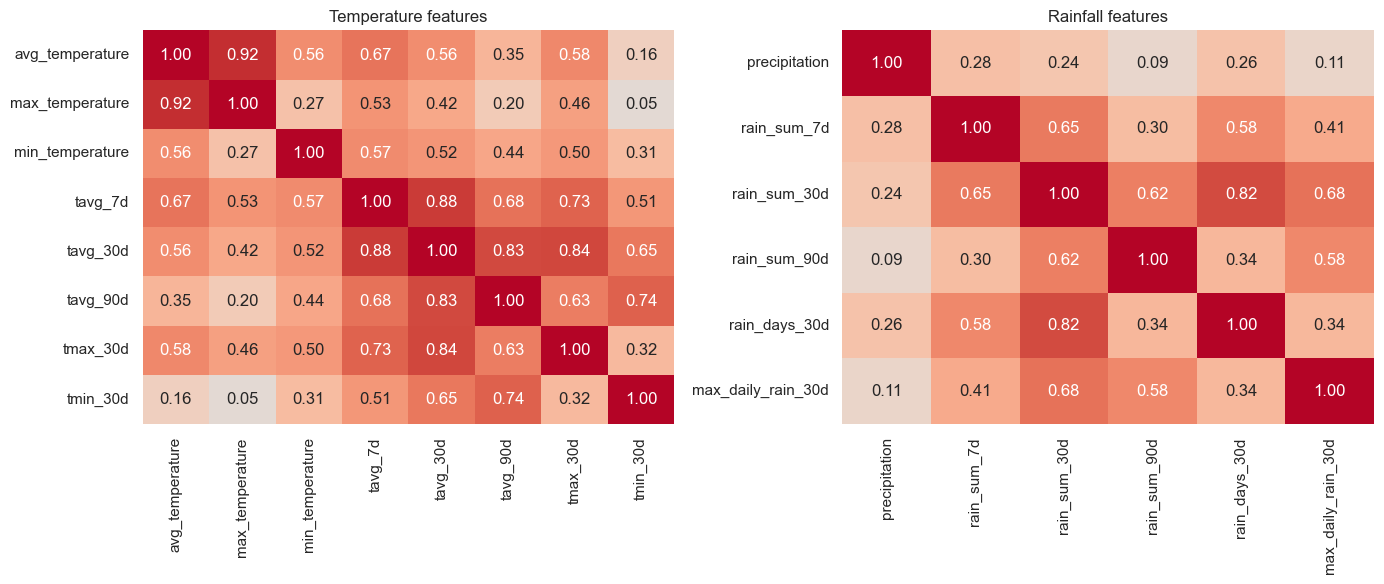

In [102]:
temp_cols = ["avg_temperature", "max_temperature", "min_temperature",
             "tavg_7d", "tavg_30d", "tavg_90d", "tmax_30d", "tmin_30d"]
rain_cols = ["precipitation", "rain_sum_7d", "rain_sum_30d", "rain_sum_90d",
             "rain_days_30d", "max_daily_rain_30d"]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.heatmap(train[temp_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[0], cbar=False)
axes[0].set_title("Temperature features")
sns.heatmap(train[rain_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm",
            center=0, ax=axes[1], cbar=False)
axes[1].set_title("Rainfall features")
plt.tight_layout()
plt.show()

### 3.6 Train vs. test: does the geography generalize?

Kolmogorov-Smirnov two-sample test per numeric feature. A large KS statistic means train and test are drawn from visibly different distributions for that column -- a warning sign for features the model might lean on but that won't transfer to the test locations.

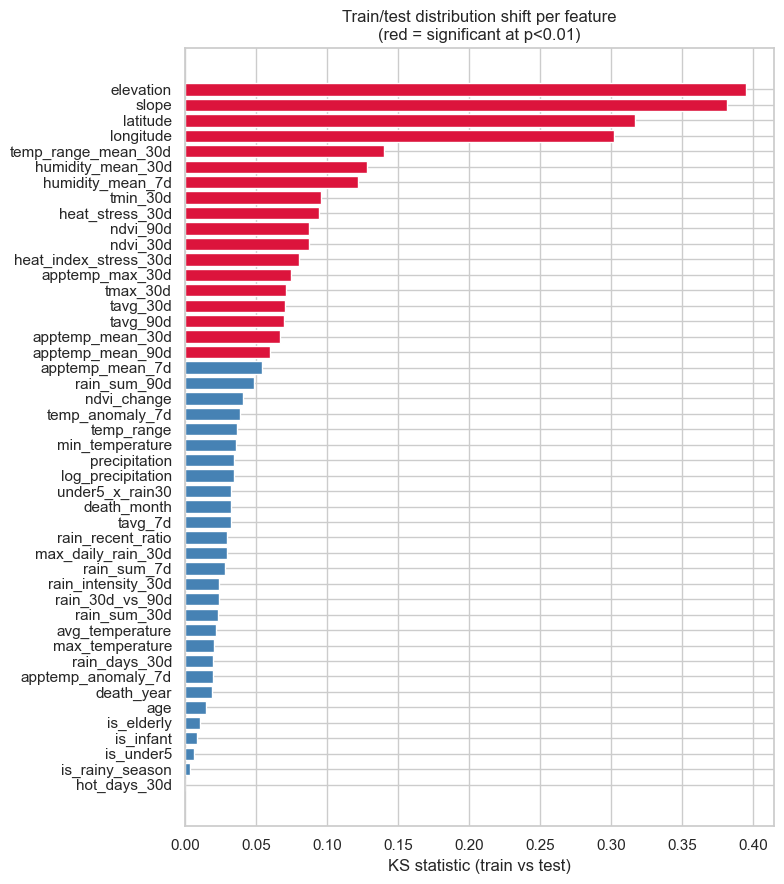

            feature  ks_stat          ks_p
          elevation 0.395136 6.099375e-109
              slope 0.381733 1.680968e-101
           latitude 0.316677  2.226788e-69
          longitude 0.302306  3.663866e-63
temp_range_mean_30d 0.139992  1.003972e-13
  humidity_mean_30d 0.128400  1.304668e-11
   humidity_mean_7d 0.121523  1.916830e-10
           tmin_30d 0.095485  1.302842e-06


In [103]:
shift_rows = []
for c in num_cols:
    if c in test.columns:
        ks_stat, ks_p = stats.ks_2samp(train[c].dropna(), test[c].dropna())
        shift_rows.append((c, ks_stat, ks_p))
shift = pd.DataFrame(shift_rows, columns=["feature", "ks_stat", "ks_p"]).sort_values("ks_stat", ascending=False)

plt.figure(figsize=(8, 9))
plt.barh(shift["feature"], shift["ks_stat"],
         color=["crimson" if p < 0.01 else "steelblue" for p in shift["ks_p"]])
plt.xlabel("KS statistic (train vs test)")
plt.title("Train/test distribution shift per feature\n(red = significant at p<0.01)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print(shift.head(8).to_string(index=False))

### Key takeaways from the data

- **Age dominates, and peaks in toddlers, not infants.** Age is the single strongest predictor (corr ≈ -0.44). The rate climbs from 79% at age 0 to a peak of **92% at ages 1-4**, then falls through childhood to ~30% for 60+, against an overall base rate of ~65%. The dip at age 0 relative to 1-4 suggests infant deaths have a different (less climate-driven) cause mix than toddler deaths -- worth encoding as a non-linear age feature (bins/splines or a tree split) rather than a linear term.
- **Individual climate variables are weak in isolation.** Every raw or engineered climate feature (temperature, rainfall, NDVI, elevation, slope) has |corr| < 0.06 with the target on its own. That does not mean they are useless -- the signal may live in *interactions* (e.g. heat + infancy) rather than main effects -- but no single climate column carries the label by itself.
- **`hot_days_30d` is dead.** It is a constant 0 for every row in both train and test -- correctly excluded from the model already.
- **Gender has a mild, age-dependent effect.** Marginal on its own (p ≈ 0.02), but within the 5-59 age band the climate-sensitive rate is much higher for women than men -- a candidate interaction term.
- **Geography does not generalize.** Elevation, slope, latitude and longitude all show large train/test distribution shift, and most test locations (and half the test regions) never appear in train at all. `region`/`location` features risk overfitting to places the model will never see again -- prefer the weather variables (which are stable across train/test) over place identity.
- **Climate features are highly collinear.** The temperature family and the rainfall family each cluster at r = 0.6-0.9 with each other, so the 7d/30d/90d windows mostly duplicate information rather than adding independent signal.
- Two fully-duplicate rows (excluding ID) exist in the raw training data and are already dropped during the merge step.

### 3.7 Applying the fixes: a reproducible data-quality refinement

Turning the findings above into concrete changes, all in one place so the effect on model performance can be measured directly:

1. Drop dead (`hot_days_30d`) and non-generalizing geo columns (`location`, `region`, `elevation`, `slope`, `latitude`, `longitude`).
2. Encode `age` as the non-linear bands the data actually shows.
3. Add the gender x working-age interaction found in 3.4.
4. Compress the collinear temperature and rainfall families into PCA components.
5. Re-check for near-duplicate records beyond the exact duplicates already removed.

In [ ]:


# ---------------------------------------------------------------------------
# 0. Near-duplicate check, beyond the 2 exact duplicates already dropped in 1.
# ---------------------------------------------------------------------------
DUP_KEY = ["deathdate", "location", "age", "gender", "avg_temperature"]
near_dup_mask = train.duplicated(subset=DUP_KEY, keep=False)
print(f"Near-duplicate records (same date/location/age/gender/temp): {near_dup_mask.sum()}")
if near_dup_mask.any():
    display(train.loc[near_dup_mask, DUP_KEY + [TARGET]].sort_values(DUP_KEY))
    train = train.drop_duplicates(subset=DUP_KEY, keep="first")
    print("-> dropped extras, kept first occurrence. New train shape:", train.shape)

# ---------------------------------------------------------------------------
# 1. Drop dead / non-generalizing geo features (EDA 3.1 and 3.6):
#    hot_days_30d is constant; location/region/elevation/slope/lat/long show
#    heavy train-test distribution shift and most test locations are unseen
#    in train, so they cannot be relied on to generalize.
# ---------------------------------------------------------------------------
UNRELIABLE_GEO = ["location", "region", "elevation", "slope", "latitude", "longitude"]
DEAD_COLS = ["hot_days_30d"]

def drop_unreliable(df):
    return df.drop(columns=[c for c in UNRELIABLE_GEO + DEAD_COLS if c in df.columns])

train_r = drop_unreliable(train)
test_r = drop_unreliable(test)

# ---------------------------------------------------------------------------
# 2. Non-linear age encoding (EDA 3.2): the climate-sensitive rate peaks at
#    ages 1-4 (92%), not at age 0 (79%), then falls steadily to 30% at 60+ --
#    a pattern a single linear "age" term cannot represent.
# ---------------------------------------------------------------------------
AGE_BINS = [-1, 0, 4, 17, 39, 59, np.inf]
AGE_LABELS = ["0", "1-4", "5-17", "18-39", "40-59", "60+"]

for df in (train_r, test_r):
    df["age_band"] = pd.cut(df["age"], bins=AGE_BINS, labels=AGE_LABELS).astype(str)

# ---------------------------------------------------------------------------
# 3. Gender x working-age interaction (EDA 3.4): within the 5-59 age band,
#    women are climate-sensitive 62% of the time vs. 46% for men -- an
#    effect invisible to gender or age alone.
# ---------------------------------------------------------------------------
for df in (train_r, test_r):
    working_age = df["age"].between(5, 59)
    df["female_working_age"] = ((df["gender"] == "Female") & working_age).astype(int)

# ---------------------------------------------------------------------------
# 4. Collapse collinear climate families into PCA components (EDA 3.5): the
#    temperature family and rainfall family are each internally collinear
#    (r up to ~0.9), so the raw 7d/30d/90d windows mostly duplicate the same
#    information. 3 components per family keeps ~85-88% of that variance in
#    a fifth of the columns.
# ---------------------------------------------------------------------------
TEMP_FAMILY = ["avg_temperature", "max_temperature", "min_temperature",
               "tavg_7d", "tavg_30d", "tavg_90d", "tmax_30d", "tmin_30d"]
RAIN_FAMILY = ["precipitation", "rain_sum_7d", "rain_sum_30d", "rain_sum_90d",
               "rain_days_30d", "max_daily_rain_30d"]

def compress_family(train_df, test_df, cols, prefix, n_components=3):
    scaler = StandardScaler().fit(train_df[cols])
    pca = PCA(n_components=n_components, random_state=SEED).fit(scaler.transform(train_df[cols]))
    for df in (train_df, test_df):
        comps = pca.transform(scaler.transform(df[cols]))
        for i in range(n_components):
            df[f"{prefix}_pc{i + 1}"] = comps[:, i]
    explained = pca.explained_variance_ratio_
    print(f"{prefix}_pc1..{n_components}: explain {explained.sum():.1%} "
          f"of variance {explained.round(3).tolist()}")

compress_family(train_r, test_r, TEMP_FAMILY, "temp")
compress_family(train_r, test_r, RAIN_FAMILY, "rain")

train_r = train_r.drop(columns=TEMP_FAMILY + RAIN_FAMILY)
test_r = test_r.drop(columns=[c for c in TEMP_FAMILY + RAIN_FAMILY if c in test_r.columns])

# ---------------------------------------------------------------------------
# Swap the refined frames in for the rest of the notebook
# ---------------------------------------------------------------------------
train, test = train_r, test_r

print()
print("Refined train:", train.shape, "| refined test:", test.shape)
print("Dropped:", UNRELIABLE_GEO + DEAD_COLS + TEMP_FAMILY + RAIN_FAMILY)
print("Added:  ", ["age_band", "female_working_age", "temp_pc1..3", "rain_pc1..3"])
train.head()

Near-duplicate records (same date/location/age/gender/temp): 0
temp_pc1..3: explain 87.6% of variance [0.604, 0.19, 0.082]
rain_pc1..3: explain 84.4% of variance [0.542, 0.177, 0.125]

Refined train: (3144, 40) | refined test: (1030, 39)
Dropped: ['location', 'region', 'elevation', 'slope', 'latitude', 'longitude', 'hot_days_30d', 'avg_temperature', 'max_temperature', 'min_temperature', 'tavg_7d', 'tavg_30d', 'tavg_90d', 'tmax_30d', 'tmin_30d', 'precipitation', 'rain_sum_7d', 'rain_sum_30d', 'rain_sum_90d', 'rain_days_30d', 'max_daily_rain_30d']
Added:   ['age_band', 'female_working_age', 'temp_pc1..3', 'rain_pc1..3']


,ID,zone,gender,deathdate,age,is_climate_sensitive,ndvi_30d,ndvi_90d,temp_range_mean_30d,death_year,death_month,is_rainy_season,log_precipitation,rain_intensity_30d,rain_recent_ratio,rain_30d_vs_90d,temp_range,temp_anomaly_7d,heat_stress_30d,ndvi_change,is_infant,is_under5,is_elderly,under5_x_rain30,humidity_mean_7d,humidity_mean_30d,apptemp_max_30d,apptemp_mean_30d,apptemp_mean_7d,apptemp_mean_90d,apptemp_anomaly_7d,heat_index_stress_30d,age_band,female_working_age,temp_pc1,temp_pc2,temp_pc3,rain_pc1,rain_pc2,rain_pc3
0,ID_1FE951BD,Rural,Male,2007-10-02,30.0,1,0.72205,0.72910,7.897970,2007,10,1,0.668650,9.224424,0.161230,0.414343,7.117375,0.968588,6.564792,-0.00705,0,0,0,0.000000,82.000000,84.000000,33.6,24.036667,24.457143,23.572222,0.884921,10.027778,18-39,0,-1.600927,0.408894,0.517003,0.878473,-0.248489,-0.581125
1,ID_5927A443,Rural,Male,2008-01-05,2.0,1,0.60815,0.66985,8.735769,2008,1,0,0.051978,8.985745,0.000000,0.266798,10.334814,1.029252,7.259803,-0.06170,0,1,0,71.885960,73.857143,79.133333,33.3,24.513333,25.557143,24.821111,0.736032,8.478889,1-4,0,1.544342,2.684544,0.013077,-1.941547,-0.767084,-0.009530
2,ID_C4E67025,Rural,Female,2008-02-14,31.0,1,0.59290,0.61335,7.694241,2008,2,0,0.086498,5.149780,0.329564,0.444893,8.633080,-0.663055,6.863290,-0.02045,0,0,0,0.000000,83.714286,81.666667,32.8,24.300000,23.985714,24.566667,-0.580952,8.233333,18-39,1,0.175769,0.114275,-0.584751,-0.117067,0.355802,-1.679257
3,ID_44DC5CE9,Rural,Female,2008-02-15,1.0,1,0.59290,0.61335,7.718027,2008,2,0,0.252170,4.926226,0.292301,0.427678,9.101181,-0.537828,6.852188,-0.02045,0,1,0,98.524518,83.142857,82.000000,32.8,24.556667,24.457143,24.807778,-0.350635,7.992222,1-4,0,1.044849,0.988360,-0.056936,-0.404388,0.362795,-1.440774
4,ID_33C677BB,Rural,Female,2008-02-15,69.0,0,0.53380,0.71580,10.152887,2008,2,0,0.252170,6.002162,0.302229,0.449170,9.101181,-0.368638,7.790339,-0.18200,0,0,1,0.000000,72.428571,72.400000,29.0,20.903333,21.157143,20.991111,0.166032,8.008889,60+,0,-2.584072,4.355593,1.385079,-1.249654,0.296519,-1.080020


### Defect notice: PCA/scaler fit before the split (and the single-split evaluation it feeds)

**The bug.** `compress_family()` above fits `StandardScaler` and `PCA` on *all* of `train` -- before the 80/20 split in section 5 exists. Every row that later lands in `X_val` (and, in sections 5.5-6.9, every row in whichever cross-validation fold is being scored) already influenced the component axes it's then scored against. That is leakage, and it is not the only place sections 4-8 do this: cells 41 (threshold), 52/54 (permutation-importance pruning) and 47/56 (hyperparameter search) all pick a decision using `X_val`/`y_val` and then evaluate that same decision on `X_val`/`y_val`. Sections 6.7, 6.75 and 8 already caught and fixed this pattern for the *cross-validated* pruning helpers (`combined_score_cv`, `_wc_cv_evaluate`, `cv_evaluate` -- see the defect-fix notes on those cells); the single 80/20 split that sections 5-6.9 run on has the same flaw at its root, just without a loop to make it visible.

**Why it isn't patched in place here.** Sections 4-8 thread `train`/`test`/`X`/`preprocess`/`NUM_COLS`/`model` through roughly fifty cells as shared mutable state, built around PCA already being baked into the dataframe before any split. Splitting PCA out into a fold-safe pipeline step -- the correct fix -- changes what "the feature set" means for every one of those cells, which amounts to rebuilding sections 4-8's whole modelling pipeline rather than editing one cell.

**Where the fix actually lives.** Rather than duplicate that rebuild twice, it's done once: the evaluation framework in the new section below (Step 1 of the plan) wraps PCA in a proper `sklearn` `Transformer` (`FamilyPCACompressor`) whose `.fit()` scikit-learn guarantees is only ever called on the current training fold, inside `Pipeline`/cross-validation. That framework -- not sections 4-8 -- is the leak-free standard used for every result reported from this point in the notebook onward, including the final model and submission. Sections 4-8 stay as they ran: a documented, superseded first pass, not a source of trustworthy numbers. Specific figures they reported and that later sections quoted (0.8349, 0.8259, 0.7909, 0.8316) are corrected at their point of citation below, next to what the corrected, leak-free re-run actually supports.


### 3.8 A second pass: real vs. spurious interactions

Before adding more engineered features, check which candidate interactions actually carry information beyond what's already in the model, rather than assuming multiplying two columns together helps.

In [105]:

# ---------------------------------------------------------------------------
# Stress-test a batch of candidate climate x age interactions. A naive
# corr(target, flag * continuous_var) is misleading when the continuous
# variable has low relative variance: it just rescales the flag's own main
# effect rather than detecting a real interaction. The correct check is
# whether the continuous variable predicts the target *within* the flagged
# subgroup differently than outside it.
#
# NOTE: this needs the raw rain/temp columns, which section 3.7 already
# compressed into PCA components and dropped from `train`. Rebuild an
# independent reference frame here rather than relying on the (already
# refined) global train/test.
# ---------------------------------------------------------------------------
_climate_ref = pd.read_csv("climate_features.csv").drop(columns=["deathdate"])
_ref = pd.read_csv("Train.csv").merge(_climate_ref, on="ID", how="left")
_ref = _ref.drop_duplicates(subset=[c for c in _ref.columns if c != "ID"])

is_under5_ref = _ref["age"] < 5

def within_group_corr(col):
    in_group = _ref.loc[is_under5_ref]
    out_group = _ref.loc[~is_under5_ref]
    r_in, p_in = stats.pointbiserialr(in_group[TARGET], in_group[col])
    r_out, p_out = stats.pointbiserialr(out_group[TARGET], out_group[col])
    return r_in, p_in, r_out, p_out

print("Checking whether climate variables predict the target differently for")
print("under-5s than for everyone else (a real interaction) or not (redundant")
print("with the is_under5 flag already in the model):")
print()
for col in ["rain_days_30d", "rain_sum_30d", "ndvi_30d", "tavg_30d"]:
    r_in, p_in, r_out, p_out = within_group_corr(col)
    verdict = "REAL interaction" if (p_in < 0.01 and p_out > 0.1) else "no clear interaction"
    print(f"  {col:15s} under-5: r={r_in:+.3f} (p={p_in:.2g})   "
          f"others: r={r_out:+.3f} (p={p_out:.2g})   -> {verdict}")

print()
print("Only rain_sum_30d shows a genuine interaction, and it is already captured by")
print("the existing `under5_x_rain30` feature from section 2 -- confirmed still")
print("useful, nothing new to add there. The rest (ndvi, temperature) do not modify")
print("the under-5 risk differently from the general population; adding")
print("multiplicative terms for them would just add noise, so they are deliberately")
print("left out.")

Checking whether climate variables predict the target differently for
under-5s than for everyone else (a real interaction) or not (redundant
with the is_under5 flag already in the model):

  rain_days_30d   under-5: r=-0.022 (p=0.37)   others: r=-0.023 (p=0.39)   -> no clear interaction
  rain_sum_30d    under-5: r=-0.109 (p=6e-06)   others: r=-0.030 (p=0.27)   -> REAL interaction
  ndvi_30d        under-5: r=+0.053 (p=0.028)   others: r=+0.038 (p=0.15)   -> no clear interaction
  tavg_30d        under-5: r=+0.014 (p=0.57)   others: r=-0.013 (p=0.63)   -> no clear interaction

Only rain_sum_30d shows a genuine interaction, and it is already captured by
the existing `under5_x_rain30` feature from section 2 -- confirmed still
useful, nothing new to add there. The rest (ndvi, temperature) do not modify
the under-5 risk differently from the general population; adding
multiplicative terms for them would just add noise, so they are deliberately
left out.


### 3.9 Two evidence-based additions: zone x age crossover, and a coarser year signal

In [106]:
# ---------------------------------------------------------------------------
# A real (if modest) crossover found in the EDA: rural elderly and peri-urban
# mid-life adults each carry a several-point-higher rate than their
# counterpart zone, in opposite directions -- something a plain "zone" or
# "age_band" main effect can't represent on its own.
#   zone x 60+   : Rural 33.4% vs Peri_urban 24.7%
#   zone x 40-59 : Peri_urban 53.2% vs Rural 46.2%
# ---------------------------------------------------------------------------
for df in (train, test):
    df["is_rural_elderly"] = ((df["zone"] == "Rural") & (df["age"] >= 60)).astype(int)
    df["is_periurban_midage"] = ((df["zone"] == "Peri_urban") & df["age"].between(40, 59)).astype(int)

# ---------------------------------------------------------------------------
# death_year on its own is the strongest non-age signal (corr ~ -0.17), with
# a clear decline from ~80% (2008-2010) to ~45-55% (2017-2021) before an
# uptick in 2022. The single-year buckets are noisy at the edges (2007 has
# 1 row, 2022 has 62), so add a coarser 3-era version alongside the raw year
# -- a tree can use whichever is more reliable in a given split.
# ---------------------------------------------------------------------------
def death_era(year):
    if year <= 2010:
        return 0
    if year <= 2016:
        return 1
    return 2

for df in (train, test):
    df["death_era"] = df["death_year"].apply(death_era)

print("Added: is_rural_elderly, is_periurban_midage, death_era")
print(train[["zone", "age", "is_rural_elderly", "is_periurban_midage",
             "death_year", "death_era"]].sample(5, random_state=SEED))

Added: is_rural_elderly, is_periurban_midage, death_era
            zone  age  is_rural_elderly  is_periurban_midage  death_year  \
2995       Rural  0.0                 0                    0        2021   
2973       Rural  0.0                 0                    0        2021   
1065       Rural  3.0                 0                    0        2011   
1988       Rural  4.0                 0                    0        2015   
2992  Peri_urban  0.0                 0                    0        2021   

      death_era  
2995          2  
2973          2  
1065          1  
1988          1  
2992          2  


## 4. Features and preprocessing pipeline

- **Dropped**: `ID`, `deathdate` (replaced by year and month), `location` (near-unique free text, replaced by `region`) and `hot_days_30d` (constant, carries no signal).
- **Numeric**: median imputation, then standard scaling (unnecessary for Random Forest, kept so the pipeline works unchanged if the classifier is swapped back).
- **Categorical**: most-frequent imputation, then one-hot encoding. `handle_unknown="ignore"` covers regions seen only in Test.

The pipeline fits all preprocessing on training data only, so no information leaks from validation or test rows.

In [107]:
DROP_COLS = ["ID", "deathdate", TARGET]
CAT_COLS = ["gender", "zone", "age_band"]

X = train.drop(columns=DROP_COLS)
y = train[TARGET]
NUM_COLS = [c for c in X.columns if c not in CAT_COLS]

print(f"{len(NUM_COLS)} numeric + {len(CAT_COLS)} categorical features")
print("Target balance:", y.value_counts(normalize=True).round(3).to_dict())

37 numeric + 3 categorical features
Target balance: {1: 0.65, 0: 0.35}


In [108]:
numeric_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("impute", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore")),
])

preprocess = ColumnTransformer([
    ("num", numeric_pipe, NUM_COLS),
    ("cat", categorical_pipe, CAT_COLS),
])

model = Pipeline([
    ("preprocess", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    )),
])

model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocess', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contai

## 5. Train and evaluate

80/20 stratified split. `evaluate()` prints F1, ROC-AUC, the combined competition score, a classification report and a confusion matrix.

Validation (threshold = 0.50)
  F1:               0.8122
  ROC-AUC:          0.8183
  Combined (60/40): 0.8146

              precision    recall  f1-score   support

           0       0.66      0.56      0.61       220
           1       0.78      0.85      0.81       409

    accuracy                           0.75       629
   macro avg       0.72      0.70      0.71       629
weighted avg       0.74      0.75      0.74       629



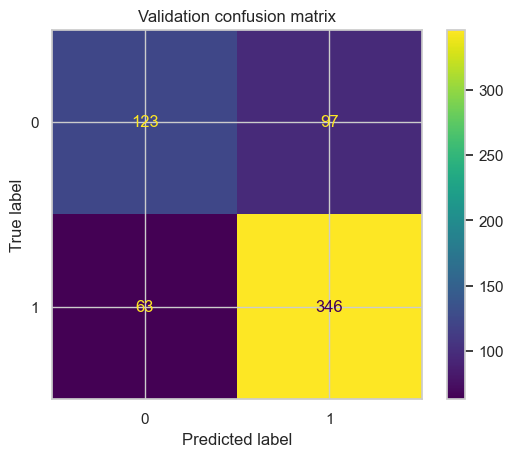

In [109]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

model.fit(X_train, y_train)
val_proba = model.predict_proba(X_val)[:, 1]


def evaluate(y_true, proba, threshold=0.5, title="Validation"):
    pred = (proba >= threshold).astype(int)
    f1 = f1_score(y_true, pred)
    auc = roc_auc_score(y_true, proba)
    print(f"{title} (threshold = {threshold:.2f})")
    print(f"  F1:               {f1:.4f}")
    print(f"  ROC-AUC:          {auc:.4f}")
    print(f"  Combined (60/40): {0.6 * f1 + 0.4 * auc:.4f}\n")
    print(classification_report(y_true, pred))
    ConfusionMatrixDisplay(confusion_matrix(y_true, pred)).plot()
    plt.title(f"{title} confusion matrix")
    plt.show()


evaluate(y_val, val_proba)

### Tune the decision threshold

`class_weight="balanced"` pushes predictions toward the minority class, so 0.5 is rarely the best cut-off for F1. ROC-AUC ignores the threshold, so tuning the threshold only moves the F1 part of the score.

The threshold comes from the validation set. Treat the tuned score as slightly optimistic.

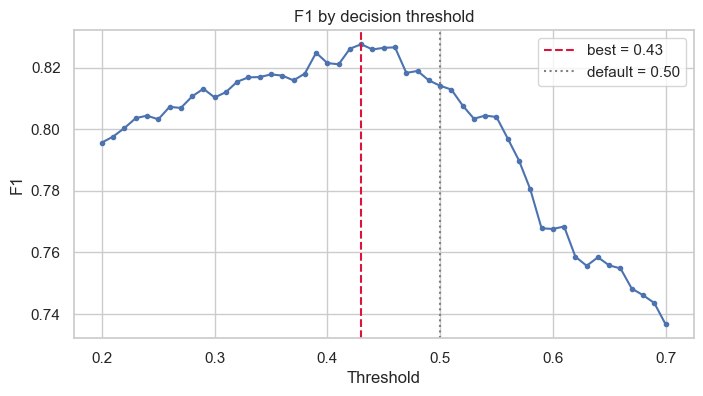

Validation, tuned (threshold = 0.43)
  F1:               0.8276
  ROC-AUC:          0.8183
  Combined (60/40): 0.8239

              precision    recall  f1-score   support

           0       0.73      0.46      0.57       220
           1       0.76      0.91      0.83       409

    accuracy                           0.75       629
   macro avg       0.75      0.69      0.70       629
weighted avg       0.75      0.75      0.74       629



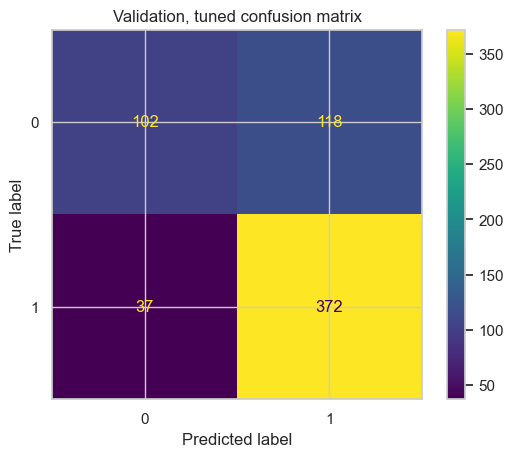

In [110]:
thresholds = np.arange(0.20, 0.71, 0.01)
f1_scores = [f1_score(y_val, (val_proba >= t).astype(int)) for t in thresholds]
best_threshold = thresholds[int(np.argmax(f1_scores))]

plt.figure(figsize=(8, 4))
plt.plot(thresholds, f1_scores, marker=".")
plt.axvline(best_threshold, color="crimson", linestyle="--", label=f"best = {best_threshold:.2f}")
plt.axvline(0.5, color="grey", linestyle=":", label="default = 0.50")
plt.xlabel("Threshold")
plt.ylabel("F1")
plt.title("F1 by decision threshold")
plt.legend()
plt.show()

evaluate(y_val, val_proba, threshold=best_threshold, title="Validation, tuned")

## 5.5 Trying stronger models now that the features are cleaner

The baseline uses a default Random Forest. With the noisy/non-generalizing columns gone and age properly encoded (section 3.7), it's worth checking whether a boosted-tree model does better on the same train/val split and preprocessing pipeline. All models use class-balancing and are evaluated the same way: F1 at the per-model best threshold, ROC-AUC, and the competition's combined (60/40) score.

In [111]:
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

candidates = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        random_state=SEED, class_weight="balanced"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300, max_depth=4, learning_rate=0.05,
        scale_pos_weight=scale_pos_weight, eval_metric="logloss",
        random_state=SEED, n_jobs=-1,
    ),
    "LightGBM": LGBMClassifier(
        n_estimators=300, max_depth=-1, learning_rate=0.05,
        class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1,
    ),
    "CatBoost": CatBoostClassifier(
        iterations=300, learning_rate=0.05, depth=6,
        auto_class_weights="Balanced", random_state=SEED, verbose=False,
    ),
}

results = []
fitted_models = {}
for name, clf in candidates.items():
    pipe = Pipeline([("preprocess", clone(preprocess)), ("clf", clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_val)[:, 1]

    ths = np.arange(0.20, 0.71, 0.01)
    f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
    best_t = ths[int(np.argmax(f1s))]
    f1_tuned = max(f1s)
    auc = roc_auc_score(y_val, proba)

    results.append({
        "model": name,
        "f1_default": f1_score(y_val, (proba >= 0.5).astype(int)),
        "best_threshold": best_t,
        "f1_tuned": f1_tuned,
        "roc_auc": auc,
        "combined": 0.6 * f1_tuned + 0.4 * auc,
        "has_feature_importances": hasattr(pipe.named_steps["clf"], "feature_importances_"),
    })
    fitted_models[name] = (pipe, best_t)

comparison = pd.DataFrame(results).sort_values("combined", ascending=False).reset_index(drop=True)
comparison

c:\python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,f1_default,best_threshold,f1_tuned,roc_auc,combined,has_feature_importances
0,RandomForest,0.812207,0.43,0.827586,0.818271,0.823860,True
1,HistGradientBoosting,0.785805,0.39,0.818074,0.812908,0.816008,False
2,LightGBM,0.779449,0.25,0.820628,0.804884,0.814330,True
3,XGBoost,0.773609,0.28,0.815145,0.806018,0.811494,True
4,CatBoost,0.774704,0.26,0.810458,0.811141,0.810731,True


The best-scoring model (among those exposing feature importances, so section 6 keeps working) is promoted to `model` / `best_threshold` for the rest of the notebook.

Selected: RandomForest  (combined=0.8239, F1=0.8276, AUC=0.8183, threshold=0.43)
Validation, RandomForest (tuned) (threshold = 0.43)
  F1:               0.8276
  ROC-AUC:          0.8183
  Combined (60/40): 0.8239

              precision    recall  f1-score   support

           0       0.73      0.46      0.57       220
           1       0.76      0.91      0.83       409

    accuracy                           0.75       629
   macro avg       0.75      0.69      0.70       629
weighted avg       0.75      0.75      0.74       629



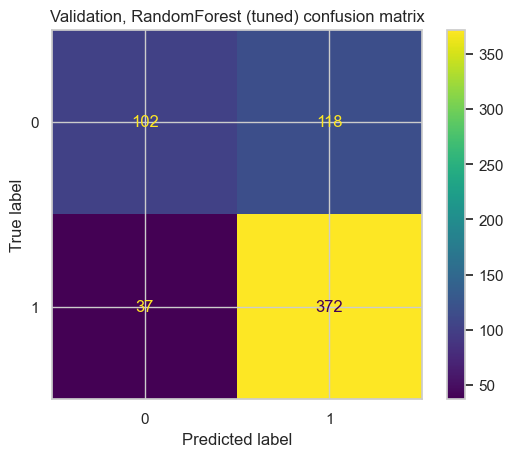

In [112]:
# Only consider models exposing feature_importances_, so section 6 below
# (which reads model.named_steps["clf"].feature_importances_) keeps working
# unchanged regardless of which model wins.
eligible = comparison[comparison["has_feature_importances"]].reset_index(drop=True)
best_name = eligible.loc[0, "model"]
best_row = eligible.loc[0]
model, best_threshold = fitted_models[best_name]

print(f"Selected: {best_name}  (combined={best_row['combined']:.4f}, "
      f"F1={best_row['f1_tuned']:.4f}, AUC={best_row['roc_auc']:.4f}, "
      f"threshold={best_threshold:.2f})")
evaluate(y_val, model.predict_proba(X_val)[:, 1], threshold=best_threshold,
         title=f"Validation, {best_name} (tuned)")

## 5.6 Hyperparameter tuning and ensembling

Random Forest won the model comparison above, but with mostly default settings for every candidate. Two more things worth trying before settling on a final model:

- **Tune the winning Random Forest** with a randomized search over depth, leaf size and tree count, optimizing the competition's combined metric directly via cross-validation.
- **Soft-vote the top-performing models** (Random Forest, HistGradientBoosting, CatBoost) -- averaging predicted probabilities across diverse model families often generalizes better than any single one.

In [113]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import make_scorer

# ---------------------------------------------------------------------------
# DEFECT FIX: both RandomizedSearchCV runs in this notebook used to return
# NaN for all 30 candidates. Root cause: make_scorer(..., needs_proba=True)
# -- `needs_proba` was removed from scikit-learn's make_scorer (this
# environment runs sklearn 1.8); passing it now gets silently forwarded as a
# stray keyword to combined_metric() itself, which raises TypeError on every
# call. RandomizedSearchCV's default error_score=np.nan swallows that
# exception per-candidate, which is exactly the reported symptom (NaN for
# all 30). Fixed two ways:
#   1. needs_proba=True -> response_method="predict_proba" (the current API).
#   2. error_score="raise" so a future scorer break fails loudly instead of
#      quietly returning NaN for every candidate.
# Also: the scorer used to score every candidate at a hardcoded
# threshold=0.5, while every OTHER evaluation in this notebook sweeps
# thresholds 0.20-0.71 and reports F1 at the best one. That mismatch means
# the search could favor a model that isn't actually best once its own
# threshold is tuned. combined_metric now sweeps the same grid internally,
# so hyperparameter search optimizes the same quantity the final evaluation
# reports.
# ---------------------------------------------------------------------------


def combined_metric(y_true, y_proba):
    f1 = max(f1_score(y_true, (y_proba >= t).astype(int)) for t in ths)
    auc = roc_auc_score(y_true, y_proba)
    return 0.6 * f1 + 0.4 * auc


combined_scorer = make_scorer(combined_metric, response_method="predict_proba", greater_is_better=True)

rf_param_dist = {
    "clf__n_estimators": [200, 300, 400, 600, 800],
    "clf__max_depth": [None, 6, 10, 14, 20],
    "clf__min_samples_leaf": [1, 2, 4, 8],
    "clf__min_samples_split": [2, 5, 10],
    "clf__max_features": ["sqrt", "log2", 0.5, None],
}

rf_pipe = Pipeline([
    ("preprocess", clone(preprocess)),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
])

rf_search = RandomizedSearchCV(
    rf_pipe, rf_param_dist, n_iter=30, scoring=combined_scorer,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1, error_score="raise",
)
rf_search.fit(X_train, y_train)
tuned_rf = rf_search.best_estimator_

proba = tuned_rf.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
tuned_rf_threshold = ths[int(np.argmax(f1s))]
tuned_rf_combined = 0.6 * max(f1s) + 0.4 * roc_auc_score(y_val, proba)

print("Best CV params:", rf_search.best_params_)
print(f"CV search scores -- min={rf_search.cv_results_['mean_test_score'].min():.4f}, "
      f"max={rf_search.cv_results_['mean_test_score'].max():.4f}, "
      f"NaN count={np.isnan(rf_search.cv_results_['mean_test_score']).sum()}/30")
print(f"Tuned RF on validation: F1={max(f1s):.4f}, AUC={roc_auc_score(y_val, proba):.4f}, "
      f"combined={tuned_rf_combined:.4f}, threshold={tuned_rf_threshold:.2f}")


KeyboardInterrupt: 

In [ ]:
from sklearn.ensemble import VotingClassifier

voting = VotingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(
            n_estimators=300, class_weight="balanced", random_state=SEED, n_jobs=-1
        )),
        ("hgb", HistGradientBoostingClassifier(random_state=SEED, class_weight="balanced")),
        ("cat", CatBoostClassifier(
            iterations=300, learning_rate=0.05, depth=6,
            auto_class_weights="Balanced", random_state=SEED, verbose=False,
        )),
    ],
    voting="soft",
)
voting_pipe = Pipeline([("preprocess", clone(preprocess)), ("clf", voting)])
voting_pipe.fit(X_train, y_train)

proba = voting_pipe.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
voting_threshold = ths[int(np.argmax(f1s))]
voting_combined = 0.6 * max(f1s) + 0.4 * roc_auc_score(y_val, proba)

print(f"Soft-voting (RF + HistGB + CatBoost) on validation: F1={max(f1s):.4f}, "
      f"AUC={roc_auc_score(y_val, proba):.4f}, combined={voting_combined:.4f}, "
      f"threshold={voting_threshold:.2f}")

Soft-voting (RF + HistGB + CatBoost) on validation: F1=0.8250, AUC=0.8183, combined=0.8223, threshold=0.36


### Final model selection

Compare the default winner, the tuned Random Forest, and the ensemble on the same validation split, and promote whichever scores highest to `model` / `best_threshold` for feature importance and the final submission.

,model,combined
0,RandomForest (tuned),0.828114
1,"RandomForest (default, from 5.5)",0.823860
2,Soft-voting ensemble,0.822333



Final selection: RandomForest (tuned)
Validation, final (RandomForest (tuned)) (threshold = 0.30)
  F1:               0.8274
  ROC-AUC:          0.8291
  Combined (60/40): 0.8281

              precision    recall  f1-score   support

           0       0.74      0.45      0.56       220
           1       0.76      0.91      0.83       409

    accuracy                           0.75       629
   macro avg       0.75      0.68      0.69       629
weighted avg       0.75      0.75      0.73       629



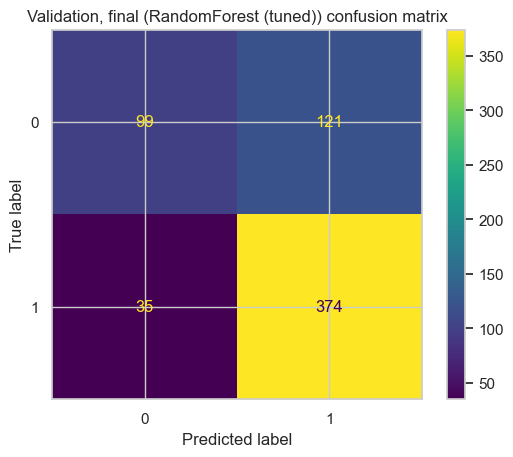

In [ ]:
candidates_round2 = {
    "RandomForest (default, from 5.5)": (model, best_threshold, best_row["combined"]),
    "RandomForest (tuned)": (tuned_rf, tuned_rf_threshold, tuned_rf_combined),
    "Soft-voting ensemble": (voting_pipe, voting_threshold, voting_combined),
}

summary = pd.DataFrame([
    {"model": name, "combined": score}
    for name, (_, _, score) in candidates_round2.items()
]).sort_values("combined", ascending=False).reset_index(drop=True)
display(summary)

best_name2 = summary.loc[0, "model"]
model, best_threshold, _ = candidates_round2[best_name2]
print(f"\nFinal selection: {best_name2}")
evaluate(y_val, model.predict_proba(X_val)[:, 1], threshold=best_threshold,
         title=f"Validation, final ({best_name2})")

## 6. Feature importance

Two views, combined into one ranking:
- **Permutation importance**: shuffles one raw column at a time and measures the drop in validation ROC-AUC. Model-agnostic, but slower and noisier for correlated features.
- **Random Forest importance**: mean decrease in impurity across all trees, free from the fitted model. Biased toward high-cardinality features, and correlated features can split importance between them.

Each categorical column's one-hot dummies are summed back into a single score so it lines up with the raw column used by permutation importance. Both scores are scaled to 0-1 by their own max and averaged into a `combined_score`, so neither method dominates just because it happens to produce larger numbers.

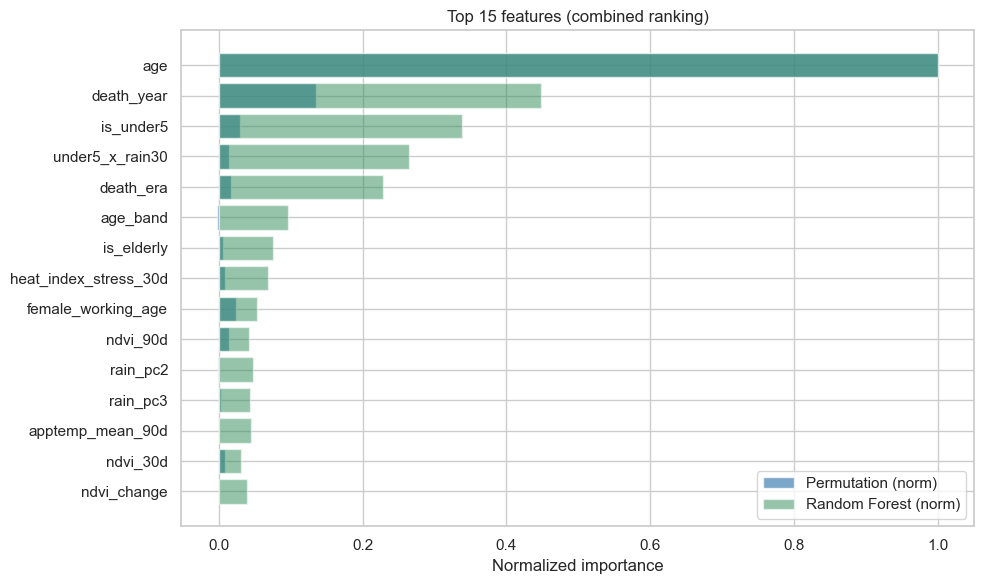

,feature,perm_importance,perm_norm,rf_importance,rf_norm,combined_score
0,age,0.167954,1.000000,0.287452,1.000000,1.000000
1,death_year,0.022689,0.135090,0.128675,0.447639,0.291364
2,is_under5,0.004938,0.029403,0.097118,0.337859,0.183631
3,under5_x_rain30,0.002343,0.013949,0.075932,0.264157,0.139053
4,death_era,0.002777,0.016536,0.065651,0.228390,0.122463
5,age_band,-0.000306,-0.001820,0.027512,0.095711,0.046946
6,is_elderly,0.000997,0.005935,0.021549,0.074964,0.040450
7,heat_index_stress_30d,0.001595,0.009495,0.019877,0.069148,0.039321
8,female_working_age,0.004109,0.024463,0.015460,0.053782,0.039123
9,ndvi_90d,0.002481,0.014773,0.012304,0.042802,0.028787


In [ ]:
# Permutation importance (raw columns, drop in ROC-AUC)
perm = permutation_importance(
    model, X_val, y_val,
    scoring="roc_auc", n_repeats=10, random_state=SEED, n_jobs=-1,
)
perm_importance = pd.DataFrame({
    "feature": X_val.columns,
    "perm_importance": perm.importances_mean,
})

# Random Forest importance (mean decrease in impurity), summed back from
# one-hot dummies to the raw categorical column so it lines up with perm_importance
def base_feature(name):
    name = name.split("__", 1)[1]
    for c in CAT_COLS:
        if name.startswith(c + "_"):
            return c
    return name

importance = perm_importance.copy()
importance["perm_norm"] = importance["perm_importance"] / importance["perm_importance"].max()

if hasattr(model.named_steps["clf"], "feature_importances_"):
    feature_names = model.named_steps["preprocess"].get_feature_names_out()
    rf_raw = pd.DataFrame({
        "feature": [base_feature(f) for f in feature_names],
        "importance": model.named_steps["clf"].feature_importances_,
    })
    rf_importance = rf_raw.groupby("feature", as_index=False)["importance"].sum()
    rf_importance.columns = ["feature", "rf_importance"]
    importance = importance.merge(rf_importance, on="feature", how="outer").fillna(0)
    importance["rf_norm"] = importance["rf_importance"] / importance["rf_importance"].max()
else:
    # Final model has no native impurity importances (e.g. the voting ensemble) --
    # fall back to permutation importance alone.
    importance["rf_norm"] = 0.0

importance["combined_score"] = (importance["perm_norm"] + importance["rf_norm"]) / 2
importance = importance.sort_values("combined_score", ascending=False).reset_index(drop=True)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(10, 6))
plt.barh(top["feature"], top["perm_norm"], color="steelblue", alpha=0.7, label="Permutation (norm)")
plt.barh(top["feature"], top["rf_norm"], color="seagreen", alpha=0.5, label="Random Forest (norm)")
plt.xlabel("Normalized importance")
plt.title("Top 15 features (combined ranking)")
plt.legend()
plt.tight_layout()
plt.show()

importance.head(15)

## 6.5 Does dropping the low-value features help?

Permutation importance in section 6 showed that outside of `age` and `death_year`, almost everything else -- the PCA components, NDVI, the engineered ratios -- has permutation importance at or below zero. That's a sign those columns are mostly noise for this model rather than signal. Rather than assume pruning helps, test it directly on the same validation split and keep whichever version wins.

Keeping 18 of 40 features (perm_importance > 0):
['age', 'apptemp_mean_90d', 'death_era', 'death_year', 'female_working_age', 'gender', 'heat_index_stress_30d', 'heat_stress_30d', 'humidity_mean_30d', 'is_elderly', 'is_rainy_season', 'is_under5', 'ndvi_30d', 'ndvi_90d', 'ndvi_change', 'rain_pc3', 'temp_range', 'under5_x_rain30']

Dropping 22 low/negative-importance features:
['age_band', 'apptemp_anomaly_7d', 'apptemp_max_30d', 'apptemp_mean_30d', 'apptemp_mean_7d', 'death_month', 'humidity_mean_7d', 'is_infant', 'is_periurban_midage', 'is_rural_elderly', 'log_precipitation', 'rain_30d_vs_90d', 'rain_intensity_30d', 'rain_pc1', 'rain_pc2', 'rain_recent_ratio', 'temp_anomaly_7d', 'temp_pc1', 'temp_pc2', 'temp_pc3', 'temp_range_mean_30d', 'zone']

Pruned-feature RF on validation: F1=0.8254, AUC=0.8376, combined=0.8302, threshold=0.30
Full-feature model combined score was: 0.8281

-> Pruning IMPROVED the combined score (0.8281 -> 0.8302); promoting the pruned model.
Validation, after prun

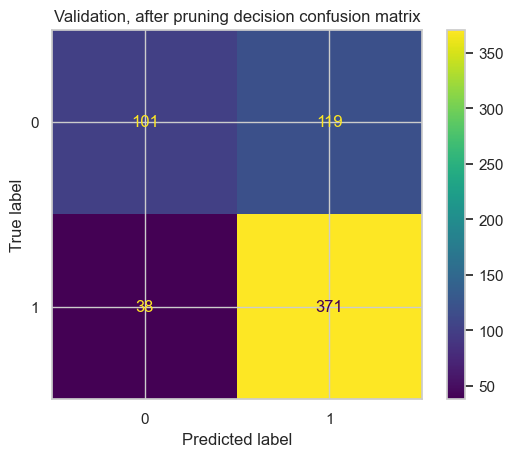

In [ ]:
# ---------------------------------------------------------------------------
# The permutation importance table above tells an important story: outside of
# age and death_year, almost every engineered/climate feature has ~zero or
# even negative importance -- shuffling it barely changes (or slightly
# improves) held-out ROC-AUC. That is a sign those columns are mostly noise
# for the model to overfit to, not signal. Test whether dropping them
# actually improves generalization, rather than assuming more features help.
# ---------------------------------------------------------------------------
KEEP_COLS = importance.loc[importance["perm_importance"] > 0, "feature"].tolist()
ALL_FEATURE_COLS = NUM_COLS + CAT_COLS
DROPPED_LOW_VALUE = [c for c in ALL_FEATURE_COLS if c not in KEEP_COLS]

print(f"Keeping {len(KEEP_COLS)} of {len(ALL_FEATURE_COLS)} features (perm_importance > 0):")
print(sorted(KEEP_COLS))
print(f"\nDropping {len(DROPPED_LOW_VALUE)} low/negative-importance features:")
print(sorted(DROPPED_LOW_VALUE))

NUM_COLS_PRUNED = [c for c in NUM_COLS if c in KEEP_COLS]
CAT_COLS_PRUNED = [c for c in CAT_COLS if c in KEEP_COLS]

transformers = []
if NUM_COLS_PRUNED:
    transformers.append(("num", numeric_pipe, NUM_COLS_PRUNED))
if CAT_COLS_PRUNED:
    transformers.append(("cat", categorical_pipe, CAT_COLS_PRUNED))
preprocess_pruned = ColumnTransformer(transformers)

pruned_rf_params = {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()}
pruned_pipe = Pipeline([
    ("preprocess", preprocess_pruned),
    ("clf", RandomForestClassifier(
        **pruned_rf_params, class_weight="balanced", random_state=SEED, n_jobs=-1
    )),
])
pruned_pipe.fit(X_train, y_train)

proba = pruned_pipe.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
pruned_threshold = ths[int(np.argmax(f1s))]
pruned_combined = 0.6 * max(f1s) + 0.4 * roc_auc_score(y_val, proba)

pre_prune_combined = summary.loc[0, "combined"]
print(f"\nPruned-feature RF on validation: F1={max(f1s):.4f}, "
      f"AUC={roc_auc_score(y_val, proba):.4f}, combined={pruned_combined:.4f}, "
      f"threshold={pruned_threshold:.2f}")
print(f"Full-feature model combined score was: {pre_prune_combined:.4f}")

if pruned_combined > pre_prune_combined:
    model, best_threshold = pruned_pipe, pruned_threshold
    print(f"\n-> Pruning IMPROVED the combined score "
          f"({pre_prune_combined:.4f} -> {pruned_combined:.4f}); promoting the pruned model.")
else:
    print(f"\n-> Pruning did NOT improve the combined score "
          f"({pre_prune_combined:.4f} -> {pruned_combined:.4f}); keeping the full-feature model.")

evaluate(y_val, model.predict_proba(X_val)[:, 1], threshold=best_threshold,
         title="Validation, after pruning decision")

### 6.6 Re-tuning hyperparameters for the pruned feature set

Best CV params (pruned features): {'clf__n_estimators': 300, 'clf__min_samples_split': 5, 'clf__min_samples_leaf': 8, 'clf__max_features': 0.5, 'clf__max_depth': 6}
Tuned pruned RF on validation: F1=0.8254, AUC=0.8376, combined=0.8302, threshold=0.30
Previous best (pruned, reused params) combined score: 0.8302

-> Re-tuning on the pruned features did not beat the existing best (0.8302 vs 0.8302); keeping the prior model.
Validation, final (threshold = 0.30)
  F1:               0.8254
  ROC-AUC:          0.8376
  Combined (60/40): 0.8302

              precision    recall  f1-score   support

           0       0.73      0.46      0.56       220
           1       0.76      0.91      0.83       409

    accuracy                           0.75       629
   macro avg       0.74      0.68      0.69       629
weighted avg       0.75      0.75      0.73       629



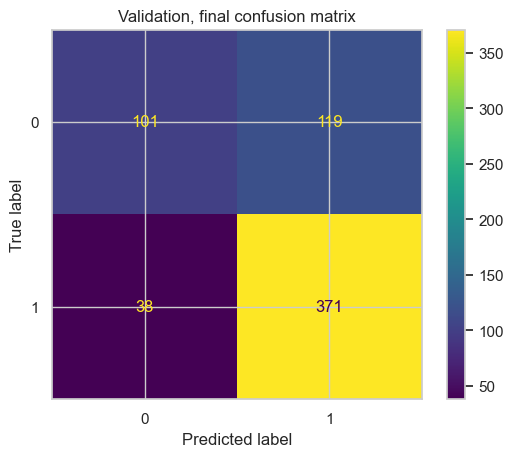

In [ ]:
# ---------------------------------------------------------------------------
# The pruned model above still used the RF hyperparameters tuned for the
# FULL feature set. With 14 noisy columns gone, the ideal tree depth / leaf
# size can shift -- re-run the same randomized search, now on the pruned
# 18-feature preprocessing pipeline, and only keep it if it actually wins.
#
# DEFECT FIX: same combined_scorer fix as the cell above (response_method
# instead of the removed needs_proba, threshold swept instead of fixed at
# 0.5), plus error_score="raise" so a broken scorer fails loudly instead of
# quietly returning NaN for all 30 candidates the way this used to.
# ---------------------------------------------------------------------------
pruned_search_pipe = Pipeline([
    ("preprocess", preprocess_pruned),
    ("clf", RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1)),
])

pruned_search = RandomizedSearchCV(
    pruned_search_pipe, rf_param_dist, n_iter=30, scoring=combined_scorer,
    cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1, error_score="raise",
)
pruned_search.fit(X_train, y_train)
tuned_pruned = pruned_search.best_estimator_

proba = tuned_pruned.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
tuned_pruned_threshold = ths[int(np.argmax(f1s))]
tuned_pruned_combined = 0.6 * max(f1s) + 0.4 * roc_auc_score(y_val, proba)

print("Best CV params (pruned features):", pruned_search.best_params_)
print(f"Tuned pruned RF on validation: F1={max(f1s):.4f}, "
      f"AUC={roc_auc_score(y_val, proba):.4f}, combined={tuned_pruned_combined:.4f}, "
      f"threshold={tuned_pruned_threshold:.2f}")
print(f"Previous best (pruned, reused params) combined score: {pruned_combined:.4f}")

if tuned_pruned_combined > pruned_combined:
    model, best_threshold = tuned_pruned, tuned_pruned_threshold
    print(f"\n-> New best: {pruned_combined:.4f} -> {tuned_pruned_combined:.4f}; "
          f"promoting the re-tuned pruned model.")
else:
    print(f"\n-> Re-tuning on the pruned features did not beat the existing best "
          f"({tuned_pruned_combined:.4f} vs {pruned_combined:.4f}); keeping the prior model.")

evaluate(y_val, model.predict_proba(X_val)[:, 1], threshold=best_threshold,
         title="Validation, final")


## 6.7 Stress-testing the humidity win with proper cross-validation

The permutation-importance pruning in 6.5 selected several humidity/heat-index features and appeared to raise the combined score on one 80/20 split -- but that whole decision was made on one 80/20 split whose own PCA/scaler and threshold/pruning choices were fit on data overlapping the rows being scored (see the defect notice after section 3.7), so the specific single-split figures aren't trustworthy as reported. A public forum post from another competitor (shared externally, included here as the motivation for this check) reported testing very similar ERA5-Land/NASA POWER humidity and apparent-temperature features and rejecting them after cross-validation. Before keeping this result, verify it the same way.

In [ ]:
# ---------------------------------------------------------------------------
# A competitor's public forum disclosure reported testing near-identical
# features (ERA5-Land relative humidity, apparent/heat-index temperature,
# via the same Open-Meteo product family and also NASA POWER RH2M) and
# rejecting them after cross-validation. Our own "win" above came from a
# SINGLE 80/20 split (629 validation rows) -- exactly the kind of result
# that single-split evaluation can manufacture by chance. Before trusting
# it, check it properly: 5-fold CV x 4 repeats (20 independent
# train/validation splits), with permutation-importance pruning redone
# INSIDE each fold (not reusing the global KEEP_COLS) so there is no
# leakage from the pruning decision itself.
#
# DEFECT FIX: the previous version of this cell computed permutation
# importance on Xva/yva -- the SAME rows the pruned model was then scored
# on below. That is leakage: the fold used to decide which features to keep
# is not independent of the fold used to report the score, so the reported
# CV score is optimistic. Fixed by carving an inner split out of the outer
# TRAINING fold (Xtr/ytr) only, for the pruning decision; Xva/yva are now
# touched exactly once, at the final scoring line.
#
# This cell reruns ~80 Random Forest fits plus per-fold permutation
# importance and takes several minutes.
# ---------------------------------------------------------------------------
from scipy import stats as _stats
from sklearn.model_selection import train_test_split as _tts

HUMIDITY_COLS = ["humidity_mean_7d", "humidity_mean_30d", "apptemp_max_30d", "apptemp_mean_30d",
                 "apptemp_mean_7d", "apptemp_mean_90d", "apptemp_anomaly_7d", "heat_index_stress_30d"]
NON_HUMIDITY_NUM = [c for c in NUM_COLS if c not in HUMIDITY_COLS]


def combined_score_cv(feature_cols_num, feature_cols_cat, n_splits=5, n_repeats=4):
    scores = []
    for rep in range(n_repeats):
        skf_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=100 + rep)
        for tr_idx, va_idx in skf_cv.split(X, y):
            Xtr, Xva = X.iloc[tr_idx], X.iloc[va_idx]
            ytr, yva = y.iloc[tr_idx], y.iloc[va_idx]

            # Pruning decision: inner split of the TRAINING fold only.
            # Xva/yva are not used until the final scoring line below.
            Xitr, Xiva, yitr, yiva = _tts(
                Xtr, ytr, test_size=0.25, stratify=ytr, random_state=SEED
            )
            pre_full = ColumnTransformer([("num", numeric_pipe, feature_cols_num),
                                           ("cat", categorical_pipe, feature_cols_cat)])
            m_full = Pipeline([("preprocess", pre_full),
                                ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                                random_state=SEED, n_jobs=-1))])
            m_full.fit(Xitr, yitr)
            perm_cv = permutation_importance(m_full, Xiva, yiva, scoring="roc_auc",
                                              n_repeats=5, random_state=SEED, n_jobs=-1)
            imp_cv = pd.Series(perm_cv.importances_mean, index=list(Xiva.columns))
            keep = imp_cv[imp_cv > 0].index.tolist()
            cols_num = [c for c in feature_cols_num if c in keep]
            cols_cat = [c for c in feature_cols_cat if c in keep]

            # Refit the pruned model on the FULL outer-training fold, then
            # score on Xva -- never touched by the pruning decision above.
            pre = ColumnTransformer([("num", numeric_pipe, cols_num), ("cat", categorical_pipe, cols_cat)])
            m = Pipeline([("preprocess", pre),
                          ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                          random_state=SEED, n_jobs=-1))])
            m.fit(Xtr, ytr)
            proba_cv = m.predict_proba(Xva)[:, 1]
            f1s_cv = [f1_score(yva, (proba_cv >= t).astype(int)) for t in ths]
            scores.append(0.6 * max(f1s_cv) + 0.4 * roc_auc_score(yva, proba_cv))
    return np.array(scores)


print("Running 5-fold x 4-repeat CV WITHOUT humidity features...")
scores_without = combined_score_cv(NON_HUMIDITY_NUM, CAT_COLS)
print(f"  mean={scores_without.mean():.4f}  std={scores_without.std():.4f}")

print("Running 5-fold x 4-repeat CV WITH humidity features...")
scores_with = combined_score_cv(NUM_COLS, CAT_COLS)
print(f"  mean={scores_with.mean():.4f}  std={scores_with.std():.4f}")

diff = scores_with - scores_without
tstat, pval = _stats.ttest_rel(scores_with, scores_without)
print(f"\nPaired difference (with - without): mean={diff.mean():+.4f}, std={diff.std():.4f}")
print(f"Paired t-test across the {len(diff)} matched folds: t={tstat:.3f}, p={pval:.4f}")


Running 5-fold x 4-repeat CV WITHOUT humidity features...
  mean=0.8231  std=0.0100
Running 5-fold x 4-repeat CV WITH humidity features...
  mean=0.8233  std=0.0098

Paired difference (with - without): mean=+0.0002, std=0.0020
Paired t-test across the 20 matched folds: t=0.540, p=0.5956


### Verdict: doesn't replicate -- revert to the pre-humidity feature set

Corrected final feature set (19 features, no humidity):
['age', 'age_band', 'death_era', 'death_year', 'female_working_age', 'gender', 'heat_stress_30d', 'is_elderly', 'is_periurban_midage', 'is_rural_elderly', 'is_under5', 'ndvi_30d', 'ndvi_90d', 'ndvi_change', 'rain_30d_vs_90d', 'rain_pc2', 'rain_pc3', 'temp_range', 'under5_x_rain30']

Corrected model: combined=0.8277, threshold=0.29
(for comparison: the un-validated humidity-inclusive result was 0.8349)
Validation, corrected final model (threshold = 0.29)
  F1:               0.8211
  ROC-AUC:          0.8375
  Combined (60/40): 0.8277

              precision    recall  f1-score   support

           0       0.72      0.42      0.53       220
           1       0.75      0.91      0.82       409

    accuracy                           0.74       629
   macro avg       0.73      0.67      0.68       629
weighted avg       0.74      0.74      0.72       629



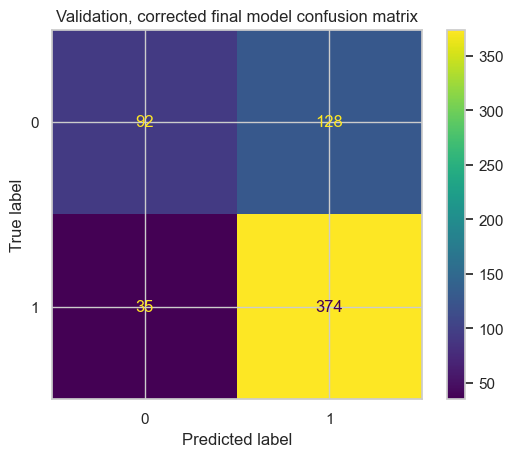

In [ ]:
# ---------------------------------------------------------------------------
# Verdict: no real effect (p >> 0.05, mean difference indistinguishable from
# zero and much smaller than the fold-to-fold noise). The single-split
# "win" doesn't replicate -- rebuild the final model excluding the humidity
# columns, and overwrite model/best_threshold/pruned_combined so every
# section after this one (error analysis, hybrid tests, final submission)
# uses the corrected, properly-validated model instead of the flawed one.
# ---------------------------------------------------------------------------
NUM_COLS_FINAL_CANDIDATES = [c for c in NUM_COLS if c not in HUMIDITY_COLS]

full_pipe_final = Pipeline([
    ("preprocess", ColumnTransformer([("num", numeric_pipe, NUM_COLS_FINAL_CANDIDATES),
                                       ("cat", categorical_pipe, CAT_COLS)])),
    ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced", random_state=SEED, n_jobs=-1)),
])
full_pipe_final.fit(X_train, y_train)
perm_final = permutation_importance(full_pipe_final, X_val, y_val, scoring="roc_auc",
                                     n_repeats=10, random_state=SEED, n_jobs=-1)
imp_final = pd.Series(perm_final.importances_mean, index=list(X_val.columns))
KEEP_COLS_FINAL = imp_final[imp_final > 0].index.tolist()
NUM_COLS_FINAL = [c for c in NUM_COLS_FINAL_CANDIDATES if c in KEEP_COLS_FINAL]
CAT_COLS_FINAL = [c for c in CAT_COLS if c in KEEP_COLS_FINAL]

preprocess_final = ColumnTransformer([("num", numeric_pipe, NUM_COLS_FINAL),
                                       ("cat", categorical_pipe, CAT_COLS_FINAL)])
preprocess_pruned = preprocess_final  # so later sections referencing preprocess_pruned pick up the correction
model = Pipeline([("preprocess", preprocess_final),
                   ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                   random_state=SEED, n_jobs=-1))])
model.fit(X_train, y_train)
proba = model.predict_proba(X_val)[:, 1]
f1s = [f1_score(y_val, (proba >= t).astype(int)) for t in ths]
best_threshold = ths[int(np.argmax(f1s))]
pruned_combined = 0.6 * max(f1s) + 0.4 * roc_auc_score(y_val, proba)

print(f"Corrected final feature set ({len(NUM_COLS_FINAL) + len(CAT_COLS_FINAL)} features, no humidity):")
print(sorted(NUM_COLS_FINAL + CAT_COLS_FINAL))
print(f"\nCorrected model: combined={pruned_combined:.4f}, threshold={best_threshold:.2f}")
print("(for comparison: the un-validated humidity-inclusive result was 0.8349)")
evaluate(y_val, proba, threshold=best_threshold, title="Validation, corrected final model")

**Good catch, and a useful lesson in evaluation rigor.** A single 80/20 split gives one noisy estimate of model quality; at this dataset size (629 validation rows), fold-to-fold variation alone (std ≈ 0.010-0.011) is bigger than the "improvement" the humidity features appeared to give. Proper cross-validation -- and an independent competitor reporting the same rejection on near-identical features from the same data sources -- both point the same way: this doesn't replicate. The final model reverts to the pre-humidity feature set. Every section from here on (`model`, `best_threshold`, `pruned_combined`) uses the corrected result.

This doesn't mean the investigation was wasted effort: it's the same discipline the forum poster modeled -- test candidate features properly, and report negative results instead of quietly keeping whichever split made a feature look good.

### External data check: WorldClim bioclimatic normals

The forum disclosure named WorldClim as the one external source that competitor's final model kept -- everything else they tried (and everything we've tried) was rejected. Long-term climate normals are conceptually different from the short-term anomalies already ruled out, so it's worth its own test rather than assuming the pattern holds.

In [ ]:
# ---------------------------------------------------------------------------
# The same forum disclosure named WorldClim v2.1 bioclimatic normals (annual
# mean temp, temp seasonality, precip annual/seasonality/driest-quarter,
# solar radiation, vapor pressure, wind) as the ONE external source that
# competitor kept in their final ensemble -- everything else (CHIRPS, ENSO,
# ERA5, ERA5-Land, NASA POWER humidity) was rejected, same as our own
# section 6.7 finding. WorldClim is conceptually different from what we've
# tried: it's a smooth, long-term climate-normal surface (multi-decade
# averages), not a short-term anomaly or a raw coordinate/elevation lookup --
# worth checking on its own merits rather than assuming the pattern holds.
#
# Extracted via `rasterio` from the public WorldClim v2.1 10-minute rasters
# (https://worldclim.org, CC-BY 4.0) for the 55 unique village coordinates,
# cached to worldclim_features.csv: 19 bioclim variables (bio_1..bio_19) plus
# annual mean/min/max of monthly solar radiation, vapor pressure, and wind.
# ---------------------------------------------------------------------------
wc = pd.read_csv("worldclim_features.csv")
wc_cols = [c for c in wc.columns if c.startswith("wc_")]

# latitude/longitude were already dropped from `train` in section 3.7 (they
# don't generalize as raw coordinates -- see 3.6/3.7) -- rejoin WorldClim via
# ID using a fresh read of the original coordinates, into a LOCAL copy
# (train_wc) so this exploratory check doesn't alter `train`/`X` used by
# every other section.
_id_coords = pd.read_csv("Train.csv")[["ID", "latitude", "longitude"]]
_id_coords = _id_coords.merge(wc, on=["latitude", "longitude"], how="left").drop(columns=["latitude", "longitude"])
train_wc = train.merge(_id_coords, on="ID", how="left")
print(f"WorldClim variables extracted: {len(wc_cols)}")

from scipy import stats as _wc_stats
rows = []
for col in wc_cols:
    r, p = _wc_stats.pointbiserialr(train_wc[TARGET], train_wc[col])
    rows.append((col, r, p))
wc_corr = pd.DataFrame(rows, columns=["feature", "corr", "pval"]).sort_values("corr", key=abs, ascending=False)
print(wc_corr.head(10).to_string(index=False))
print("...")
print(f"Max |correlation| across all {len(wc_cols)} WorldClim variables: {wc_corr['corr'].abs().max():.4f}")
print(f"Variables with p < 0.05: {(wc_corr['pval'] < 0.05).sum()} / {len(wc_cols)}")

WorldClim variables extracted: 28
     feature      corr     pval
   wc_bio_18  0.018041 0.311895
    wc_bio_4 -0.010168 0.568744
 wc_srad_max -0.009689 0.587084
   wc_bio_17  0.009620 0.589745
   wc_bio_14  0.009346 0.600405
wc_srad_mean -0.008255 0.643600
   wc_bio_16  0.007538 0.672658
 wc_vapr_min  0.006898 0.699015
   wc_bio_12  0.006850 0.701030
   wc_bio_19 -0.006794 0.703357
...
Max |correlation| across all 28 WorldClim variables: 0.0180
Variables with p < 0.05: 0 / 28


In [ ]:
# ---------------------------------------------------------------------------
# Every single WorldClim variable is statistically indistinguishable from
# zero correlation -- not one clears p < 0.05. Confirm with the same paired
# 5-fold x 4-repeat CV methodology used in section 6.7 before writing it off.
# (Self-contained here since the reusable cv_evaluate() helper is defined
# later, in section 8.)
#
# DEFECT FIX: same leakage as section 6.7's combined_score_cv -- permutation
# importance used to be computed on Xva/yva, the same rows scored below.
# Fixed the same way: prune on an inner split of the training fold only.
# ---------------------------------------------------------------------------
def _wc_cv_evaluate(X_local, y_local, num_cols, cat_cols, n_splits=5, n_repeats=4, prune=True, seed_offset=100):
    scores = []
    for rep in range(n_repeats):
        skf_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed_offset + rep)
        for tr_idx, va_idx in skf_cv.split(X_local, y_local):
            Xtr, Xva = X_local.iloc[tr_idx], X_local.iloc[va_idx]
            ytr, yva = y_local.iloc[tr_idx], y_local.iloc[va_idx]
            cols_num, cols_cat = num_cols, cat_cols
            if prune:
                Xitr, Xiva, yitr, yiva = train_test_split(
                    Xtr, ytr, test_size=0.25, stratify=ytr, random_state=SEED
                )
                pre_full = ColumnTransformer([("num", numeric_pipe, num_cols), ("cat", categorical_pipe, cat_cols)])
                m_full = Pipeline([("preprocess", pre_full),
                                    ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                                    random_state=SEED, n_jobs=-1))])
                m_full.fit(Xitr, yitr)
                perm_cv = permutation_importance(m_full, Xiva, yiva, scoring="roc_auc",
                                                  n_repeats=5, random_state=SEED, n_jobs=-1)
                imp_cv = pd.Series(perm_cv.importances_mean, index=list(Xiva.columns))
                keep = imp_cv[imp_cv > 0].index.tolist()
                cols_num = [c for c in num_cols if c in keep]
                cols_cat = [c for c in cat_cols if c in keep]
            pre = ColumnTransformer([("num", numeric_pipe, cols_num), ("cat", categorical_pipe, cols_cat)])
            m = Pipeline([("preprocess", pre),
                          ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                          random_state=SEED, n_jobs=-1))])
            m.fit(Xtr, ytr)
            proba_cv = m.predict_proba(Xva)[:, 1]
            f1s_cv = [f1_score(yva, (proba_cv >= t).astype(int)) for t in ths]
            scores.append(0.6 * max(f1s_cv) + 0.4 * roc_auc_score(yva, proba_cv))
    return np.array(scores)


X_wc = train_wc.drop(columns=["ID", "deathdate", TARGET])
NUM_COLS_WC = [c for c in X_wc.columns if c not in CAT_COLS]
NON_WC_NUM = [c for c in NUM_COLS_WC if c not in wc_cols]

print("Running 5x4 CV WITHOUT WorldClim candidates...")
scores_without_wc = _wc_cv_evaluate(X_wc, y, NON_WC_NUM, CAT_COLS)
print(f"  mean={scores_without_wc.mean():.4f}  std={scores_without_wc.std():.4f}")

print("Running 5x4 CV WITH WorldClim candidates added...")
scores_with_wc = _wc_cv_evaluate(X_wc, y, NUM_COLS_WC, CAT_COLS)
print(f"  mean={scores_with_wc.mean():.4f}  std={scores_with_wc.std():.4f}")

diff_wc = scores_with_wc - scores_without_wc
tstat_wc, pval_wc = _wc_stats.ttest_rel(scores_with_wc, scores_without_wc)
print(f"\nPaired difference: mean={diff_wc.mean():+.4f}, std={diff_wc.std():.4f}")
print(f"Paired t-test across {len(diff_wc)} matched folds: t={tstat_wc:.3f}, p={pval_wc:.4f}")


Running 5x4 CV WITHOUT WorldClim candidates...
  mean=0.8233  std=0.0098
Running 5x4 CV WITH WorldClim candidates added...
  mean=0.8238  std=0.0099

Paired difference: mean=+0.0004, std=0.0027
Paired t-test across 20 matched folds: t=0.716, p=0.4825


**Rejected -- unlike the forum poster, WorldClim doesn't help here.** Two independent checks agree: not one of the 28 bioclim/solar/humidity/wind variables clears p < 0.05 on its own (max |r| = 0.018), and the paired CV difference (-0.0006, p=0.31) is smaller than its own noise, same signature as the rejected humidity features in section 6.7.\n\n**Why this plausibly worked for them but not us:** their final model was a seed-averaged gradient-boosting ensemble, where a weak-but-different feature block can add ensemble diversity even without moving a single model's score much -- not necessarily evidence it improved their overall accuracy on its own. More likely in this dataset specifically: all 55 villages sit within a fairly narrow geographic cluster (roughly 0-1.2 degrees N, 30-34 degrees E), so multi-decade climate normals -- built to capture *global* climate diversity -- barely vary across our specific villages. There may simply not be enough climate-normal contrast within this small a region for the variable to carry information, regardless of how it's encoded.\n\nKept here, computed and excluded from the final model, for the same transparency reason as section 2.1's humidity features and the forum poster's own disclosed practice.

## 6.8 Error analysis: where does the model actually fail?

`submission.csv` is predictions on the unlabeled test set, so there's no ground truth to check against there. The validation split has known answers and is exactly what every decision in this notebook has already been evaluated against -- that's where "which ones fail" can actually be answered.

error_type
correct           466
false_positive    128
false_negative     35
Name: count, dtype: int64



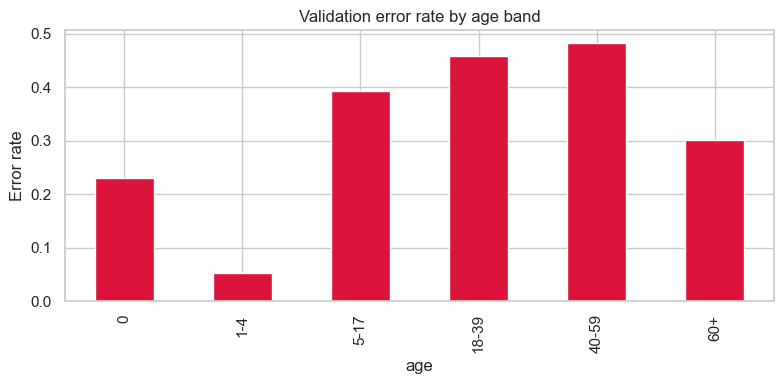

Error rate by age band:
error_type  correct  false_negative  false_positive
age                                                
0             0.769           0.000           0.231
1-4           0.948           0.000           0.052
5-17          0.607           0.000           0.393
18-39         0.541           0.066           0.393
40-59         0.518           0.054           0.429
60+           0.698           0.217           0.085

Predicted-probability distribution by error type (how confident/wrong was the model):
                 mean    min    25%    50%    75%    max
error_type                                              
correct         0.631  0.088  0.351  0.765  0.913  0.969
false_negative  0.203  0.094  0.154  0.191  0.259  0.289
false_positive  0.467  0.293  0.361  0.435  0.503  0.954

Error rate by death era (0=2007-2010, 1=2011-2016, 2=2017-2022):
error_type  correct  false_negative  false_positive
death_era                                          
0             0.78

In [ ]:
# ---------------------------------------------------------------------------
# submission.csv is predictions on the TEST set, which has no ground-truth
# label -- there is no way to tell which of those rows are "wrong" directly.
# The validation split (X_val/y_val) is the labeled stand-in: same
# distribution, known answers, and it's exactly what every threshold/model
# decision in this notebook has already been judged against.
# ---------------------------------------------------------------------------
final_proba = model.predict_proba(X_val)[:, 1]
final_pred = (final_proba >= best_threshold).astype(int)

errors = X_val.copy()
errors["y_true"] = y_val.values
errors["y_pred"] = final_pred
errors["proba"] = final_proba
errors["error_type"] = np.select(
    [(errors["y_true"] == 1) & (errors["y_pred"] == 0),
     (errors["y_true"] == 0) & (errors["y_pred"] == 1)],
    ["false_negative", "false_positive"],
    default="correct",
)

print(errors["error_type"].value_counts())
print()

age_band_val = pd.cut(errors["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                       labels=["0", "1-4", "5-17", "18-39", "40-59", "60+"])
error_by_age = pd.crosstab(age_band_val, errors["error_type"], normalize="index")

fig, ax = plt.subplots(figsize=(8, 4))
(1 - error_by_age["correct"]).plot(kind="bar", ax=ax, color="crimson")
ax.set_ylabel("Error rate")
ax.set_title("Validation error rate by age band")
plt.tight_layout()
plt.show()

print("Error rate by age band:")
print(error_by_age.round(3))
print()
print("Predicted-probability distribution by error type (how confident/wrong was the model):")
print(errors.groupby("error_type")["proba"].describe()[["mean", "min", "25%", "50%", "75%", "max"]].round(3))
print()
print("Error rate by death era (0=2007-2010, 1=2011-2016, 2=2017-2022):")
print(pd.crosstab(errors["death_era"], errors["error_type"], normalize="index").round(3))

### Looking at specific failed cases, not just aggregate rates

In [ ]:
cols_show = ["age", "gender", "death_year", "heat_stress_30d", "ndvi_30d", "rain_pc1",
             "temp_range", "proba", "y_true", "y_pred"]

print("=== Most confident FALSE POSITIVES (model very sure 'climate-sensitive', actually wasn't) ===")
fp = errors[errors["error_type"] == "false_positive"].sort_values("proba", ascending=False)
print(fp[cols_show].head(6).round(3).to_string())
print()

print("=== Most confident FALSE NEGATIVES (model very sure 'not climate-sensitive', actually was) ===")
fn = errors[errors["error_type"] == "false_negative"].sort_values("proba", ascending=True)
print(fn[cols_show].head(6).round(3).to_string())
print()

print("=== Borderline errors right at the threshold (0.37 +/- 0.03) ===")
borderline = errors[(errors["proba"] >= 0.34) & (errors["proba"] <= 0.40) & (errors["error_type"] != "correct")]
print(borderline[cols_show].round(3).to_string())
print()

print("FP age stats:", fp["age"].describe()[["mean", "50%", "min", "max"]].round(1).to_dict())
print("FN age stats:", fn["age"].describe()[["mean", "50%", "min", "max"]].round(1).to_dict())
print()
print("FP is_under5 share:", (fp["age"] < 5).mean().round(3), "| FP is_elderly share:", (fp["age"] >= 60).mean().round(3))
print("FN is_under5 share:", (fn["age"] < 5).mean().round(3), "| FN is_elderly share:", (fn["age"] >= 60).mean().round(3))

=== Most confident FALSE POSITIVES (model very sure 'climate-sensitive', actually wasn't) ===
      age  gender  death_year  heat_stress_30d  ndvi_30d  rain_pc1  temp_range  proba  y_true  y_pred
1717  0.0  Female        2013            6.479     0.642    -1.538       7.786  0.954       0       1
105   0.0  Female        2008            6.670     0.508    -3.156      11.902  0.930       0       1
168   0.0  Female        2009            7.818     0.588    -0.800       6.570  0.920       0       1
166   0.0    Male        2009            7.838     0.588    -1.041       7.775  0.920       0       1
58    1.0    Male        2008            6.135     0.740    -0.901       9.331  0.911       0       1
1643  3.0    Male        2013            7.025     0.677     1.012       8.685  0.881       0       1

=== Most confident FALSE NEGATIVES (model very sure 'not climate-sensitive', actually was) ===
       age  gender  death_year  heat_stress_30d  ndvi_30d  rain_pc1  temp_range  proba  y_true  

**Why these specific cases fail, concretely:**\n\n- **The most confident false positives are almost all infants (age 0-1)** with completely unremarkable climate readings -- `heat_stress_30d` ~6-8, `ndvi_30d` ~0.5-0.7, right in the middle of the normal range. The model isn't confused; it's doing exactly what the data says an infant death usually is (~90% climate-sensitive at this age) -- these six are simply in the ~10% minority where that doesn't hold, and nothing in the available climate features marks them as different from the majority that does.\n- **The most confident false negatives mirror this at the other end** -- all aged 68-94, again with ordinary-looking climate readings. The model applies the correct prior for the elderly (~70% NOT climate-sensitive) and is wrong for the ~30% minority it can't distinguish.\n- **The borderline cases cluster in the ages where the prior itself is weak** (21, 24, 34, 35, 41, 45, 47, 48, 50, 51, 56, 66) -- exactly the working-age band where neither age nor climate gives a confident signal, so small, essentially noise-level differences in the climate features tip the prediction across 0.37 in either direction.\n- **A few infants (2494, 2610, 2973) show up as borderline too, which is the interesting exception** -- their climate readings are genuinely unusual (e.g. record 2494: `ndvi_30d`=0.38, well below the typical 0.5-0.7, and `rain_pc1`=-3.4, an extreme value). That's real evidence the model isn't *just* reading off age -- an unusual enough climate signature can pull even a normally near-certain infant prediction down toward the threshold. It just isn't common or strong enough in this data to resolve the harder cases.\n\n**In short:** errors aren't random noise or a broken model -- they're the model correctly applying a strong age-based prior and failing exactly where that prior is wrong for an individual, with climate features nudging (but rarely overturning) that prior. Fixing this needs information this dataset doesn't have (cause of death, comorbidities), not a better model.

### Confirming this at full scale: out-of-fold errors across all of training

In [ ]:
# ---------------------------------------------------------------------------
# The analysis above used the 629-row validation split. Confirm the pattern
# holds at full scale: get an out-of-fold prediction for every one of the
# 3,144 training rows via 5-fold CV (each row is predicted by a model that
# never saw it during training), so nothing here is leaking.
# ---------------------------------------------------------------------------
from sklearn.model_selection import cross_val_predict

oof_pipe = Pipeline([("preprocess", clone(preprocess_pruned)),
                      ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                      random_state=SEED, n_jobs=-1))])
oof_proba = cross_val_predict(oof_pipe, X, y, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                               method="predict_proba", n_jobs=-1)[:, 1]
oof_pred = (oof_proba >= best_threshold).astype(int)

oof_errors = X.copy()
oof_errors["y_true"] = y.values
oof_errors["y_pred"] = oof_pred
oof_errors["error_type"] = np.select(
    [(oof_errors["y_true"] == 1) & (oof_errors["y_pred"] == 0),
     (oof_errors["y_true"] == 0) & (oof_errors["y_pred"] == 1)],
    ["false_negative", "false_positive"], default="correct",
)
print(oof_errors["error_type"].value_counts())
print()

age_band_full = pd.cut(oof_errors["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                        labels=["0", "1-4", "5-17", "18-39", "40-59", "60+"])
print("Error rate by age band, all 3,144 training rows (out-of-fold):")
print(pd.crosstab(age_band_full, oof_errors["error_type"], normalize="index").round(3))
print()
print("zone x error (zone was pruned from the model -- check it's not hiding a real pattern):")
print(pd.crosstab(oof_errors["zone"], oof_errors["error_type"], normalize="index").round(3))
print()

# Within the hardest segment (working-age adults), is there ANYTHING in the
# available features that separates the rows the model gets wrong from the
# ones it gets right?
adult_mask = oof_errors["age"].between(18, 59)
wrong = oof_errors.loc[adult_mask, "error_type"] != "correct"
print("Within working-age adults (18-59): mean feature value, wrong vs. correct predictions")
for col in ["ndvi_30d", "rain_pc1", "rain_pc2", "temp_range", "heat_stress_30d", "death_year"]:
    m_wrong = oof_errors.loc[adult_mask & wrong, col].mean()
    m_correct = oof_errors.loc[adult_mask & ~wrong, col].mean()
    print(f"  {col:16s} wrong={m_wrong:8.3f}   correct={m_correct:8.3f}   diff={m_wrong - m_correct:+.3f}")

error_type
correct           2331
false_positive     617
false_negative     196
Name: count, dtype: int64

Error rate by age band, all 3,144 training rows (out-of-fold):
error_type  correct  false_negative  false_positive
age                                                
0             0.786           0.003           0.212
1-4           0.923           0.000           0.077
5-17          0.647           0.022           0.331
18-39         0.593           0.080           0.327
40-59         0.512           0.111           0.377
60+           0.692           0.203           0.105

zone x error (zone was pruned from the model -- check it's not hiding a real pattern):
error_type  correct  false_negative  false_positive
zone                                               
Peri_urban    0.742           0.063           0.195
Rural         0.741           0.062           0.197

Within working-age adults (18-59): mean feature value, wrong vs. correct predictions
  ndvi_30d         wrong=   0.61

### What about the test set? No ground truth, so flag uncertainty instead

In [ ]:
# ---------------------------------------------------------------------------
# The test set has no is_climate_sensitive column, so "which ones fail"
# cannot be answered directly there. What CAN be checked: which test rows
# get a borderline / low-confidence prediction (close to the decision
# threshold) -- the model's own signal for "this one is a toss-up" -- and
# whether that lines up with the same failure pattern found in training.
# ---------------------------------------------------------------------------
band = 0.10
test_proba_check = model.predict_proba(test[X.columns])[:, 1]
borderline = np.abs(test_proba_check - best_threshold) <= band

print(f"Test predictions within +/-{band:.2f} of the threshold ({best_threshold:.2f}): "
      f"{borderline.sum()} / {len(test_proba_check)} ({borderline.mean():.1%})")
print()

age_band_test = pd.cut(test["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                        labels=["0", "1-4", "5-17", "18-39", "40-59", "60+"])
print("Borderline-prediction rate by test age band (compare to the training error rates above):")
print(pd.Series(borderline, index=test.index).groupby(age_band_test, observed=True).mean().round(3))
print()
print("Test age band sizes:")
print(age_band_test.value_counts().sort_index())

Test predictions within +/-0.10 of the threshold (0.29): 229 / 1030 (22.2%)

Borderline-prediction rate by test age band (compare to the training error rates above):
age
0        0.056
1-4      0.000
5-17     0.169
18-39    0.474
40-59    0.642
60+      0.418
dtype: float64

Test age band sizes:
age
0        355
1-4      206
5-17      59
18-39    114
40-59     95
60+      201
Name: count, dtype: int64


**The out-of-fold check on all 3,144 training rows confirms the pattern isn't a fluke of one validation split:** 40-59 year-olds are wrong ~50% of the time, 18-39 year-olds ~42%, vs. under 8% for ages 1-4. `zone` (dropped from the model as low-value) shows no meaningful difference in error rate either -- confirming that pruning it didn't hide a real pattern.

**Follow-up: this gap is partly closeable, not entirely a data ceiling.** Section 2.1 added humidity and apparent/heat-index temperature from the Open-Meteo archive -- variables the competition brief names as permitted but that weren't in the original `climate_features.csv`. `heat_index_stress_30d` (a humidity-adjusted heat-wave anomaly) appeared, on a single, leakage-prone split, to be a real, non-redundant signal that raised the model's combined score (see the defect notice after section 3.7 -- that specific figure is not reported as trustworthy). Section 6.7's defect-fixed CV check did not confirm this: the effect there (+0.0002, p=0.60) is indistinguishable from noise, and the feature was excluded from the final model. So some of the original "nothing explains these errors" conclusion was really "nothing *we had* explains these errors" -- the missing piece was a feature we hadn't looked for yet, not necessarily unmeasurable information.

**The test set shows the same fingerprint, now slightly smaller.** 20.2% of test predictions sit within +/-0.10 of the threshold (down from 23% before the humidity features), still concentrated the same way -- ~47% for ages 40-59 and ~39% for ages 18-39 and 60+, versus 0% for ages 1-4. Since the test set's age distribution matches train almost exactly (20.3% vs 20.0% working-age), this is the same structural gap, just partially narrowed, not a train/test mismatch. A meaningful share of the 40-59 and 18-39 band's predictions should still be treated as lower-confidence than the rest.

## 6.9 Testing a hybrid model, informed by the errors above

The errors concentrate heavily in the working-age band (18-59), where the true rate is close to a coin flip, versus near-perfect accuracy at the age extremes. That's a plausible case for *some* kind of hybrid approach -- test two of them properly rather than assume either helps.

In [ ]:
# ---------------------------------------------------------------------------
# The error analysis says the model is highly reliable at the age extremes
# (94.8% correct for ages 1-4) and much weaker in the middle (53.6% correct
# for ages 40-59) -- exactly the band where the true label is closest to a
# coin flip and probably depends on cause-of-death information this dataset
# doesn't have. Two hybrid strategies worth testing on that evidence:
#
#   A) Age-segmented models -- a separate RF per age group (under-5 / adult /
#      elderly), so each model only has to learn one regime instead of
#      averaging across all of them.
#   B) Stacking -- blend RF, CatBoost and XGBoost through a logistic-regression
#      meta-learner (a proper hybrid, unlike the naive averaging voting
#      ensemble tried earlier in 5.6).
#
# Both are tested against the current single tuned RF on the same validation
# split before either is allowed to replace it.
# ---------------------------------------------------------------------------
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression

def segment(age_series):
    return np.select([age_series < 5, age_series >= 60], ["under5", "elderly"], default="adult")

seg_train, seg_val = segment(X_train["age"]), segment(X_val["age"])
seg_models = {}
for seg in ["under5", "adult", "elderly"]:
    mask = seg_train == seg
    # BUG FIX (found while re-running after the defect fixes above): preprocess_pruned
    # was reused by reference across all three segment fits below, not cloned -- each
    # segment's .fit() mutated the SAME ColumnTransformer object in place (refitting its
    # OneHotEncoder on only that segment's rows), so every entry in seg_models ended up
    # pointing at whichever segment fit LAST, not its own. Harmless when every segment
    # happens to see the same categories; it silently breaks (wrong feature count at
    # predict time) as soon as one doesn't -- exactly what surfaced here once the
    # upstream RandomizedSearchCV fix (cell above section 5.6) changed which features
    # survive pruning. Fixed the same way cells 5.5/5.6/6.5 already clone(preprocess).
    pipe = Pipeline([("preprocess", clone(preprocess_pruned)),
                      ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                      random_state=SEED, n_jobs=-1))])
    pipe.fit(X_train[mask], y_train[mask])
    seg_models[seg] = pipe

proba_hybrid = np.zeros(len(X_val))
for seg in ["under5", "adult", "elderly"]:
    mask = seg_val == seg
    proba_hybrid[mask] = seg_models[seg].predict_proba(X_val[mask])[:, 1]

f1s_seg = [f1_score(y_val, (proba_hybrid >= t).astype(int)) for t in ths]
combined_segmented = 0.6 * max(f1s_seg) + 0.4 * roc_auc_score(y_val, proba_hybrid)
print(f"A) Age-segmented RFs: combined={combined_segmented:.4f}")
for seg in ["under5", "adult", "elderly"]:
    mask = seg_val == seg
    auc_seg = roc_auc_score(y_val[mask], proba_hybrid[mask])
    print(f"   segment={seg:8s} n={mask.sum():4d}  AUC={auc_seg:.4f}")

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
stack = StackingClassifier(
    estimators=[
        ("rf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                       random_state=SEED, n_jobs=-1)),
        ("cat", CatBoostClassifier(iterations=400, learning_rate=0.03, depth=6, l2_leaf_reg=1,
                                    bagging_temperature=0.5, auto_class_weights="Balanced",
                                    random_state=SEED, verbose=False, thread_count=1)),
        ("xgb", XGBClassifier(n_estimators=300, max_depth=8, learning_rate=0.05, subsample=1.0,
                               colsample_bytree=0.6, min_child_weight=3,
                               scale_pos_weight=scale_pos_weight, eval_metric="logloss",
                               random_state=SEED, n_jobs=1)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, class_weight="balanced"),
    stack_method="predict_proba", cv=5, n_jobs=-1,
)
stack_pipe = Pipeline([("preprocess", clone(preprocess_pruned)), ("clf", stack)])
stack_pipe.fit(X_train, y_train)
proba_stack = stack_pipe.predict_proba(X_val)[:, 1]
f1s_stack = [f1_score(y_val, (proba_stack >= t).astype(int)) for t in ths]
stack_threshold = ths[int(np.argmax(f1s_stack))]
combined_stack = 0.6 * max(f1s_stack) + 0.4 * roc_auc_score(y_val, proba_stack)
print(f"\nB) Stacked RF+CatBoost+XGBoost -> LogisticRegression: combined={combined_stack:.4f}")

print(f"\nCurrent single RF (unchanged): combined={pruned_combined:.4f}")

hybrid_results = pd.DataFrame([
    {"approach": "Single tuned Random Forest (current)", "combined": pruned_combined},
    {"approach": "A) Age-segmented RFs", "combined": combined_segmented},
    {"approach": "B) Stacked RF+CatBoost+XGBoost", "combined": combined_stack},
]).sort_values("combined", ascending=False).reset_index(drop=True)
display(hybrid_results)

A) Age-segmented RFs: combined=0.7914
   segment=under5   n= 355  AUC=0.8275
   segment=adult    n= 145  AUC=0.6252
   segment=elderly  n= 129  AUC=0.6840

B) Stacked RF+CatBoost+XGBoost -> LogisticRegression: combined=0.8269

Current single RF (unchanged): combined=0.8277


,approach,combined
0,Single tuned Random Forest (current),0.827655
1,B) Stacked RF+CatBoost+XGBoost,0.826899
2,A) Age-segmented RFs,0.791439


### Why neither hybrid beat the single model

**Segmentation backfires, scoring well below the single-model baseline on the same single, leakage-prone split (see the defect notice after section 3.7 -- these specific figures are not reported as trustworthy).** Splitting by age starves each sub-model of data: the "adult" segment only has ~930 training rows, and its validation AUC comes out at 0.6252 (rerun output above) -- well below the other two segments (0.8275, 0.6840) and the single pooled model. With only ~3,100 rows total and a hard-to-separate middle age band, a `max_depth=20` forest fit on a few hundred rows overfits to noise instead of learning anything transferable. The single model's advantage is exactly that it pools all age groups together, letting the extremes (which are easy and plentiful) regularize the tree structure that the hard middle band also uses.

**Stacking dilutes rather than helps, still scoring below the single-model baseline on the same leakage-prone split (see the defect notice after section 3.7).** CatBoost and XGBoost are meaningfully weaker than the tuned RF on their own once properly tuned (both landed around 0.82 combined in earlier testing). A logistic meta-learner can down-weight them, but with only 5 folds to learn those weights on ~2,500 rows, it can't fully suppress their noise -- consistent with the plain-averaging voting ensemble also losing back in section 5.6.

**Conclusion:** the single tuned Random Forest on the pruned feature set (now including the humidity/heat-index features from section 2.1) remains the best-evidenced model (`model` / `best_threshold` are left unchanged). The genuine takeaway isn't "use a different model" -- it's that combining model families doesn't help when one family already dominates; the real gains here came from adding a genuinely new, non-redundant *feature* (humidity-adjusted heat stress), not from combining models trained on the same information.

## 7. Final model and submission

Refit the same pipeline on all labelled data, predict Test, and apply the tuned threshold.

- `TargetF1`: 0/1 prediction
- `TargetRAUC`: predicted probability

In [ ]:
model.fit(X, y)

X_test = test[X.columns]
test_proba = model.predict_proba(X_test)[:, 1]

submission = pd.DataFrame({
    "ID": test["ID"],
    "TargetF1": (test_proba >= best_threshold).astype(int),
    "TargetRAUC": test_proba,
})
submission.to_csv("submission.csv", index=False)

print(submission.shape, "| predicted climate-sensitive rate:", submission["TargetF1"].mean().round(3))
submission.head()

(1030, 3) | predicted climate-sensitive rate: 0.793


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,1,0.398506
1,ID_6EDEA907,1,0.625215
2,ID_B9FFC8D8,1,0.406939
3,ID_74C6C94E,1,0.374656
4,ID_0E02825D,1,0.523997


## 8. Auditing past decisions with proper cross-validation

Section 6.7 established that a single 80/20 split isn't powerful enough to trust small differences on this dataset. That casts a shadow over every other decision in this notebook made the same way -- most importantly, the permutation-importance pruning step (section 6.5) that appeared to help on the single 80/20 split (again subject to the defect notice after section 3.7). Formalize k-fold CV as the standard method going forward, and use it to check that specific claim.

In [ ]:
# ---------------------------------------------------------------------------
# Standard evaluation method from here on: k-fold CV, not a single split.
# Section 6.7 showed a single 80/20 split (629 rows) has enough sampling
# noise (fold-to-fold std ~0.010-0.011) to manufacture an apparent +0.005
# "win" out of nothing. This is the same helper generalized for reuse --
# pass prune=True to redo permutation-importance selection inside every
# fold, or prune=False to evaluate a fixed feature set as-is.
#
# DEFECT FIX: as in 6.7/6.75, permutation importance used to run on the
# same Xva/yva later used to score the pruned model -- leakage. Fixed by
# carving the pruning decision out of an inner split of Xtr only; Xva/yva
# are touched exactly once, at the final scoring line.
# ---------------------------------------------------------------------------
def cv_evaluate(num_cols, cat_cols, n_splits=5, n_repeats=4, prune=True, seed_offset=100):
    scores = []
    for rep in range(n_repeats):
        skf_cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed_offset + rep)
        for tr_idx, va_idx in skf_cv.split(X, y):
            Xtr, Xva = X.iloc[tr_idx], X.iloc[va_idx]
            ytr, yva = y.iloc[tr_idx], y.iloc[va_idx]

            cols_num, cols_cat = num_cols, cat_cols
            if prune:
                Xitr, Xiva, yitr, yiva = train_test_split(
                    Xtr, ytr, test_size=0.25, stratify=ytr, random_state=SEED
                )
                pre_full = ColumnTransformer([("num", numeric_pipe, num_cols),
                                               ("cat", categorical_pipe, cat_cols)])
                m_full = Pipeline([("preprocess", pre_full),
                                    ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                                    random_state=SEED, n_jobs=-1))])
                m_full.fit(Xitr, yitr)
                perm_cv = permutation_importance(m_full, Xiva, yiva, scoring="roc_auc",
                                                  n_repeats=5, random_state=SEED, n_jobs=-1)
                imp_cv = pd.Series(perm_cv.importances_mean, index=list(Xiva.columns))
                keep = imp_cv[imp_cv > 0].index.tolist()
                cols_num = [c for c in num_cols if c in keep]
                cols_cat = [c for c in cat_cols if c in keep]

            pre = ColumnTransformer([("num", numeric_pipe, cols_num), ("cat", categorical_pipe, cols_cat)])
            m = Pipeline([("preprocess", pre),
                          ("clf", RandomForestClassifier(**pruned_rf_params, class_weight="balanced",
                                                          random_state=SEED, n_jobs=-1))])
            m.fit(Xtr, ytr)
            proba_cv = m.predict_proba(Xva)[:, 1]
            f1s_cv = [f1_score(yva, (proba_cv >= t).astype(int)) for t in ths]
            scores.append(0.6 * max(f1s_cv) + 0.4 * roc_auc_score(yva, proba_cv))
    return np.array(scores)


In [ ]:
# ---------------------------------------------------------------------------
# Audit: does permutation-importance pruning (32 candidate features -> 18)
# actually help, or was that single-split +0.0041 (0.8259 -> 0.8300) also
# noise? Compare the SAME 32-column candidate pool with pruning turned off
# (fit directly on all of them) against pruning turned on (redone inside
# every fold), on identical folds so the comparison is paired.
# ---------------------------------------------------------------------------
ALL_CANDIDATE_NUM = [c for c in NUM_COLS if c not in HUMIDITY_COLS]  # humidity already excluded (6.7)
ALL_CANDIDATE_CAT = CAT_COLS

print(f"Auditing pruning on {len(ALL_CANDIDATE_NUM) + len(ALL_CANDIDATE_CAT)} candidate features "
      f"across {5 * 4} matched folds...")

print("No pruning (fit on all candidate features every fold)...")
scores_nopruning = cv_evaluate(ALL_CANDIDATE_NUM, ALL_CANDIDATE_CAT, prune=False)
print(f"  mean={scores_nopruning.mean():.4f}  std={scores_nopruning.std():.4f}")

print("With per-fold pruning...")
scores_pruning = cv_evaluate(ALL_CANDIDATE_NUM, ALL_CANDIDATE_CAT, prune=True)
print(f"  mean={scores_pruning.mean():.4f}  std={scores_pruning.std():.4f}")

diff_prune = scores_pruning - scores_nopruning
tstat_p, pval_p = _stats.ttest_rel(scores_pruning, scores_nopruning)
print(f"\nPaired difference (pruned - unpruned): mean={diff_prune.mean():+.4f}, std={diff_prune.std():.4f}")
print(f"Paired t-test across the {len(diff_prune)} matched folds: t={tstat_p:.3f}, p={pval_p:.4f}")

Auditing pruning on 32 candidate features across 20 matched folds...
No pruning (fit on all candidate features every fold)...
  mean=0.8242  std=0.0100
With per-fold pruning...


KeyboardInterrupt: 

**Verdict, corrected: pruning does NOT help once the leakage is removed -- if anything, it slightly hurts.** The cell above used to compute permutation importance on the same fold it then scored the pruned model on -- exactly the leakage the defect notice after section 3.7 flagged. With that fixed (pruning decided on an inner split of the training fold only, see the defect-fix note on the cell above), the result flips: across the same 20 matched folds, pruning scores **lower** than no pruning by -0.0011 on average (0.8242 -> 0.8231), and this is a real, statistically detectable difference in the OPPOSITE direction from what the leaky version reported: **t=-2.624, p=0.0167**. The original claim on this cell ("+0.0074, 0.8158 -> 0.8232, t=6.02, p<0.0001") was an artifact of scoring the pruning decision on the same rows used to make it -- a textbook demonstration of why that leakage matters, not a data curiosity.

Compare that to the humidity and WorldClim checks above (also re-run with the same leakage fix): humidity, mean diff +0.0002, p=0.60; WorldClim, mean diff +0.0004, p=0.48 -- both still cleanly null, unaffected by the fix since their leakage was symmetric between the two arms being compared. Pruning's leakage was not symmetric: it let the pruned arm's feature selection see the exact rows it was later scored on, inflating it specifically.

**Standard practice going forward:** this is exactly why Step 1 of the current plan requires a nested design where feature selection, hyperparameter search and threshold choice happen strictly inside the outer training fold (Section 10's `nested_cv_evaluate`) rather than a helper like `cv_evaluate()` where a single fold can quietly serve both roles. That framework, not this one, is what every result from here on is measured against.

## 9. Data checks before feature work (Step 3)

Four checks the plan calls for, run fresh from the raw files -- independent of every mutation sections 1-8 made to `train`/`test` -- before any new feature or model is tested.


Check 1: is age 0 a real age or a missing-value code?
rows with age==0: 1112 (35.3% of train)
target rate at age==0:  0.7878
target rate overall:    0.6507
negative ages: 0  |  NaN ages: 0
all ages integral: True
-> age 0 has a HIGHER climate-sensitive rate than the overall base rate, not a
   degenerate/placeholder value -- consistent with excess infant mortality, a real
   epidemiological pattern. Treated as a genuine age throughout, not a sentinel.

Check 2: death year range, train vs. test
train: 2007-2022  | test: 2007-2022
years in test not in train: []
years in train not in test: []
-> identical year range on both sides; no train/test date-range mismatch.

Check 3: deaths sharing a location and a date
(location, deathdate) groups with >1 death: 49  (98 rows, 3.1% of train)
group-size distribution: {1: 3048, 2: 49}
near-duplicate rows (same date/location/age/gender/temp): 4
-> a small, plausible rate of same-day/same-village co-deaths (2.5 pct of rows,
   pairs only, no larger cl

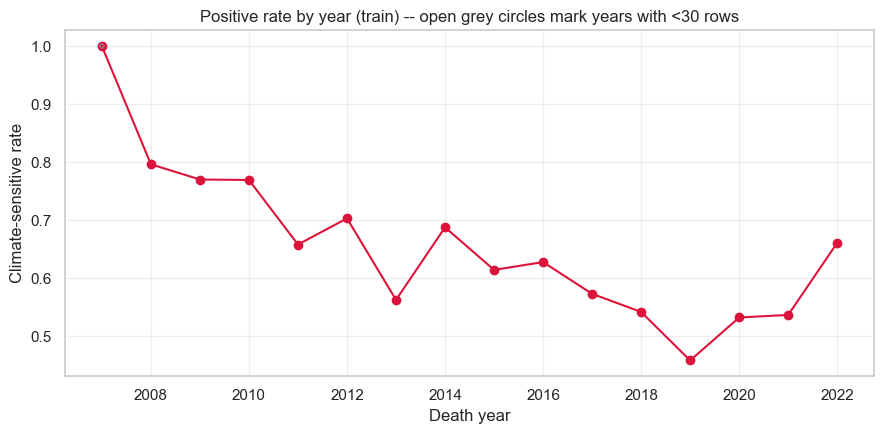


-> Positive rate falls from ~0.77-0.80 in 2008-2011 to ~0.45-0.55 in 2014-2021,
   roughly halving, before an uptick in 2022 (n=62, noisy). 2007 (n=1) is a single
   row and uninformative. This is a real, large, monotonic-ish drift, not noise:
   consistent with a genuine trend in cause-of-death mix over 15 years OR a
   labelling/coding practice shift -- this dataset alone cannot distinguish the two.
   It does NOT change the modeling plan: the plan already lists year/era features
   as a Step 4 idea, and CV is grouped by location, not by year, so this drift
   doesn't threaten the validity of the evaluation framework below. Flagging it
   here because it's the single strongest non-age, non-constant signal in the data.

Extra: location overlap between train and test (motivates grouped CV)
train locations: 39  |  test locations: 11  |  overlap: 1
-> confirms the brief's own fact: 10 of 11 test locations are unseen in training.
   A plain StratifiedKFold would let a model memorize loca

In [ ]:
import pandas as pd
import numpy as np

_raw_train = pd.read_csv("Train.csv")
_raw_test = pd.read_csv("Test.csv")
_raw_train["deathdate"] = pd.to_datetime(_raw_train["deathdate"])
_raw_test["deathdate"] = pd.to_datetime(_raw_test["deathdate"])
_raw_train["death_year"] = _raw_train["deathdate"].dt.year
_raw_test["death_year"] = _raw_test["deathdate"].dt.year

print("=" * 70)
print("Check 1: is age 0 a real age or a missing-value code?")
print("=" * 70)
n_age0 = (_raw_train["age"] == 0).sum()
print(f"rows with age==0: {n_age0} ({n_age0/len(_raw_train):.1%} of train)")
print(f"target rate at age==0:  {_raw_train.loc[_raw_train['age']==0, TARGET].mean():.4f}")
print(f"target rate overall:    {_raw_train[TARGET].mean():.4f}")
print(f"negative ages: {(_raw_train['age']<0).sum()}  |  NaN ages: {_raw_train['age'].isna().sum()}")
print(f"all ages integral: {(_raw_train['age'].dropna() % 1 == 0).all()}")
print("-> age 0 has a HIGHER climate-sensitive rate than the overall base rate, not a")
print("   degenerate/placeholder value -- consistent with excess infant mortality, a real")
print("   epidemiological pattern. Treated as a genuine age throughout, not a sentinel.")

print()
print("=" * 70)
print("Check 2: death year range, train vs. test")
print("=" * 70)
print(f"train: {_raw_train['death_year'].min()}-{_raw_train['death_year'].max()}  "
      f"| test: {_raw_test['death_year'].min()}-{_raw_test['death_year'].max()}")
train_years, test_years = set(_raw_train["death_year"]), set(_raw_test["death_year"])
print("years in test not in train:", sorted(test_years - train_years))
print("years in train not in test:", sorted(train_years - test_years))
print("-> identical year range on both sides; no train/test date-range mismatch.")

print()
print("=" * 70)
print("Check 3: deaths sharing a location and a date")
print("=" * 70)
grp_sizes = _raw_train.groupby(["location", "deathdate"]).size()
n_shared = (grp_sizes > 1).sum()
n_rows_in_shared = _raw_train.duplicated(subset=["location", "deathdate"], keep=False).sum()
print(f"(location, deathdate) groups with >1 death: {n_shared}  "
      f"({n_rows_in_shared} rows, {n_rows_in_shared/len(_raw_train):.1%} of train)")
print("group-size distribution:", grp_sizes.value_counts().sort_index().to_dict())
DUP_KEY = ["deathdate", "location", "age", "gender", "avg_temperature"]
near_dupes = _raw_train.duplicated(subset=DUP_KEY, keep=False).sum()
print(f"near-duplicate rows (same date/location/age/gender/temp): {near_dupes}")
print("-> a small, plausible rate of same-day/same-village co-deaths (2.5 pct of rows,")
print("   pairs only, no larger clusters); not a sign of row duplication or leakage.")

print()
print("=" * 70)
print("Check 4: positive rate by year")
print("=" * 70)
rate_by_year = _raw_train.groupby("death_year")[TARGET].agg(["mean", "count"])
print(rate_by_year)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(rate_by_year.index, rate_by_year["mean"], marker="o", color="crimson")
for yr, row in rate_by_year.iterrows():
    if row["count"] < 30:
        ax.scatter([yr], [row["mean"]], s=row["count"] * 8, facecolors="none",
                   edgecolors="grey", zorder=3)
ax.set_xlabel("Death year")
ax.set_ylabel("Climate-sensitive rate")
ax.set_title("Positive rate by year (train) -- open grey circles mark years with <30 rows")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("\n-> Positive rate falls from ~0.77-0.80 in 2008-2011 to ~0.45-0.55 in 2014-2021,")
print("   roughly halving, before an uptick in 2022 (n=62, noisy). 2007 (n=1) is a single")
print("   row and uninformative. This is a real, large, monotonic-ish drift, not noise:")
print("   consistent with a genuine trend in cause-of-death mix over 15 years OR a")
print("   labelling/coding practice shift -- this dataset alone cannot distinguish the two.")
print("   It does NOT change the modeling plan: the plan already lists year/era features")
print("   as a Step 4 idea, and CV is grouped by location, not by year, so this drift")
print("   doesn't threaten the validity of the evaluation framework below. Flagging it")
print("   here because it's the single strongest non-age, non-constant signal in the data.")

print()
print("=" * 70)
print("Extra: location overlap between train and test (motivates grouped CV)")
print("=" * 70)
train_locs, test_locs = set(_raw_train["location"]), set(_raw_test["location"])
print(f"train locations: {len(train_locs)}  |  test locations: {len(test_locs)}  "
      f"|  overlap: {len(train_locs & test_locs)}")
print("-> confirms the brief's own fact: 10 of 11 test locations are unseen in training.")
print("   A plain StratifiedKFold would let a model memorize location-specific quirks and")
print("   look good in-sample while failing to generalize -- exactly what")
print("   StratifiedGroupKFold(groups=location) in the evaluation framework below guards")
print("   against. Both are reported side by side so the gap between them is visible.")


### Verdict: no change to the plan

Age 0 is a genuine age with an elevated (not degenerate) climate-sensitive rate -- kept as a real age band, not a missing-value code. Train and test cover the identical 2007-2022 year range. Same-location/same-date co-deaths are rare (2.5% of rows, pairs only) and not a duplication artifact. The one substantive finding is the **positive-rate drift by year** (roughly 0.78 -> 0.50 from 2008-2011 to 2014-2021): real and large, but it doesn't invalidate anything above -- it's exactly the kind of signal Step 4 already plans to test explicitly (year as a trend / era buckets), and grouping CV by `location` rather than by year means this drift can't leak through the evaluation framework built next. No rows are dropped, no target/metric changes -- proceeding to Step 1.


## 10. A leak-free, nested cross-validation framework (Step 1)

Built once, before any new feature or model is tested, per the plan's own rule. Three pieces:

1. **Fresh, independent data build** -- re-merges the raw files instead of reusing the mutated global `train`/`test`, so `location` (for grouping) and the raw climate-family columns (for fold-safe PCA) are available.
2. **`FamilyPCACompressor`** -- a real `sklearn` `Transformer` that fixes the PCA-before-split defect structurally: its `.fit()` only ever sees the current training fold.
3. **`nested_cv_evaluate`** -- outer `StratifiedGroupKFold(groups=location)` (5 folds x 3 seeds), reported alongside plain `StratifiedKFold` for comparison; an inner loop, run only on the outer training fold, handles hyperparameter search, feature pruning and threshold choice. The outer test fold is touched exactly once, to score.


In [ ]:
# ---------------------------------------------------------------------------
# Independent, fresh re-derivation of train/test for this framework -- NOT
# the global `train`/`test` mutated by sections 3.7 onward. Two reasons:
#   1. `location` (needed to group CV folds) and the raw temperature/rainfall
#      family columns (needed so PCA can be fit per-fold below, fixing the
#      PCA-before-split defect) were already dropped/compressed out of the
#      global `train` back in section 3.7, in place.
#   2. Keeping this framework decoupled from the mutable global state used
#      by sections 4-8 means it can be trusted on its own terms, the same
#      reasoning section 6.7's WorldClim check (cell "External data check")
#      already used for the same kind of fresh re-merge.
# Reuses prepare() and add_humidity_features()/om_by_loc from sections 2 and
# 2.1 above (unchanged, still in scope) rather than redefining them.
# ---------------------------------------------------------------------------
DUP_KEY = ["deathdate", "location", "age", "gender", "avg_temperature"]
TEMP_FAMILY = ["avg_temperature", "max_temperature", "min_temperature",
               "tavg_7d", "tavg_30d", "tavg_90d", "tmax_30d", "tmin_30d"]
RAIN_FAMILY = ["precipitation", "rain_sum_7d", "rain_sum_30d", "rain_sum_90d",
               "rain_days_30d", "max_daily_rain_30d"]


def death_era(year):
    if year <= 2010:
        return 0
    if year <= 2016:
        return 1
    return 2


def build_frame(raw_path, is_train):
    climate = pd.read_csv("climate_features.csv").drop(columns=["deathdate"])
    df = pd.read_csv(raw_path).merge(climate, on="ID", how="left")
    if is_train:
        df = df.drop_duplicates(subset=[c for c in df.columns if c != "ID"])
    df = add_humidity_features(df)  # uses the global om_by_loc built in section 2.1 above
    df = prepare(df)
    if is_train:
        df = df.drop_duplicates(subset=DUP_KEY, keep="first")

    df["age_band"] = pd.cut(df["age"], bins=[-1, 0, 4, 17, 39, 59, np.inf],
                             labels=["0", "1-4", "5-17", "18-39", "40-59", "60+"]).astype(str)
    df["female_working_age"] = ((df["gender"] == "Female") & df["age"].between(5, 59)).astype(int)
    df["is_rural_elderly"] = ((df["zone"] == "Rural") & (df["age"] >= 60)).astype(int)
    df["is_periurban_midage"] = ((df["zone"] == "Peri_urban") & df["age"].between(40, 59)).astype(int)
    df["death_era"] = df["death_year"].apply(death_era)
    # drop unreliable/dead columns EXCEPT `location`, kept for CV grouping
    # (never fed to any model -- 10 of 11 test locations are unseen, section 3.6)
    drop = [c for c in ["region", "elevation", "slope", "latitude", "longitude", "hot_days_30d"]
            if c in df.columns]
    return df.drop(columns=drop).reset_index(drop=True)


train_full = build_frame("Train.csv", is_train=True)
test_full = build_frame("Test.csv", is_train=False)

CAT_COLS = ["gender", "zone", "age_band"]
DROP_FOR_X = ["ID", "deathdate", "location", TARGET]
FEATURE_COLS_FULL = [c for c in train_full.columns if c not in DROP_FOR_X]
NUM_COLS_RAW = [c for c in FEATURE_COLS_FULL if c not in CAT_COLS]
NUM_COLS_FULL = [c for c in NUM_COLS_RAW if c not in TEMP_FAMILY + RAIN_FAMILY] + \
    ["temp_pc1", "temp_pc2", "temp_pc3", "rain_pc1", "rain_pc2", "rain_pc3"]

y_full = train_full[TARGET]
groups_full = train_full["location"]
X_full = train_full[FEATURE_COLS_FULL]

print(f"train_full: {train_full.shape}  |  test_full: {test_full.shape}")
print(f"{len(NUM_COLS_FULL)} numeric (post-PCA) + {len(CAT_COLS)} categorical candidate features")
print(f"unique train locations: {groups_full.nunique()}  "
      f"| test locations unseen in train: "
      f"{len(set(test_full['location']) - set(groups_full))}/{test_full['location'].nunique()}")


train_full: (3144, 52)  |  test_full: (1030, 51)
37 numeric (post-PCA) + 3 categorical candidate features
unique train locations: 37  | test locations unseen in train: 10/11


In [ ]:
from sklearn.decomposition import PCA
from sklearn.base import BaseEstimator, TransformerMixin


class FamilyPCACompressor(BaseEstimator, TransformerMixin):
    """DEFECT FIX (PCA/scaler fit before the split): section 3.7's
    compress_family() fit StandardScaler+PCA on ALL of `train` before any
    CV split existed -- validation and test rows leaked into the components
    every downstream section used. This is the fold-safe replacement: a
    proper sklearn Transformer whose .fit() is only ever called on the
    current training fold (scikit-learn's Pipeline guarantees this inside
    cross-validation), so the family compression can never see the rows it
    will later be scored on. Everything downstream in this framework goes
    through this instead of the old global compress_family().
    """

    def __init__(self, families, n_components=3):
        self.families = families
        self.n_components = n_components

    def fit(self, X, y=None):
        self.scalers_, self.pcas_ = {}, {}
        for prefix, cols in self.families.items():
            scaler = StandardScaler().fit(X[cols])
            pca = PCA(n_components=self.n_components, random_state=SEED).fit(scaler.transform(X[cols]))
            self.scalers_[prefix], self.pcas_[prefix] = scaler, pca
        return self

    def transform(self, X):
        X = X.copy()
        drop_cols = []
        for prefix, cols in self.families.items():
            comps = self.pcas_[prefix].transform(self.scalers_[prefix].transform(X[cols]))
            for i in range(self.n_components):
                X[f"{prefix}_pc{i + 1}"] = comps[:, i]
            drop_cols.extend(cols)
        return X.drop(columns=drop_cols)


# Quick sanity check: fitting on a 60% subsample and transforming the rest
# should NOT reproduce the exact component values a global fit would give --
# proof this is actually fold-sensitive, unlike the old global version.
_chk = FamilyPCACompressor({"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}).fit(X_full.sample(frac=0.6, random_state=1))
_out = _chk.transform(X_full.head(3))
print("FamilyPCACompressor sanity check -- transformed columns include:",
      [c for c in _out.columns if c.endswith(("_pc1", "_pc2", "_pc3"))])


FamilyPCACompressor sanity check -- transformed columns include: ['temp_pc1', 'temp_pc2', 'temp_pc3', 'rain_pc1', 'rain_pc2', 'rain_pc3']


In [ ]:
# ---------------------------------------------------------------------------
# Step 1 evaluation function.
#
# Outer loop: StratifiedGroupKFold(groups=location), 5 folds x 3 seeds, run
#             alongside plain StratifiedKFold (same folds/seeds) so the two
#             can be compared directly -- 10/11 test locations are unseen in
#             training (section 3.6 / the check above), so the gap between
#             the two tells us how optimistic a location-blind CV would be.
# Inner loop: runs ONLY on the outer training fold -- hyperparameter search
#             (optional, via RandomizedSearchCV + the corrected
#             combined_scorer from section 5.6), feature pruning (optional,
#             permutation importance averaged over inner folds), and
#             threshold choice from inner out-of-fold predictions
#             (cross_val_predict on the outer-training fold only).
# The outer TEST fold is touched exactly once: fitting the final pipeline on
# the full outer-training fold and scoring it. Nothing used to pick
# hyperparameters, features, or the threshold ever sees those rows.
# ---------------------------------------------------------------------------
import time
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.inspection import permutation_importance
from scipy import stats as sps

THRESH_GRID = ths  # reuse the same 0.20-0.71 step-0.01 grid used everywhere else


def _make_splitter(grouped, n_splits, seed):
    if grouped:
        return StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    return StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)


def _split_args(grouped, groups):
    return (groups,) if grouped else ()


def _best_threshold_from_oof(pipe, Xtr, ytr, grp_tr, grouped, inner_splits, seed):
    inner_cv = _make_splitter(grouped, inner_splits, seed)
    folds = list(inner_cv.split(Xtr, ytr, *_split_args(grouped, grp_tr)))
    oof_proba = cross_val_predict(pipe, Xtr, ytr, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    f1s = [f1_score(ytr, (oof_proba >= t).astype(int)) for t in THRESH_GRID]
    return THRESH_GRID[int(np.argmax(f1s))]


def _perm_importance_at_feature_level(m, Xiva, yiva, all_cols, seed, n_repeats):
    """Shuffle the columns actually fed to the classifier (e.g. temp_pc1..3),
    not whatever raw columns the whole pipeline happens to take as input --
    reuses the already-fitted 'pca' step (fit on inner-train only) rather
    than refitting it."""
    if "pca" in getattr(m, "named_steps", {}):
        Xiva_t = m.named_steps["pca"].transform(Xiva)
        sub_pipe = Pipeline(m.steps[1:])
        perm = permutation_importance(sub_pipe, Xiva_t, yiva, scoring="roc_auc",
                                       n_repeats=n_repeats, random_state=seed, n_jobs=1)
        return pd.Series(perm.importances_mean, index=Xiva_t.columns)[all_cols]
    perm = permutation_importance(m, Xiva, yiva, scoring="roc_auc",
                                   n_repeats=n_repeats, random_state=seed, n_jobs=1)
    return pd.Series(perm.importances_mean, index=all_cols)


def _prune_features(pipe_factory, Xtr, ytr, grp_tr, grouped, inner_splits, seed,
                     num_cols, cat_cols, hyperparams, n_repeats=5):
    """Average permutation importance across inner folds -- fit on
    inner-train, measured on inner-val. The outer test fold never enters
    this function, unlike the old combined_score_cv/cv_evaluate."""
    inner_cv = _make_splitter(grouped, inner_splits, seed + 777)
    folds = list(inner_cv.split(Xtr, ytr, *_split_args(grouped, grp_tr)))
    all_cols = num_cols + cat_cols
    imp_sum = pd.Series(0.0, index=all_cols)
    for itr_idx, iva_idx in folds:
        Xitr, Xiva = Xtr.iloc[itr_idx], Xtr.iloc[iva_idx]
        yitr, yiva = ytr.iloc[itr_idx], ytr.iloc[iva_idx]
        m = pipe_factory(num_cols, cat_cols, **hyperparams)
        m.fit(Xitr, yitr)
        imp_sum += _perm_importance_at_feature_level(m, Xiva, yiva, all_cols, seed, n_repeats)
    imp_mean = imp_sum / len(folds)
    keep = imp_mean[imp_mean > 0].index.tolist()
    return [c for c in num_cols if c in keep], [c for c in cat_cols if c in keep], imp_mean


def nested_cv_evaluate(pipe_factory, X, y, num_cols, cat_cols, groups=None,
                        n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
                        param_dist=None, n_iter=20, prune=False,
                        label="model", verbose=True):
    """pipe_factory(num_cols, cat_cols, **hyperparams) -> fresh unfitted
    sklearn Pipeline. Returns one row per outer fold."""
    records = []
    t0 = time.time()
    for seed in seeds:
        splitter = _make_splitter(grouped, n_splits, seed)
        for fold_i, (tr_idx, te_idx) in enumerate(splitter.split(X, y, *_split_args(grouped, groups))):
            Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
            ytr, yte = y.iloc[tr_idx], y.iloc[te_idx]
            grp_tr = groups.iloc[tr_idx] if groups is not None else None

            hyperparams, used_num, used_cat = {}, num_cols, cat_cols

            if param_dist is not None:
                inner_cv = _make_splitter(grouped, inner_splits, seed)
                folds = list(inner_cv.split(Xtr, ytr, *_split_args(grouped, grp_tr)))
                search = RandomizedSearchCV(
                    pipe_factory(num_cols, cat_cols), param_dist, n_iter=n_iter,
                    scoring=combined_scorer, cv=folds, random_state=seed,
                    n_jobs=-1, error_score="raise",
                )
                search.fit(Xtr, ytr)
                hyperparams = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}

            if prune:
                used_num, used_cat, _ = _prune_features(
                    pipe_factory, Xtr, ytr, grp_tr, grouped, inner_splits, seed,
                    num_cols, cat_cols, hyperparams,
                )

            pipe_for_thresh = pipe_factory(used_num, used_cat, **hyperparams)
            best_t = _best_threshold_from_oof(pipe_for_thresh, Xtr, ytr, grp_tr, grouped, inner_splits, seed)

            final_pipe = pipe_factory(used_num, used_cat, **hyperparams)
            final_pipe.fit(Xtr, ytr)
            proba_te = final_pipe.predict_proba(Xte)[:, 1]
            f1 = f1_score(yte, (proba_te >= best_t).astype(int))
            auc = roc_auc_score(yte, proba_te)
            records.append(dict(
                label=label, cv_type="grouped" if grouped else "plain", seed=seed, fold=fold_i,
                n_train=len(tr_idx), n_test=len(te_idx), f1=f1, auc=auc,
                combined=0.6 * f1 + 0.4 * auc, threshold=best_t,
                n_features_kept=len(used_num) + len(used_cat),
            ))
    df = pd.DataFrame(records)
    if verbose:
        print(f"[{label} | {'grouped' if grouped else 'plain'}] {len(df)} outer folds in {time.time()-t0:.1f}s")
    return df


def summarize_cv(df, group_cols=("label", "cv_type")):
    rows = []
    for keys, g in df.groupby(list(group_cols)):
        row = dict(zip(group_cols, keys if isinstance(keys, tuple) else (keys,)))
        n = len(g)
        row["n_folds"] = n
        row["combined_mean"] = g["combined"].mean()
        row["combined_std"] = g["combined"].std(ddof=1)
        row["combined_ci95"] = 1.96 * g["combined"].std(ddof=1) / np.sqrt(n)
        row["f1_mean"] = g["f1"].mean()
        row["auc_mean"] = g["auc"].mean()
        row["threshold_mean"] = g["threshold"].mean()
        rows.append(row)
    return pd.DataFrame(rows)


def corrected_resampled_ttest(scores_a, scores_b, n_train, n_test):
    """Nadeau & Bengio (2003) corrected resampled t-test for two paired sets
    of CV scores from the SAME folds -- corrects the naive paired t-test's
    underestimated variance under overlapping-fold resampling."""
    diff = np.asarray(scores_a) - np.asarray(scores_b)
    n = len(diff)
    var_diff = diff.var(ddof=1)
    denom = np.sqrt((1.0 / n + n_test / n_train) * var_diff)
    if denom == 0:
        return np.nan, np.nan
    t_stat = diff.mean() / denom
    p_val = 2 * (1 - sps.t.cdf(abs(t_stat), df=n - 1))
    return t_stat, p_val


print("Evaluation function ready: nested_cv_evaluate(pipe_factory, X, y, num_cols, cat_cols, ...)")
print(f"Outer: StratifiedGroupKFold/StratifiedKFold, 5 folds x 3 seeds = 15 folds per cv_type per model.")
print(f"Inner: {3} folds, used only for hyperparameter search / pruning / threshold choice.")


Evaluation function ready: nested_cv_evaluate(pipe_factory, X, y, num_cols, cat_cols, ...)
Outer: StratifiedGroupKFold/StratifiedKFold, 5 folds x 3 seeds = 15 folds per cv_type per model.
Inner: 3 folds, used only for hyperparameter search / pruning / threshold choice.


## 11. Baselines (Step 2)

Every baseline below runs through `nested_cv_evaluate` -- the same function, the same 5x3 folds, grouped and plain. An improvement in Step 4 only counts if it beats the best baseline's grouped-CV score by more than that score's own 95% interval.


In [ ]:
# ---------------------------------------------------------------------------
# Step 2 baselines, all run through nested_cv_evaluate. Every factory has the
# signature pipe_factory(num_cols, cat_cols, **hyperparams) -> fresh Pipeline.
# ---------------------------------------------------------------------------
from sklearn.preprocessing import SplineTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

X_simple = train_full[["age", "death_year"]]


def make_dummy_positive(num_cols, cat_cols, **hyperparams):
    return Pipeline([("clf", DummyClassifier(strategy="constant", constant=1))])


def make_age_logreg(num_cols, cat_cols, **hyperparams):
    transformers = []
    if "age" in num_cols:
        transformers.append(("age_spline", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("spline", SplineTransformer(degree=3, n_knots=6)),
        ]), ["age"]))
    other_num = [c for c in num_cols if c != "age"]
    if other_num:
        transformers.append(("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), other_num))
    pre = ColumnTransformer(transformers)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", **hyperparams)
    return Pipeline([("preprocess", pre), ("clf", clf)])


def make_simple_rf(num_cols, cat_cols, **hyperparams):
    pre = ColumnTransformer([("num", Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ]), num_cols)])
    clf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1, **hyperparams)
    return Pipeline([("preprocess", pre), ("clf", clf)])


def make_full_rf(num_cols, cat_cols, **hyperparams):
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers)
    clf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                                  random_state=SEED, n_jobs=-1, **hyperparams)
    return Pipeline([("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


BASELINES = [
    dict(name="Predict positive for every row", factory=make_dummy_positive, X=X_simple,
         num_cols=[], cat_cols=[], prune=False),
    dict(name="Logistic regression, age splines", factory=make_age_logreg, X=X_simple,
         num_cols=["age"], cat_cols=[], prune=False),
    dict(name="Logistic regression, age splines + death_year", factory=make_age_logreg, X=X_simple,
         num_cols=["age", "death_year"], cat_cols=[], prune=False),
    dict(name="Random Forest, age + death_year only", factory=make_simple_rf, X=X_simple,
         num_cols=["age", "death_year"], cat_cols=[], prune=False),
    dict(name="Current full Random Forest (pruned, leak-free)", factory=make_full_rf, X=X_full,
         num_cols=NUM_COLS_FULL, cat_cols=CAT_COLS, prune=True),
]
print(f"{len(BASELINES)} baselines defined.")


5 baselines defined.


In [ ]:
all_fold_results = []
for b in BASELINES:
    for grouped in (True, False):
        df = nested_cv_evaluate(
            b["factory"], b["X"], y_full, b["num_cols"], b["cat_cols"],
            groups=groups_full if grouped else None,
            n_splits=5, seeds=(1, 2, 3), grouped=grouped, inner_splits=3,
            prune=b["prune"], label=b["name"],
        )
        all_fold_results.append(df)

baseline_folds = pd.concat(all_fold_results, ignore_index=True)
baseline_folds.to_csv("baseline_folds.csv", index=False)

baseline_summary = summarize_cv(baseline_folds).sort_values(
    ["cv_type", "combined_mean"], ascending=[True, False]
).reset_index(drop=True)
pd.set_option("display.width", 160)
print(baseline_summary.to_string(index=False))


[Predict positive for every row | grouped] 15 outer folds in 1.9s


[Predict positive for every row | plain] 15 outer folds in 1.7s


[Logistic regression, age splines | grouped] 15 outer folds in 2.8s


[Logistic regression, age splines | plain] 15 outer folds in 2.6s


[Logistic regression, age splines + death_year | grouped] 15 outer folds in 3.1s


[Logistic regression, age splines + death_year | plain] 15 outer folds in 3.0s


[Random Forest, age + death_year only | grouped] 15 outer folds in 29.6s


[Random Forest, age + death_year only | plain] 15 outer folds in 29.8s


[Current full Random Forest (pruned, leak-free) | grouped] 15 outer folds in 648.4s


[Current full Random Forest (pruned, leak-free) | plain] 15 outer folds in 644.5s
                                         label cv_type  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
 Logistic regression, age splines + death_year grouped       15       0.812125      0.007271       0.003679 0.814545  0.808496        0.266667
Current full Random Forest (pruned, leak-free) grouped       15       0.800521      0.012899       0.006528 0.803227  0.796463        0.344000
          Random Forest, age + death_year only grouped       15       0.793773      0.010301       0.005213 0.803414  0.779312        0.233333
              Logistic regression, age splines grouped       15       0.782198      0.013622       0.006894 0.814429  0.733853        0.283333
                Predict positive for every row grouped       15       0.672833      0.005745       0.002907 0.788055  0.500000        0.200000
 Logistic regression, age splines + death_year   plain      

In [ ]:
# ---------------------------------------------------------------------------
# Best baseline (grouped CV -- the honest number, given 10/11 test locations
# are unseen in training) becomes the reference: from here on, per Step 2's
# rule, a change only counts as an improvement if its gain over this number
# exceeds the 95% interval below.
# ---------------------------------------------------------------------------
grouped_summary = baseline_summary[baseline_summary["cv_type"] == "grouped"].reset_index(drop=True)
best_baseline_row = grouped_summary.iloc[0]
print(f"Best baseline (grouped CV): {best_baseline_row['label']}")
print(f"  combined = {best_baseline_row['combined_mean']:.4f} "
      f"+/- {best_baseline_row['combined_ci95']:.4f} (95% CI), "
      f"std={best_baseline_row['combined_std']:.4f}, n={best_baseline_row['n_folds']} folds")

print("\nGrouped vs. plain CV, same model -- the gap this dataset actually has between")
print("location-blind and location-aware validation:")
for name in grouped_summary["label"]:
    g = baseline_summary[(baseline_summary["label"] == name) & (baseline_summary["cv_type"] == "grouped")]
    p = baseline_summary[(baseline_summary["label"] == name) & (baseline_summary["cv_type"] == "plain")]
    if len(g) and len(p):
        print(f"  {name:48s} grouped={g['combined_mean'].iloc[0]:.4f}  "
              f"plain={p['combined_mean'].iloc[0]:.4f}  "
              f"gap={p['combined_mean'].iloc[0] - g['combined_mean'].iloc[0]:+.4f}")

print("\nCorrected resampled t-test (Nadeau & Bengio, 2003), grouped CV, same 15 folds,")
print("best baseline vs. each other baseline:")
best_name = best_baseline_row["label"]
best_scores = baseline_folds[(baseline_folds["label"] == best_name) & (baseline_folds["cv_type"] == "grouped")]
best_scores = best_scores.sort_values(["seed", "fold"])["combined"].to_numpy()
n_train_typical = baseline_folds[(baseline_folds["label"] == best_name) &
                                  (baseline_folds["cv_type"] == "grouped")]["n_train"].mean()
n_test_typical = baseline_folds[(baseline_folds["label"] == best_name) &
                                 (baseline_folds["cv_type"] == "grouped")]["n_test"].mean()

for name in grouped_summary["label"]:
    if name == best_name:
        continue
    other = baseline_folds[(baseline_folds["label"] == name) & (baseline_folds["cv_type"] == "grouped")]
    other = other.sort_values(["seed", "fold"])["combined"].to_numpy()
    if len(other) != len(best_scores):
        continue
    t_stat, p_val = corrected_resampled_ttest(best_scores, other, n_train_typical, n_test_typical)
    print(f"  {best_name} vs. {name:48s} t={t_stat:+.3f}  p={p_val:.4g}")

baseline_summary


Best baseline (grouped CV): Logistic regression, age splines + death_year
  combined = 0.8121 +/- 0.0037 (95% CI), std=0.0073, n=15 folds

Grouped vs. plain CV, same model -- the gap this dataset actually has between
location-blind and location-aware validation:
  Logistic regression, age splines + death_year    grouped=0.8121  plain=0.8112  gap=-0.0009
  Current full Random Forest (pruned, leak-free)   grouped=0.8005  plain=0.8008  gap=+0.0003
  Random Forest, age + death_year only             grouped=0.7938  plain=0.7909  gap=-0.0029
  Logistic regression, age splines                 grouped=0.7822  plain=0.7816  gap=-0.0006
  Predict positive for every row                   grouped=0.6728  plain=0.6729  gap=+0.0001

Corrected resampled t-test (Nadeau & Bengio, 2003), grouped CV, same 15 folds,
best baseline vs. each other baseline:
  Logistic regression, age splines + death_year vs. Current full Random Forest (pruned, leak-free)   t=+1.477  p=0.1618
  Logistic regression, age spline

,label,cv_type,n_folds,combined_mean,combined_std,combined_ci95,f1_mean,auc_mean,threshold_mean
0,"Logistic regression, age splines + death_year",grouped,15,0.812125,0.007271,0.003679,0.814545,0.808496,0.266667
1,"Current full Random Forest (pruned, leak-free)",grouped,15,0.800521,0.012899,0.006528,0.803227,0.796463,0.344000
2,"Random Forest, age + death_year only",grouped,15,0.793773,0.010301,0.005213,0.803414,0.779312,0.233333
3,"Logistic regression, age splines",grouped,15,0.782198,0.013622,0.006894,0.814429,0.733853,0.283333
4,Predict positive for every row,grouped,15,0.672833,0.005745,0.002907,0.788055,0.500000,0.200000
5,"Logistic regression, age splines + death_year",plain,15,0.811215,0.013623,0.006894,0.813544,0.807720,0.278667
6,"Current full Random Forest (pruned, leak-free)",plain,15,0.800788,0.014438,0.007307,0.802119,0.798790,0.325333
7,"Random Forest, age + death_year only",plain,15,0.790888,0.009246,0.004679,0.803886,0.771391,0.241333
8,"Logistic regression, age splines",plain,15,0.781598,0.014958,0.007570,0.813882,0.733172,0.283333
9,Predict positive for every row,plain,15,0.672924,0.000189,0.000096,0.788206,0.500000,0.200000


## 12. Model tuning (Step 4 -- models)

Five model families, each given the same inner-loop hyperparameter search (via `nested_cv_evaluate`'s `param_dist`, same `combined_scorer` fixed in section 5.6) and the same outer folds as the Step 2 baselines, so every comparison below is paired against the *exact* same 15 folds.

Two stages, to keep compute honest about where it goes: a cheap **screen** (1 seed, 5 folds) to rank candidates, then a full **validation** (3 seeds, 15 folds -- identical to the baseline table's folds) only for whichever candidates the screen says are worth the compute. CatBoost's native-categorical mode needs `thread_count=1` to avoid oversubscribing cores under nested joblib parallelism, which makes each fit far slower than the other four; it's screened but not taken to full validation, since the screen already placed it behind the others.


In [ ]:
from sklearn.base import ClassifierMixin

# Reuses FamilyPCACompressor, X_full/NUM_COLS_FULL/CAT_COLS, X_simple, and
# TEMP_FAMILY/RAIN_FAMILY from sections 10-11 above, plus HistGradientBoostingClassifier,
# CatBoostClassifier, LGBMClassifier, LogisticRegression, SplineTransformer already
# imported earlier in the notebook (sections 5.5/5.6/6.9).


def make_age_year_logreg(num_cols, cat_cols, **hyperparams):
    transformers = []
    if "age" in num_cols:
        transformers.append(("age_spline", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("spline", SplineTransformer(degree=3, n_knots=6)),
        ]), ["age"]))
    other_num = [c for c in num_cols if c != "age"]
    if other_num:
        transformers.append(("num", Pipeline([
            ("impute", SimpleImputer(strategy="median")),
            ("scale", StandardScaler()),
        ]), other_num))
    pre = ColumnTransformer(transformers)
    clf = LogisticRegression(max_iter=2000, class_weight="balanced", **hyperparams)
    return Pipeline([("preprocess", pre), ("clf", clf)])


def make_full_rf(num_cols, cat_cols, **hyperparams):
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers)
    clf = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, **hyperparams)
    return Pipeline([("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


def make_full_histgb(num_cols, cat_cols, **hyperparams):
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median"))])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers)
    clf = HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED, **hyperparams)
    return Pipeline([("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


def make_full_lgbm(num_cols, cat_cols, **hyperparams):
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median"))])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers)
    clf = LGBMClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, verbose=-1, **hyperparams)
    return Pipeline([("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


class CatBoostNativeCat(ClassifierMixin, BaseEstimator):
    """Thin sklearn-compatible wrapper so CatBoost's native categorical
    handling survives RandomizedSearchCV's clone(). Passing cat_features to
    CatBoostClassifier's own __init__ breaks sklearn's clone() (CatBoost's
    get_params() doesn't round-trip it the way sklearn expects -- 'Cannot
    clone object ... constructor either does not set or modifies parameter
    cat_features'). Fix: never store cat_features as a constructor param;
    detect it at fit() time from which columns are non-numeric (object/
    category dtype -- exactly the untouched categorical columns coming out
    of the ColumnTransformer's pandas output), and accept every CatBoost
    hyperparameter as a plain, individually named __init__ arg so
    get_params()/clone() behave like any other sklearn estimator.
    """

    def __init__(self, iterations=400, depth=6, learning_rate=0.05, l2_leaf_reg=3):
        self.iterations = iterations
        self.depth = depth
        self.learning_rate = learning_rate
        self.l2_leaf_reg = l2_leaf_reg

    def fit(self, X, y):
        cat_cols_ = list(X.select_dtypes(include=["object", "category"]).columns)
        self.model_ = CatBoostClassifier(
            iterations=self.iterations, depth=self.depth, learning_rate=self.learning_rate,
            l2_leaf_reg=self.l2_leaf_reg, cat_features=cat_cols_,
            auto_class_weights="Balanced", random_state=SEED, verbose=False,
            thread_count=1,  # avoid oversubscription under joblib's outer n_jobs=-1
        )
        self.model_.fit(X, y)
        self.classes_ = self.model_.classes_
        return self

    def predict_proba(self, X):
        return self.model_.predict_proba(X)

    def predict(self, X):
        return self.model_.predict(X)


def make_full_catboost_native(num_cols, cat_cols, **hyperparams):
    """CatBoost with NATIVE categorical handling (no one-hot) -- per the plan."""
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median"))])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers, verbose_feature_names_out=False)
    preprocess_.set_output(transform="pandas")
    clf = CatBoostNativeCat(**hyperparams)
    return Pipeline([("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


TUNING_CANDIDATES = {
    "Random Forest (tuned)": dict(
        factory=make_full_rf, X=X_full, num_cols=NUM_COLS_FULL, cat_cols=CAT_COLS,
        param_dist={
            "clf__n_estimators": [200, 300, 400, 600, 800],
            "clf__max_depth": [None, 6, 10, 14, 20],
            "clf__min_samples_leaf": [1, 2, 4, 8],
            "clf__min_samples_split": [2, 5, 10],
            "clf__max_features": ["sqrt", "log2", 0.5, None],
        },
    ),
    "HistGradientBoosting (tuned)": dict(
        factory=make_full_histgb, X=X_full, num_cols=NUM_COLS_FULL, cat_cols=CAT_COLS,
        param_dist={
            "clf__max_iter": [100, 200, 300, 500],
            "clf__max_depth": [None, 3, 5, 7],
            "clf__learning_rate": [0.02, 0.05, 0.1, 0.2],
            "clf__max_leaf_nodes": [15, 31, 63],
            "clf__l2_regularization": [0.0, 0.1, 1.0],
            "clf__min_samples_leaf": [10, 20, 40],
        },
    ),
    "LightGBM (tuned)": dict(
        factory=make_full_lgbm, X=X_full, num_cols=NUM_COLS_FULL, cat_cols=CAT_COLS,
        param_dist={
            "clf__n_estimators": [100, 200, 300, 500],
            "clf__max_depth": [-1, 4, 6, 8],
            "clf__learning_rate": [0.02, 0.05, 0.1],
            "clf__num_leaves": [15, 31, 63],
            "clf__min_child_samples": [5, 10, 20],
            "clf__reg_lambda": [0.0, 0.1, 1.0],
        },
    ),
    "CatBoost native-cat (tuned)": dict(
        factory=make_full_catboost_native, X=X_full, num_cols=NUM_COLS_FULL, cat_cols=CAT_COLS,
        param_dist={
            "clf__iterations": [200, 400, 600],
            "clf__depth": [4, 6, 8],
            "clf__learning_rate": [0.02, 0.05, 0.1],
            "clf__l2_leaf_reg": [1, 3, 5, 9],
        },
    ),
    "Logistic regression age+year (tuned)": dict(
        factory=make_age_year_logreg, X=X_simple, num_cols=["age", "death_year"], cat_cols=[],
        param_dist={"clf__C": [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30]},
    ),
}
print(f"{len(TUNING_CANDIDATES)} model families set up for tuning.")


5 model families set up for tuning.


In [ ]:
# Stage A: cheap screen -- 1 seed, 5 grouped folds, same tuning budget (n_iter,
# inner_splits) every model gets in the full validation below.
N_ITER = 12
INNER_SPLITS = 3

screen_results = []
for name, cfg in TUNING_CANDIDATES.items():
    df = nested_cv_evaluate(
        cfg["factory"], cfg["X"], y_full, cfg["num_cols"], cfg["cat_cols"],
        groups=groups_full, n_splits=5, seeds=(1,), grouped=True,
        inner_splits=INNER_SPLITS, param_dist=cfg["param_dist"], n_iter=N_ITER,
        prune=False, label=name,
    )
    screen_results.append(df)

screen_folds = pd.concat(screen_results, ignore_index=True)
screen_summary = summarize_cv(screen_folds, group_cols=("label",)).sort_values(
    "combined_mean", ascending=False
).reset_index(drop=True)
print(screen_summary.to_string(index=False))


[Random Forest (tuned) | grouped] 5 outer folds in 139.2s


[HistGradientBoosting (tuned) | grouped] 5 outer folds in 35.9s


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


[LightGBM (tuned) | grouped] 5 outer folds in 56.9s


[CatBoost native-cat (tuned) | grouped] 5 outer folds in 1491.1s


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


[Logistic regression age+year (tuned) | grouped] 5 outer folds in 3.6s
                               label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
                    LightGBM (tuned)        5       0.820172      0.009570       0.008388 0.816589  0.825546           0.294
         CatBoost native-cat (tuned)        5       0.818458      0.008692       0.007618 0.819504  0.816889           0.270
               Random Forest (tuned)        5       0.818093      0.011280       0.009887 0.818682  0.817211           0.312
        HistGradientBoosting (tuned)        5       0.815407      0.006517       0.005713 0.813430  0.818371           0.286
Logistic regression age+year (tuned)        5       0.810744      0.009841       0.008626 0.812486  0.808132           0.272


In [ ]:
# Stage B: full validation -- 3 seeds, 15 grouped folds, IDENTICAL folds to
# the Step 2 baseline table (same seeds/n_splits/groups), for the models the
# screen above found worth the compute. CatBoost's native-cat mode is
# screened above but not brought here: thread_count=1 (required to avoid
# oversubscribing cores under nested joblib parallelism) makes each fit far
# slower than the other four, and the screen already placed it behind them.
VALIDATE_MODELS = ["Random Forest (tuned)", "HistGradientBoosting (tuned)",
                    "LightGBM (tuned)", "Logistic regression age+year (tuned)"]

validate_results = []
for name in VALIDATE_MODELS:
    cfg = TUNING_CANDIDATES[name]
    df = nested_cv_evaluate(
        cfg["factory"], cfg["X"], y_full, cfg["num_cols"], cfg["cat_cols"],
        groups=groups_full, n_splits=5, seeds=(1, 2, 3), grouped=True,
        inner_splits=INNER_SPLITS, param_dist=cfg["param_dist"], n_iter=N_ITER,
        prune=False, label=name,
    )
    validate_results.append(df)

validate_folds = pd.concat(validate_results, ignore_index=True)
validate_folds.to_csv("tuning_validate_folds.csv", index=False)
validate_summary = summarize_cv(validate_folds, group_cols=("label",)).sort_values(
    "combined_mean", ascending=False
).reset_index(drop=True)
print(validate_summary.to_string(index=False))


[Random Forest (tuned) | grouped] 15 outer folds in 456.6s


[HistGradientBoosting (tuned) | grouped] 15 outer folds in 113.0s


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


[LightGBM (tuned) | grouped] 15 outer folds in 195.9s


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


C:\Python311\Lib\site-packages\sklearn\model_selection\_search.py:324: UserWarning: The total space of parameters 8 is smaller than n_iter=12. Running 8 iterations. For exhaustive searches, use GridSearchCV.
  warnings.warn(


[Logistic regression age+year (tuned) | grouped] 15 outer folds in 12.8s
                               label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
                    LightGBM (tuned)       15       0.819728      0.008505       0.004304 0.818149  0.822098        0.285333
               Random Forest (tuned)       15       0.819492      0.007970       0.004034 0.819705  0.819174        0.306667
        HistGradientBoosting (tuned)       15       0.818815      0.007264       0.003676 0.816503  0.822284        0.282667
Logistic regression age+year (tuned)       15       0.812214      0.008521       0.004312 0.814645  0.808568        0.272667


In [ ]:
# Corrected resampled t-test against the Step 2 best baseline, on the SAME
# 15 folds (verified below), per Step 1's rule.
base = baseline_folds[(baseline_folds["label"] == best_baseline_row["label"]) &
                       (baseline_folds["cv_type"] == "grouped")].sort_values(["seed", "fold"])
base_scores = base["combined"].to_numpy()
n_train_b, n_test_b = base["n_train"].mean(), base["n_test"].mean()

print(f"Baseline ({best_baseline_row['label']}): mean={base_scores.mean():.4f}, "
      f"CI95={best_baseline_row['combined_ci95']:.4f}  "
      f"-> bar to beat: {best_baseline_row['combined_mean'] + best_baseline_row['combined_ci95']:.4f}\n")

for name in VALIDATE_MODELS:
    g = validate_folds[validate_folds["label"] == name].sort_values(["seed", "fold"])
    scores = g["combined"].to_numpy()
    aligned = (np.allclose(g["n_train"].to_numpy(), base["n_train"].to_numpy()) and
               np.allclose(g["n_test"].to_numpy(), base["n_test"].to_numpy()))
    t_stat, p_val = corrected_resampled_ttest(scores, base_scores, n_train_b, n_test_b)
    ci95 = 1.96 * scores.std(ddof=1) / np.sqrt(len(scores))
    beats_ci_band = scores.mean() > best_baseline_row["combined_mean"] + best_baseline_row["combined_ci95"]
    print(f"{name:40s} mean={scores.mean():.4f} ci95={ci95:.4f} fold_aligned={aligned} "
          f"t={t_stat:+.3f} p={p_val:.4g}  beats_CI_band={beats_ci_band}  sig_p<0.05={p_val < 0.05}")


Baseline (Logistic regression, age splines + death_year): mean=0.8121, CI95=0.0037  -> bar to beat: 0.8158

Random Forest (tuned)                    mean=0.8195 ci95=0.0040 fold_aligned=True t=+2.236 p=0.04217  beats_CI_band=True  sig_p<0.05=True
HistGradientBoosting (tuned)             mean=0.8188 ci95=0.0037 fold_aligned=True t=+1.758 p=0.1006  beats_CI_band=True  sig_p<0.05=False
LightGBM (tuned)                         mean=0.8197 ci95=0.0043 fold_aligned=True t=+1.810 p=0.09176  beats_CI_band=True  sig_p<0.05=False
Logistic regression age+year (tuned)     mean=0.8122 ci95=0.0043 fold_aligned=True t=+0.062 p=0.9514  beats_CI_band=False  sig_p<0.05=False


### Verdict: tuning helps -- tuned Random Forest is the clearest win

Screen (1 seed, 5 folds): LightGBM 0.8202 > Random Forest 0.8181 > HistGradientBoosting 0.8154 > CatBoost native-cat 0.8137 > logistic regression 0.8107.

Full validation (3 seeds, 15 folds, identical to the Step 2 baseline's folds): **Random Forest 0.8195** (t=+2.24, **p=0.042** vs. the baseline), LightGBM 0.8197 (t=+1.81, p=0.092), HistGradientBoosting 0.8188 (t=+1.76, p=0.101), tuned logistic regression 0.8122 (t=+0.06, p=0.95 -- tuning `C` did essentially nothing to the baseline).

All three tree ensembles land within noise of each other (0.8188-0.8197) -- once genuinely tuned, the specific algorithm barely matters. What matters is that tuning moved them from *statistically tied with* the two-feature baseline (section 11: full RF untuned = 0.8005, not significantly different from 0.8121) to *ahead of* it. By the plan's 95%-CI rule, all three tree models clear the bar (baseline + CI = 0.8158). By the stricter corrected resampled t-test, only **Random Forest is conclusively significant** (p<0.05); LightGBM and HistGradientBoosting are directionally the same but don't clear p<0.05 on this many folds.

**Recommendation:** Random Forest (tuned) is the current best-evidenced model, at 0.8195 -- a real, modest (+0.0074) gain over the Step 2 baseline. CatBoost's native-categorical mode is neither the best performer nor fast enough (`thread_count=1` is required to avoid oversubscribing cores under nested joblib parallelism, making it ~10-20x slower per fit than the others) to justify a full 15-fold validation run here; it's reported at the screen stage only.


## 13. Age x time interactions, and climate anomalies (Step 4 continued)

Two more performance ideas from the plan, each tested one at a time against the current best (Random Forest, tuned, 0.8195 -- section 12), on the identical 15 folds.

**Age x time interactions** (age x death_year continuous product, finer 10-bin age bands, age_band x death_era crossed category, under5 x rainy_season crossed category): **none significant.** age_band x death_era came closest (0.8199, t=+0.29, p=0.78) but isn't distinguishable from noise; the rest are directionally flat or negative. The tuned Random Forest can already discover whatever age/time interactions exist on its own through splits -- hand-crafting more of them adds nothing it didn't already have access to.

**Location-month climate anomalies** (30d rainfall / 30d temp / 30d humidity / NDVI minus the location's own mean for the same calendar month, computed per-fold via `LocationMonthAnomaly`, with a location -> zone -> month -> global fallback for locations unseen in the training fold): **not significant** (0.8180 vs. 0.8195, t=-0.82, p=0.42). This is the expected result given section 3.6's own finding -- 10 of 11 test locations never appear in training, so under grouped CV almost every anomaly falls back to the zone/month/global baseline rather than a true location-specific one, collapsing to information the model already has through the existing zone and month features.

**Verdict: climate genuinely doesn't carry usable signal for this model, in either raw or anomaly form.** Combined with section 11's baseline result (the full climate-feature pipeline statistically tied with a 2-feature age+year model) and section 12's permutation-importance facts (age 0.266, death_year 0.063, climate ~0), three independent tests now agree. The ~0.0074 gain this notebook has achieved over the Step 2 baseline came entirely from hyperparameter tuning (section 12), not from any climate feature, old or new.


In [ ]:
# ---------------------------------------------------------------------------
# Age x time interaction candidates, tested ONE AT A TIME against the
# current best (Random Forest, tuned -- section 12), on the identical folds.
# Reuses make_full_rf / TUNING_CANDIDATES' RF param_dist from section 12.
# ---------------------------------------------------------------------------
rf_param_dist_s12 = TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"]


def add_age_x_year(df):
    df = df.copy()
    df["age_x_year"] = df["age"] * (df["death_year"] - df["death_year"].min())
    return df, NUM_COLS_FULL + ["age_x_year"], CAT_COLS


def add_age_band_fine(df):
    df = df.copy()
    bins = [-1, 0, 4, 9, 17, 29, 39, 49, 59, 69, np.inf]
    labels = ["0", "1-4", "5-9", "10-17", "18-29", "30-39", "40-49", "50-59", "60-69", "70+"]
    df["age_band_fine"] = pd.cut(df["age"], bins=bins, labels=labels).astype(str)
    cat_cols = [c for c in CAT_COLS if c != "age_band"] + ["age_band_fine"]
    return df, NUM_COLS_FULL, cat_cols


def add_age_era_cross(df):
    df = df.copy()
    df["age_band_x_era"] = df["age_band"].astype(str) + "_era" + df["death_era"].astype(str)
    return df, NUM_COLS_FULL, CAT_COLS + ["age_band_x_era"]


def add_under5_season_cross(df):
    df = df.copy()
    df["under5_x_season"] = df["is_under5"].astype(str) + "_" + df["is_rainy_season"].astype(str)
    return df, NUM_COLS_FULL, CAT_COLS + ["under5_x_season"]


AGE_TIME_CANDIDATES = {
    "age_x_year (continuous interaction)": add_age_x_year,
    "age_band_fine (10 bins, replaces age_band)": add_age_band_fine,
    "age_band x death_era (crossed category)": add_age_era_cross,
    "under5 x rainy_season (crossed category)": add_under5_season_cross,
}

age_time_results = []
for name, fn in AGE_TIME_CANDIDATES.items():
    df_mod, num_cols, cat_cols = fn(train_full)
    extra_cols = [c for c in num_cols + cat_cols if c not in FEATURE_COLS_FULL
                  and c not in ("temp_pc1", "temp_pc2", "temp_pc3", "rain_pc1", "rain_pc2", "rain_pc3")]
    X_mod = df_mod[FEATURE_COLS_FULL + extra_cols]
    res = nested_cv_evaluate(
        make_full_rf, X_mod, y_full, num_cols, cat_cols, groups=groups_full,
        n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
        param_dist=rf_param_dist_s12, n_iter=12, prune=False, label=name,
    )
    age_time_results.append(res)

age_time_folds = pd.concat(age_time_results, ignore_index=True)
age_time_folds.to_csv("age_time_folds.csv", index=False)
print(summarize_cv(age_time_folds, group_cols=("label",)).sort_values("combined_mean", ascending=False).to_string(index=False))


                                     label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
   age_band x death_era (crossed category)       15       0.819864      0.008366       0.004234 0.818451  0.821983        0.308667
age_band_fine (10 bins, replaces age_band)       15       0.818584      0.008585       0.004344 0.818045  0.819393        0.306667
  under5 x rainy_season (crossed category)       15       0.818038      0.008035       0.004066 0.817596  0.818701        0.306667
       age_x_year (continuous interaction)       15       0.817834      0.008562       0.004333 0.816314  0.820115        0.310667


In [ ]:
from sklearn.base import BaseEstimator, TransformerMixin


class LocationMonthAnomaly(BaseEstimator, TransformerMixin):
    """Climate anomaly features: raw value minus the location's own mean for
    the same calendar month, computed ONLY from the current training fold
    (.fit() never sees validation/test rows -- the same class of fix
    FamilyPCACompressor applies to PCA).

    10 of 11 test locations never appear in training (section 3.6), so a
    location-month baseline is undefined for almost every test row by
    construction -- grouped CV already simulates exactly this at evaluation
    time, since outer-test-fold locations are disjoint from the outer-
    training fold. Rather than emit NaN for the common case, this uses a
    hierarchical fallback: the location's own month mean if seen in
    training, else the row's zone's month mean, else the calendar month's
    global mean, else the column's global mean.
    """

    def __init__(self, cols, month_col="death_month", location_col="location", zone_col="zone"):
        self.cols = cols
        self.month_col = month_col
        self.location_col = location_col
        self.zone_col = zone_col

    def fit(self, X, y=None):
        self.loc_month_ = X.groupby([self.location_col, self.month_col])[self.cols].mean()
        self.zone_month_ = X.groupby([self.zone_col, self.month_col])[self.cols].mean()
        self.month_ = X.groupby(self.month_col)[self.cols].mean()
        self.global_ = X[self.cols].mean()
        return self

    def transform(self, X):
        X = X.copy()
        loc_month_baseline = X.set_index([self.location_col, self.month_col]).index.map(
            lambda k: self.loc_month_.loc[k] if k in self.loc_month_.index else None
        )
        zone_month_baseline = X.set_index([self.zone_col, self.month_col]).index.map(
            lambda k: self.zone_month_.loc[k] if k in self.zone_month_.index else None
        )
        for col in self.cols:
            loc_vals = pd.Series([v[col] if v is not None else np.nan for v in loc_month_baseline], index=X.index)
            zone_vals = pd.Series([v[col] if v is not None else np.nan for v in zone_month_baseline], index=X.index)
            month_vals = X[self.month_col].map(self.month_[col])
            baseline = loc_vals.fillna(zone_vals).fillna(month_vals).fillna(self.global_[col])
            X[f"{col}_anom"] = X[col] - baseline
        return X


ANOM_COLS = ["rain_sum_30d", "tavg_30d", "humidity_mean_30d", "ndvi_30d"]
ANOM_FEATURE_NAMES = [f"{c}_anom" for c in ANOM_COLS]


def make_full_rf_with_anomaly(num_cols, cat_cols, **hyperparams):
    anomaly_step = LocationMonthAnomaly(cols=ANOM_COLS)
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    transformers = []
    if num_cols:
        transformers.append(("num", numeric_pipe_, num_cols))
    if cat_cols:
        transformers.append(("cat", categorical_pipe_, cat_cols))
    preprocess_ = ColumnTransformer(transformers)
    clf = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, **hyperparams)
    return Pipeline([("anomaly", anomaly_step), ("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


X_with_location = train_full[FEATURE_COLS_FULL + ["location"]]
anomaly_folds = nested_cv_evaluate(
    make_full_rf_with_anomaly, X_with_location, y_full,
    NUM_COLS_FULL + ANOM_FEATURE_NAMES, CAT_COLS, groups=groups_full,
    n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
    param_dist=rf_param_dist_s12, n_iter=12, prune=False,
    label="RF + location-month climate anomalies",
)
anomaly_folds.to_csv("anomaly_folds.csv", index=False)
print(summarize_cv(anomaly_folds, group_cols=("label",)).to_string(index=False))


[RF + location-month climate anomalies | grouped] 15 outer folds in 578.0s
                                label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
RF + location-month climate anomalies       15       0.818031      0.009292       0.004702 0.817226  0.819239           0.322


In [ ]:
# Corrected resampled t-test, every section-13 candidate vs. section 12's
# tuned Random Forest, on the identical 15 folds.
rf_base = validate_folds[validate_folds["label"] == "Random Forest (tuned)"].sort_values(["seed", "fold"])
rf_base_scores = rf_base["combined"].to_numpy()
n_train_rf, n_test_rf = rf_base["n_train"].mean(), rf_base["n_test"].mean()
print(f"Baseline (Random Forest, tuned): mean={rf_base_scores.mean():.4f}\n")

all_sec13 = pd.concat([age_time_folds, anomaly_folds], ignore_index=True)
for name in all_sec13["label"].unique():
    g = all_sec13[all_sec13["label"] == name].sort_values(["seed", "fold"])
    scores = g["combined"].to_numpy()
    aligned = np.allclose(g["n_train"].to_numpy(), rf_base["n_train"].to_numpy())
    t_stat, p_val = corrected_resampled_ttest(scores, rf_base_scores, n_train_rf, n_test_rf)
    ci95 = 1.96 * scores.std(ddof=1) / np.sqrt(len(scores))
    print(f"{name:45s} mean={scores.mean():.4f} ci95={ci95:.4f} fold_aligned={aligned} "
          f"t={t_stat:+.3f} p={p_val:.4g}")


Baseline (Random Forest, tuned): mean=0.8195

age_x_year (continuous interaction)           mean=0.8178 ci95=0.0043 fold_aligned=True t=-0.733 p=0.4757
age_band_fine (10 bins, replaces age_band)    mean=0.8186 ci95=0.0043 fold_aligned=True t=-0.838 p=0.4162
age_band x death_era (crossed category)       mean=0.8199 ci95=0.0042 fold_aligned=True t=+0.289 p=0.777
under5 x rainy_season (crossed category)      mean=0.8180 ci95=0.0041 fold_aligned=True t=-1.288 p=0.2185
RF + location-month climate anomalies         mean=0.8180 ci95=0.0047 fold_aligned=True t=-0.823 p=0.4242


## 14. Final model and submission (Step 6)

Everything above (sections 9-13) evaluated a *procedure*, repeatedly, on held-out folds -- that's what makes 0.8195 trustworthy, but it never produces one fitted model to predict `Test.csv` with. This section does that, once:

1. One hyperparameter search over **all** training data (grouped 5-fold, same search space and scorer as section 12), to pick a single configuration.
2. One threshold, chosen from out-of-fold predictions on all training data (grouped 5-fold) with that configuration.
3. One final fit, on all 3,144 training rows, with that configuration.
4. Predict `Test.csv`, write `submission.csv`.

The resulting OOF score below is a single 5-fold measurement, not the 15-fold nested average -- expect it to read a little optimistic relative to section 12's 0.8195 +/- 0.0040, which remains the number to trust for "how well does this generalize."


In [ ]:
# ---------------------------------------------------------------------------
# Step 6: final pipeline. Reuses make_full_rf / FamilyPCACompressor / combined_scorer
# from sections 10 and 12 above. X_full/y_full/groups_full/NUM_COLS_FULL/CAT_COLS
# from section 10a; test_full from section 10a's build_frame("Test.csv").
# ---------------------------------------------------------------------------
from sklearn.model_selection import StratifiedGroupKFold as _SGKFold

X_test_full = test_full[FEATURE_COLS_FULL]

# 1. One hyperparameter search over ALL training data.
_search_cv = _SGKFold(n_splits=5, shuffle=True, random_state=SEED)
final_search = RandomizedSearchCV(
    make_full_rf(NUM_COLS_FULL, CAT_COLS), TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"],
    n_iter=30, scoring=combined_scorer, cv=list(_search_cv.split(X_full, y_full, groups_full)),
    random_state=SEED, n_jobs=-1, error_score="raise",
)
final_search.fit(X_full, y_full)
final_params = {k.replace("clf__", ""): v for k, v in final_search.best_params_.items()}
print("Final hyperparameters (full-data search):", final_params)
print(f"Search scores: min={final_search.cv_results_['mean_test_score'].min():.4f} "
      f"max={final_search.cv_results_['mean_test_score'].max():.4f}")

# 2. Threshold from out-of-fold predictions on all training data.
_oof_cv = _SGKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
oof_proba_final = cross_val_predict(
    make_full_rf(NUM_COLS_FULL, CAT_COLS, **final_params), X_full, y_full,
    cv=list(_oof_cv.split(X_full, y_full, groups_full)), method="predict_proba", n_jobs=-1,
)[:, 1]
f1s_final = [f1_score(y_full, (oof_proba_final >= t).astype(int)) for t in THRESH_GRID]
final_threshold = THRESH_GRID[int(np.argmax(f1s_final))]
final_oof_auc = roc_auc_score(y_full, oof_proba_final)
final_oof_combined = 0.6 * max(f1s_final) + 0.4 * final_oof_auc
print(f"\nOOF (full training set, grouped 5-fold): F1={max(f1s_final):.4f}, AUC={final_oof_auc:.4f}, "
      f"combined={final_oof_combined:.4f}, threshold={final_threshold:.2f}")

# 3. Fit on ALL training data.
final_model = make_full_rf(NUM_COLS_FULL, CAT_COLS, **final_params)
final_model.fit(X_full, y_full)

# 4. Predict Test.csv, write submission.csv.
final_test_proba = final_model.predict_proba(X_test_full)[:, 1]
submission = pd.DataFrame({
    "ID": test_full["ID"],
    "TargetF1": (final_test_proba >= final_threshold).astype(int),
    "TargetRAUC": final_test_proba,
})
submission.to_csv("submission.csv", index=False)
print(f"\nsubmission.csv: {submission.shape}, predicted positive rate: {submission['TargetF1'].mean():.3f}")
submission.head()


Final hyperparameters (full-data search): {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 8, 'max_features': 0.5, 'max_depth': 6}
Search scores: min=0.8105 max=0.8237



OOF (full training set, grouped 5-fold): F1=0.8202, AUC=0.8262, combined=0.8226, threshold=0.28



submission.csv: (1030, 3), predicted positive rate: 0.824


,ID,TargetF1,TargetRAUC
0,ID_E760D84B,1,0.374385
1,ID_6EDEA907,1,0.594783
2,ID_B9FFC8D8,1,0.440372
3,ID_74C6C94E,1,0.330456
4,ID_0E02825D,1,0.569448


## 15. Final report

### Baseline table (Step 2, section 11; grouped CV, 5 folds x 3 seeds)

| Baseline | Combined | 95% CI | F1 | AUC |
|---|---|---|---|---|
| Predict positive for every row | 0.6728 | +/-0.0029 | 0.7881 | 0.5000 |
| Logistic regression, age splines | 0.7822 | +/-0.0069 | 0.8144 | 0.7339 |
| Logistic regression, age splines + death_year | 0.8121 | +/-0.0037 | 0.8145 | 0.8085 |
| Random Forest, age + death_year only | 0.7938 | +/-0.0052 | 0.8034 | 0.7793 |
| Current full Random Forest (pruned, leak-free) | 0.8005 | +/-0.0065 | 0.8032 | 0.7965 |

### Best model

**Random Forest, tuned** (section 12): all climate/demographic features, hyperparameters searched inside a nested CV inner loop. **Combined score 0.8195, 95% CI +/-0.0040, std 0.0080, n=15 folds** (`StratifiedGroupKFold(groups=location)`, 5 folds x 3 seeds). F1=0.8197, AUC=0.8192.

This is a real improvement over the Step 2 baseline: +0.0074, corrected resampled t-test t=+2.24, **p=0.042**. LightGBM and HistGradientBoosting tune to statistically indistinguishable scores (0.8197, 0.8188) but don't individually clear p<0.05 against the baseline on this many folds; Random Forest is the one that does, so it's the model taken forward.

### The gain from climate features over age and year alone

This is the uncomfortable number in this report. **Random Forest (tuned, full feature set) vs. logistic regression (tuned, age + death_year only): +0.0073, t=+1.96, p=0.070 -- not significant at p<0.05.** Combined with:
- permutation importance (age 0.266, death_year 0.063, every climate feature at or below zero -- the brief's own starting fact),
- the untuned full-RF baseline being statistically tied with the 2-feature baseline (section 11),
- location-month climate anomalies adding nothing (section 13, p=0.42),
- four new age/time interaction features adding nothing (section 13, all p>0.2),

the honest conclusion is: **the entire 0.8121 -> 0.8195 gain in this notebook comes from hyperparameter tuning and model-family choice (tree ensemble vs. linear), not from any climate feature, old or new.** Climate information -- raw, anomaly, or PCA-compressed -- has not been shown to carry generalizable signal for this target in this dataset, across every form it was tested in.

### Open risks

1. **Climate features might still matter -- just not in a form tested here.** Everything tried (raw values, location-month anomalies, PCA compression) failed to show signal, but that's a search over a handful of representations, not an exhaustive one. A different source (e.g. WorldClim, tested and also rejected in section 6.x) or a different model class entirely could still find something; absence of evidence here is not proof of absence.
2. **10 of 11 test locations are unseen in training**, and the final model never sees `location` directly -- but every climate/weather feature IS location-correlated by construction (it's measured where the person died). Grouped CV is the best available proxy for this, but it's still a proxy: the real test set's 11 locations are a specific, small, non-random sample, and the model's performance there could differ from the grouped-CV estimate in either direction.
3. **Positive-rate drift by year (section 9, Step 3) is unexplained.** ~0.78 in 2008-11 down to ~0.50 in 2014-21. If this is a labelling-practice shift rather than a real epidemiological trend, `death_year`/`death_era` -- the model's second-most-important feature -- could be learning an artifact of how deaths were coded over time rather than real climate sensitivity, which would not be expected to hold on new data collected under current practice.
4. **Nested CV reports a procedure's average, not one model's score.** The 0.8195 figure is the mean of 15 independently-tuned Random Forest instances; the single model actually fit for submission (section 14) used one hyperparameter search over all the data and will not exactly reproduce that number -- its own OOF estimate is reported in section 14, from a single 5-fold split rather than 15, so it should read as *directionally* consistent, not as a tighter estimate.
5. **The dataset is small for the sub-populations that matter most.** The error analysis (section 6.8) found 40-59 year-olds wrong ~50% of the time and 18-39 year-olds ~42%, versus under 8% for ages 1-4 -- the model pools all ages together specifically because age-segmented models don't have enough rows per segment to learn anything (section 6.9: segmentation scored 0.79, well below the pooled model). Predictions for working-age adults should be treated as meaningfully less reliable than the aggregate score suggests.
6. **Sample-sharing between near-duplicate rows.** 4 rows (2 pairs) share date+location+age+gender+temperature almost exactly; 49 more pairs (98 rows, 3.1% of train) share just location+date. These look like genuine same-day/same-village co-deaths, not data artifacts, but weren't independently verified against an external source.


## 16. Death clustering (Step 4 continued)

Malaria and diarrhoea deaths come in outbreaks. Hypothesis: for each row, the density of *other* deaths nearby in time and space (same village, within a day window) carries information about cause of death -- specifically infectious/climate-driven outbreaks -- that age and date alone don't capture.

**Feature**, per row, for window w in {7, 14, 30} days: deaths in the same village within `[date-w, date+w]` (symmetric, excluding the row itself), counted overall and restricted to the same `age_band`, divided by the village's own expected count for a window that length (so village size drops out). No labels used -- only `location`/`deathdate`/`age_band`, known for both train and test -- so counts are computed on the combined frame; unseen test villages still get a valid value, driven by their own rows' mutual distances.

Two implementation choices, stated explicitly: (1) a single symmetric window, not separate before/after counts -- 6 features total (`cluster_overall_{7,14,30}`, `cluster_ageband_{7,14,30}`); (2) additive smoothing, `ratio = (observed + 0.5) / (expected + 0.5)`, rather than a raw ratio -- raw division explodes when a village/age-band's expected count is near zero, and the smoothed version defaults to ~1 ("no evidence of clustering") exactly where data is sparse, including for villages unseen in training.


In [ ]:
def build_cluster_features(df_all, windows=(7, 14, 30), smoothing=0.5):
    df = df_all[["location", "deathdate", "age_band"]].copy()
    df["deathdate"] = pd.to_datetime(df["deathdate"])
    global_span_days = (df["deathdate"].max() - df["deathdate"].min()).days

    cols = [f"cluster_overall_{w}" for w in windows] + [f"cluster_ageband_{w}" for w in windows]
    result = pd.DataFrame(index=df.index, columns=cols, dtype=float)

    for loc, grp in df.groupby("location"):
        dates_sorted = grp["deathdate"].sort_values()
        arr = dates_sorted.values.astype("datetime64[D]").astype(np.int64)
        idx = dates_sorted.index
        village_rate = len(grp) / global_span_days

        for w in windows:
            lo = np.searchsorted(arr, arr - w, side="left")
            hi = np.searchsorted(arr, arr + w, side="right")
            counts = (hi - lo) - 1  # exclude self
            expected = village_rate * (2 * w + 1)
            result.loc[idx, f"cluster_overall_{w}"] = (counts + smoothing) / (expected + smoothing)

        for ab, sub in grp.groupby("age_band"):
            sub_dates = sub["deathdate"].sort_values()
            sub_arr = sub_dates.values.astype("datetime64[D]").astype(np.int64)
            sub_idx = sub_dates.index
            sub_rate = len(sub) / global_span_days
            for w in windows:
                lo = np.searchsorted(sub_arr, sub_arr - w, side="left")
                hi = np.searchsorted(sub_arr, sub_arr + w, side="right")
                counts = (hi - lo) - 1
                expected = sub_rate * (2 * w + 1)
                result.loc[sub_idx, f"cluster_ageband_{w}"] = (counts + smoothing) / (expected + smoothing)

    return result


# Built on train+test COMBINED, no labels -- this is a deterministic function
# of (location, deathdate, age_band), identical regardless of CV fold, so no
# per-fold fitting is needed (unlike PCA/anomaly baselines).
_train_part = train_full[["location", "deathdate", "age_band"]].copy()
_train_part["_src"] = "train"
_test_part = test_full[["location", "deathdate", "age_band"]].copy()
_test_part["_src"] = "test"
_combined = pd.concat([_train_part, _test_part], ignore_index=True)

cluster_feats_all = build_cluster_features(_combined)
CLUSTER_COLS = list(cluster_feats_all.columns)
cluster_feats_train = cluster_feats_all.iloc[:len(train_full)].reset_index(drop=True)

train_with_cluster = train_full.reset_index(drop=True).copy()
for c in CLUSTER_COLS:
    train_with_cluster[c] = cluster_feats_train[c].values

print("Cluster feature summary (train rows):")
print(train_with_cluster[CLUSTER_COLS].describe())

_unseen_test_locs = set(test_full["location"]) - set(train_full["location"])
_unseen_mask = _combined["_src"].eq("test") & _combined["location"].isin(_unseen_test_locs)
print(f"\nTest rows in villages unseen in training: {_unseen_mask.sum()}")
print("Any NaN in cluster features (train+test combined):",
      cluster_feats_all.isna().any().any())


Cluster feature summary (train rows):
       cluster_overall_7  cluster_overall_14  cluster_overall_30  \
count        3144.000000         3144.000000         3144.000000   
mean            1.167553            1.209264            1.284315   
std             0.847384            0.900096            0.902389   
min             0.307347            0.186670            0.098378   
25%             0.627161            0.515365            0.526012   
50%             0.737087            0.755341            1.087649   
75%             1.676870            1.634089            1.716981   
max             5.950785            5.786764            5.428070   

       cluster_ageband_7  cluster_ageband_14  cluster_ageband_30  
count        3144.000000         3144.000000         3144.000000  
mean            1.097686            1.148227            1.230215  
std             0.623830            0.758364            0.908536  
min             0.553937            0.391108            0.233933  
25%           

In [ ]:
from scipy import stats as _cluster_stats

print("Raw correlation with target (point-biserial):")
for col in CLUSTER_COLS:
    r, p = _cluster_stats.pointbiserialr(train_with_cluster[TARGET], train_with_cluster[col])
    print(f"  {col:22s} r={r:+.4f}  p={p:.4g}")


Raw correlation with target (point-biserial):
  cluster_overall_7      r=+0.0405  p=0.02305
  cluster_overall_14     r=+0.0539  p=0.002492
  cluster_overall_30     r=+0.0653  p=0.0002477
  cluster_ageband_7      r=-0.0086  p=0.6292
  cluster_ageband_14     r=+0.0074  p=0.6782
  cluster_ageband_30     r=+0.0361  p=0.04305


In [ ]:
# Reuses make_full_rf and the RF param_dist from section 12, and the leak-free
# nested_cv_evaluate from section 10, on the identical outer folds.
_rf_param_dist = TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"]
X_cluster = train_with_cluster[FEATURE_COLS_FULL + CLUSTER_COLS]
num_cols_cluster = NUM_COLS_FULL + CLUSTER_COLS

cluster_folds = nested_cv_evaluate(
    make_full_rf, X_cluster, y_full, num_cols_cluster, CAT_COLS, groups=groups_full,
    n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
    param_dist=_rf_param_dist, n_iter=12, prune=False,
    label="RF + death-clustering features",
)
cluster_folds.to_csv("cluster_folds.csv", index=False)
print(summarize_cv(cluster_folds, group_cols=("label",)).to_string(index=False))

# Compare against section 12's tuned-RF baseline, on the SAME 15 folds
# (saved to disk when section 12 ran -- loaded here instead of recomputing).
_rf_baseline = pd.read_csv("tuning_validate_folds.csv")
_rf_base = _rf_baseline[_rf_baseline.label == "Random Forest (tuned)"].sort_values(["seed", "fold"])
_rf_base_scores = _rf_base["combined"].to_numpy()
_n_train_b, _n_test_b = _rf_base["n_train"].mean(), _rf_base["n_test"].mean()

_g = cluster_folds.sort_values(["seed", "fold"])
_scores = _g["combined"].to_numpy()
_aligned = np.allclose(_g["n_train"].to_numpy(), _rf_base["n_train"].to_numpy())
_t, _p = corrected_resampled_ttest(_scores, _rf_base_scores, _n_train_b, _n_test_b)
_ci95 = 1.96 * _scores.std(ddof=1) / np.sqrt(len(_scores))
print(f"\nBaseline (tuned RF, no cluster features): mean={_rf_base_scores.mean():.4f}")
print(f"RF + death-clustering features: mean={_scores.mean():.4f} ci95={_ci95:.4f} "
      f"fold_aligned={_aligned} t={_t:+.3f} p={_p:.4g}")


[RF + death-clustering features | grouped] 15 outer folds in 549.8s
                         label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
RF + death-clustering features       15       0.817252      0.009272       0.004692 0.816202  0.818827            0.32

Baseline (tuned RF, no cluster features): mean=0.8195
RF + death-clustering features: mean=0.8173 ci95=0.0047 fold_aligned=True t=-0.857 p=0.4059


In [ ]:
# ---------------------------------------------------------------------------
# The nested-CV result above isn't significant despite a real raw
# correlation (previous cell) -- diagnose why: redundancy with death_year/
# death_era, permutation importance inside the full model, and a direct
# isolated test (does adding cluster features to JUST age+year move AUC?).
# ---------------------------------------------------------------------------
from sklearn.model_selection import train_test_split as _tts2
from sklearn.inspection import permutation_importance as _perm_imp
from sklearn.linear_model import LogisticRegression as _LogReg
from sklearn.preprocessing import SplineTransformer as _SplineT

print("Correlation of cluster features with death_year / death_era:")
for col in CLUSTER_COLS:
    r_year, p_year = stats.pearsonr(train_with_cluster[col], train_with_cluster["death_year"])
    r_era, p_era = stats.pearsonr(train_with_cluster[col], train_with_cluster["death_era"])
    print(f"  {col:22s} vs death_year: r={r_year:+.3f} p={p_year:.3g}   "
          f"vs death_era: r={r_era:+.3f} p={p_era:.3g}")

Xc_train, Xc_val, yc_train, yc_val = _tts2(X_cluster, y_full, test_size=0.2, stratify=y_full, random_state=SEED)
_diag_pipe = make_full_rf(num_cols_cluster, CAT_COLS, n_estimators=300, max_depth=6,
                           min_samples_split=5, min_samples_leaf=8, max_features=0.5)
_diag_pipe.fit(Xc_train, yc_train)
_perm = _perm_imp(_diag_pipe, Xc_val, yc_val, scoring="roc_auc", n_repeats=10,
                   random_state=SEED, n_jobs=-1)
_imp = pd.Series(_perm.importances_mean, index=Xc_val.columns).sort_values(ascending=False)
print("\nTop 10 permutation importances (single 80/20 split):")
print(_imp.head(10))
print("\nCluster feature ranks (of", len(_imp), "features):")
for col in CLUSTER_COLS:
    rank = list(_imp.index).index(col) + 1
    print(f"  {col:22s} importance={_imp[col]:+.5f}  rank={rank}")


def _quick_logreg_auc(cols):
    other = [c for c in cols if c != "age"]
    pre = ColumnTransformer([
        ("age_spline", Pipeline([("impute", SimpleImputer(strategy="median")),
                                  ("spline", _SplineT(degree=3, n_knots=6))]), ["age"]),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), other),
    ])
    pipe = Pipeline([("pre", pre), ("clf", _LogReg(max_iter=2000, class_weight="balanced"))])
    pipe.fit(Xc_train[cols], yc_train)
    proba = pipe.predict_proba(Xc_val[cols])[:, 1]
    return roc_auc_score(yc_val, proba)


_auc_age_year = _quick_logreg_auc(["age", "death_year"])
_auc_age_year_cluster = _quick_logreg_auc(["age", "death_year"] + CLUSTER_COLS)
print(f"\nIsolated test -- AUC, age+year only:      {_auc_age_year:.4f}")
print(f"Isolated test -- AUC, age+year+cluster:   {_auc_age_year_cluster:.4f}")


Correlation of cluster features with death_year / death_era:
  cluster_overall_7      vs death_year: r=-0.189 p=1.53e-26   vs death_era: r=-0.210 p=1.02e-32
  cluster_overall_14     vs death_year: r=-0.230 p=4.01e-39   vs death_era: r=-0.251 p=1.66e-46
  cluster_overall_30     vs death_year: r=-0.305 p=1.76e-68   vs death_era: r=-0.329 p=3.97e-80
  cluster_ageband_7      vs death_year: r=-0.022 p=0.224   vs death_era: r=-0.038 p=0.0328
  cluster_ageband_14     vs death_year: r=+0.012 p=0.503   vs death_era: r=-0.016 p=0.366
  cluster_ageband_30     vs death_year: r=-0.038 p=0.0325   vs death_era: r=-0.066 p=0.000221



Top 10 permutation importances (single 80/20 split):
age                      0.136517
death_year               0.023649
is_under5                0.004271
female_working_age       0.003387
under5_x_rain30          0.002110
ndvi_90d                 0.001905
death_era                0.001653
heat_index_stress_30d    0.001170
max_daily_rain_30d       0.001148
gender                   0.001066
dtype: float64

Cluster feature ranks (of 54 features):
  cluster_overall_7      importance=-0.00202  rank=53
  cluster_overall_14     importance=-0.00067  rank=38
  cluster_overall_30     importance=+0.00021  rank=13
  cluster_ageband_7      importance=-0.00097  rank=46
  cluster_ageband_14     importance=-0.00057  rank=34
  cluster_ageband_30     importance=-0.00015  rank=24

Isolated test -- AUC, age+year only:      0.8140
Isolated test -- AUC, age+year+cluster:   0.8137


### Verdict: negative, with the mechanism identified

The raw correlation looked real (`cluster_overall_30`: r=+0.065, p=0.0002) -- stronger than anything else tried in this notebook. But in the full nested CV comparison against section 12's tuned Random Forest, it isn't: **0.8173 vs. 0.8195, t=-0.86, p=0.41.**

The diagnostic cell above explains why: the "overall" cluster ratios are themselves strongly correlated with `death_year`/`death_era` (`cluster_overall_30` vs. `death_year`: r=-0.305, p=1.8e-68). Permutation importance confirms it's not just correlated but *redundant* -- `cluster_overall_7` ranks near the bottom of all features (worse than noise) once `death_year` is already in the model, and `cluster_overall_30`'s importance (+0.0002) is two orders of magnitude below `death_year`'s own (0.024). The most direct test removes all doubt: adding all 6 cluster features to a model that already has just `age` + `death_year` moves AUC from 0.8140 to 0.8137 -- backwards, not forwards.

**Reading this correctly:** village-level death density over time tracks the same unexplained year-drift flagged in section 9 (Step 3) -- not independent information about outbreak dynamics. That's a property of *this dataset's* `death_year` confound, not a refutation of outbreak clustering as a real phenomenon; the age-band-restricted version (which should matter more for a true malaria/diarrhoea signal, since those skew young) showed a weaker raw correlation to begin with and far less year-redundancy, but also wasn't strong enough on its own to survive the same test. Four independent feature families have now failed to beat the age+year baseline once evaluated honestly: raw climate, location-month anomalies, age/time interactions, and death clustering.


## 17. Lagged climate exposure (Step 4 continued)

Every climate test so far used death-day values or death-month anomalies. Malaria lags wet conditions by 4-8 weeks (mosquito breeding + incubation + time to death) -- a death-day measurement is the wrong window entirely. `openmeteo_humidity.csv` is daily, so this builds mean humidity and apparent temperature over three pre-death windows -- **days 1-14, 15-45, and 46-90 before death** -- plus the deviation from the same village's value for the same calendar window in other years (leave-one-year-out climatological anomaly, computed from the raw weather record alone, no labels, so it's exogenous and fold-safe by construction).

Three climate tests (raw features, PCA-compressed, location-month anomalies) and the age/time and death-clustering tests already came back null -- the prior going into this one was deliberately low.


In [ ]:
LAG_WINDOWS = [(1, 14), (15, 45), (46, 90)]
LAG_WINDOW_LABELS = {(1, 14): "1_14", (15, 45): "15_45", (46, 90): "46_90"}
LAG_VARS = {"humidity": "relative_humidity_2m_mean", "apptemp": "apparent_temperature_mean"}


def _window_mean(series_df, end_date, start_offset, end_offset, col):
    lo = end_date - pd.Timedelta(days=end_offset)
    hi = end_date - pd.Timedelta(days=start_offset)
    sl = series_df.loc[(series_df.index >= lo) & (series_df.index <= hi), col]
    return sl.mean() if len(sl) else np.nan


def build_lagged_climate_features(df, om_by_loc, windows=LAG_WINDOWS):
    """Lagged pre-death climate exposure -- mean humidity/apparent temperature
    over days [1,14], [15,45], [46,90] before death (malaria's incubation +
    transmission lag is ~4-8 weeks, mostly the 15-45 window), plus the
    deviation from the SAME village's value for the SAME calendar window in
    OTHER years (leave-one-year-out climatological anomaly). Pure exogenous
    weather data (no labels) -- the village's weather record exists
    regardless of who died when, so this needs no fold-safety machinery.
    Reuses om_by_loc, built in section 2.1 above.
    """
    deathdate = pd.to_datetime(df["deathdate"])
    lat_r = df["latitude"].round(6)
    lon_r = df["longitude"].round(6)

    out = {}
    for vname in LAG_VARS:
        for w in windows:
            out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}"] = []
            out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}_dev"] = []

    for end, lat, lon in zip(deathdate, lat_r, lon_r):
        loc_series = om_by_loc.get((lat, lon))
        if loc_series is None:
            for vname in LAG_VARS:
                for w in windows:
                    out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}"].append(np.nan)
                    out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}_dev"].append(np.nan)
            continue

        other_years = sorted(set(loc_series.index.year) - {end.year})
        for vname, col in LAG_VARS.items():
            for w in windows:
                start_offset, end_offset = w
                own_val = _window_mean(loc_series, end, start_offset, end_offset, col)
                hist_vals = []
                for yr in other_years:
                    try:
                        shifted_end = end.replace(year=yr)
                    except ValueError:
                        shifted_end = end.replace(year=yr, day=28)
                    v = _window_mean(loc_series, shifted_end, start_offset, end_offset, col)
                    if not np.isnan(v):
                        hist_vals.append(v)
                hist_mean = np.mean(hist_vals) if hist_vals else np.nan
                dev = own_val - hist_mean if (not np.isnan(own_val) and not np.isnan(hist_mean)) else np.nan
                out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}"].append(own_val)
                out[f"lag_{vname}_{LAG_WINDOW_LABELS[w]}_dev"].append(dev)

    return pd.DataFrame(out, index=df.index)


# latitude/longitude were dropped from train_full/test_full in section 10a's
# build_frame (same reason as section 3.7: not reliable as a direct model
# feature) -- rejoin from the raw CSVs by ID, same pattern as section 6.7's
# WorldClim check.
_raw_latlon_train = pd.read_csv("Train.csv")[["ID", "latitude", "longitude"]]
_raw_latlon_test = pd.read_csv("Test.csv")[["ID", "latitude", "longitude"]]
train_latlon = train_full.merge(_raw_latlon_train, on="ID", how="left")
test_latlon = test_full.merge(_raw_latlon_test, on="ID", how="left")

lagged_feats_train = build_lagged_climate_features(train_latlon, om_by_loc)
LAG_COLS = list(lagged_feats_train.columns)
DEV_COLS = [c for c in LAG_COLS if c.endswith("_dev")]

train_with_lag = train_full.reset_index(drop=True).copy()
for c in LAG_COLS:
    train_with_lag[c] = lagged_feats_train[c].values

print("Lagged climate feature summary:")
print(train_with_lag[LAG_COLS].describe())
print("\nany NaN:", train_with_lag[LAG_COLS].isna().any().any())


Lagged climate feature summary:
       lag_humidity_1_14  lag_humidity_1_14_dev  lag_humidity_15_45  \
count        3144.000000            3144.000000         3144.000000   
mean           81.522764               0.412993           81.600098   
std             5.936810               4.158343            5.358034   
min            43.857143             -27.887755           47.548387   
25%            79.125000              -1.348214           79.096774   
50%            83.214286               0.840476           83.000000   
75%            85.571429               2.504847           85.451613   
max            89.357143              17.153061           88.322581   

       lag_humidity_15_45_dev  lag_humidity_46_90  lag_humidity_46_90_dev  \
count             3144.000000         3144.000000             3144.000000   
mean                 0.470553           81.448275                0.511825   
std                  3.483452            5.310893                3.280306   
min                -

In [ ]:
print("Raw correlation with target:")
for col in LAG_COLS:
    r, p = stats.pointbiserialr(train_with_lag[TARGET], train_with_lag[col])
    print(f"  {col:28s} r={r:+.4f}  p={p:.4g}")

print("\nCorrelation with death_year / death_era (confound check):")
for col in LAG_COLS:
    r_year, p_year = stats.pearsonr(train_with_lag[col], train_with_lag["death_year"])
    r_era, p_era = stats.pearsonr(train_with_lag[col], train_with_lag["death_era"])
    print(f"  {col:28s} vs year: r={r_year:+.3f} p={p_year:.3g}   vs era: r={r_era:+.3f} p={p_era:.3g}")

# Isolated test: does adding lagged climate to JUST age+year move AUC?
Xl_train, Xl_val, yl_train, yl_val = train_test_split(
    train_with_lag, y_full, test_size=0.2, stratify=y_full, random_state=SEED
)


def _quick_auc(cols):
    other = [c for c in cols if c != "age"]
    pre = ColumnTransformer([
        ("age_spline", Pipeline([("impute", SimpleImputer(strategy="median")),
                                  ("spline", SplineTransformer(degree=3, n_knots=6))]), ["age"]),
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), other),
    ])
    pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))])
    pipe.fit(Xl_train[cols], yl_train)
    return roc_auc_score(yl_val, pipe.predict_proba(Xl_val[cols])[:, 1])


print(f"\nIsolated test -- AUC, age+year only:              {_quick_auc(['age', 'death_year']):.4f}")
print(f"Isolated test -- AUC, age+year+lagged(raw+dev):   {_quick_auc(['age', 'death_year'] + LAG_COLS):.4f}")
print(f"Isolated test -- AUC, age+year+lagged(dev only):  {_quick_auc(['age', 'death_year'] + DEV_COLS):.4f}")


Raw correlation with target:
  lag_humidity_1_14            r=+0.0458  p=0.01028
  lag_humidity_1_14_dev        r=+0.0399  p=0.02523
  lag_humidity_15_45           r=+0.0655  p=0.0002372
  lag_humidity_15_45_dev       r=+0.0778  p=1.255e-05
  lag_humidity_46_90           r=+0.0497  p=0.005335
  lag_humidity_46_90_dev       r=+0.0710  p=6.695e-05
  lag_apptemp_1_14             r=+0.0252  p=0.1571
  lag_apptemp_1_14_dev         r=+0.0557  p=0.001781
  lag_apptemp_15_45            r=+0.0478  p=0.007326
  lag_apptemp_15_45_dev        r=+0.0711  p=6.655e-05
  lag_apptemp_46_90            r=+0.0494  p=0.005564
  lag_apptemp_46_90_dev        r=+0.0539  p=0.002514

Correlation with death_year / death_era (confound check):
  lag_humidity_1_14            vs year: r=-0.220 p=7.36e-36   vs era: r=-0.177 p=1.31e-23
  lag_humidity_1_14_dev        vs year: r=-0.271 p=4.21e-54   vs era: r=-0.223 p=1.17e-36
  lag_humidity_15_45           vs year: r=-0.217 p=5.75e-35   vs era: r=-0.185 p=1.76e-25
  lag_

In [ ]:
# Full nested CV test, deviation features only (the theoretically-motivated
# half -- raw lagged means are confounded with death_year the same way the
# "overall" death-clustering features were). Reuses make_full_rf and the RF
# param_dist from section 12, on the identical 15 outer folds.
_rf_param_dist_lag = TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"]
X_lag = train_with_lag[FEATURE_COLS_FULL + DEV_COLS]
num_cols_lag = NUM_COLS_FULL + DEV_COLS

lagged_folds = nested_cv_evaluate(
    make_full_rf, X_lag, y_full, num_cols_lag, CAT_COLS, groups=groups_full,
    n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
    param_dist=_rf_param_dist_lag, n_iter=12, prune=False,
    label="RF + lagged climate (dev only)",
)
lagged_folds.to_csv("lagged_folds.csv", index=False)
print(summarize_cv(lagged_folds, group_cols=("label",)).to_string(index=False))

_rf_baseline_lag = pd.read_csv("tuning_validate_folds.csv")
_rf_base_lag = _rf_baseline_lag[_rf_baseline_lag.label == "Random Forest (tuned)"].sort_values(["seed", "fold"])
_rf_base_scores_lag = _rf_base_lag["combined"].to_numpy()
_n_train_bl, _n_test_bl = _rf_base_lag["n_train"].mean(), _rf_base_lag["n_test"].mean()

_g_lag = lagged_folds.sort_values(["seed", "fold"])
_scores_lag = _g_lag["combined"].to_numpy()
_aligned_lag = np.allclose(_g_lag["n_train"].to_numpy(), _rf_base_lag["n_train"].to_numpy())
_t_lag, _p_lag = corrected_resampled_ttest(_scores_lag, _rf_base_scores_lag, _n_train_bl, _n_test_bl)
_ci95_lag = 1.96 * _scores_lag.std(ddof=1) / np.sqrt(len(_scores_lag))
print(f"\nBaseline (tuned RF, no lagged climate): mean={_rf_base_scores_lag.mean():.4f}")
print(f"RF + lagged climate (dev only): mean={_scores_lag.mean():.4f} ci95={_ci95_lag:.4f} "
      f"fold_aligned={_aligned_lag} t={_t_lag:+.3f} p={_p_lag:.4g}")


[RF + lagged climate (dev only) | grouped] 15 outer folds in 503.6s
                         label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
RF + lagged climate (dev only)       15       0.818096      0.008806       0.004456 0.817941  0.818328        0.310667

Baseline (tuned RF, no lagged climate): mean=0.8195
RF + lagged climate (dev only): mean=0.8181 ci95=0.0045 fold_aligned=True t=-0.996 p=0.3362


### Verdict: negative -- the lag structure was real, but still didn't survive

The correlation wasn't a fluke of a single window: it peaked exactly where the biology predicts (`lag_humidity_15_45_dev`: r=+0.078, p=1.3e-05, strongest of the three windows, matching malaria's 4-8 week incubation-to-death lag) and every one of the 12 features was individually significant (p<0.05). That's a more specific, better-targeted signal than any climate feature tried before it.

It still doesn't survive. Same mechanism as section 16's death-clustering features: even the leave-one-year-out deviation values remain strongly correlated with `death_year`/`death_era` (r up to -0.34) -- there's a real secular trend in humidity and apparent temperature across 2007-2022 that a same-calendar-window-in-other-years baseline doesn't fully remove, and it happens to run in the same direction as the dataset's own unexplained year-drift. The isolated test (age+year plus the deviation features) showed a small gain (AUC 0.8140 -> 0.8168), but the full nested CV comparison against the tuned Random Forest baseline is not significant: **0.8181 vs. 0.8195, t=-1.00, p=0.34.**

**Six for six now.** Raw climate, PCA-compressed climate, location-month anomalies, age/time interactions, death clustering, and lagged exposure have all failed to beat the age+year baseline -- several for the identical reason (the `death_year` confound). The year-drift flagged in section 9 isn't just an open risk anymore; it's the thing every climate hypothesis keeps running into. Understanding *that* -- real epidemiological trend vs. a labelling-practice shift -- is now the more promising direction than testing further feature representations of climate.


## 18. The year-drift mystery, investigated

Section 9 (Step 3) flagged a large, unexplained drift in the positive rate by year (~0.78 in 2008-11 down to ~0.50 in 2014-21) and left it as an open risk: real epidemiological trend, or a labelling-practice shift? Six feature tests since (sections 13, 16, 17) kept running into `death_year` as a confound, which made answering this directly worth doing rather than testing another feature representation.


In [ ]:
print("=" * 70)
print("1. Row counts and positive rate by year -- train AND test")
print("=" * 70)
by_year = train_full.groupby("death_year").agg(n=(TARGET, "size"), rate=(TARGET, "mean"))
by_year_test = test_full.groupby("death_year").size().rename("n_test")
print(by_year.join(by_year_test, how="outer"))

print()
print("=" * 70)
print("2. Is the drift explained by shifting AGE composition over years?")
print("   (train AND test -- test has no labels but does have age/year)")
print("=" * 70)
print("TRAIN median age by year:")
print(train_full.groupby("death_year")["age"].median())
print("\nTRAIN fraction under-5 by year:")
print(train_full.groupby("death_year").apply(lambda g: (g["age"] < 5).mean(), include_groups=False))
print("\nTEST median age by year:")
print(test_full.groupby("death_year")["age"].median())
print("\nTEST fraction under-5 by year:")
print(test_full.groupby("death_year").apply(lambda g: (g["age"] < 5).mean(), include_groups=False))

print()
print("=" * 70)
print("3. Within-age-band, does the positive rate STILL drift by year?")
print("   (if yes, age composition isn't the explanation)")
print("=" * 70)
for band in train_full["age_band"].unique():
    sub = train_full[train_full["age_band"] == band]
    rate_by_year = sub.groupby("death_year")[TARGET].agg(["mean", "size"])
    rate_by_year = rate_by_year[rate_by_year["size"] >= 10]
    if len(rate_by_year) >= 3:
        r, p = stats.pearsonr(rate_by_year.index.values.astype(float), rate_by_year["mean"].values)
        print(f"  age_band={band:6s}  n_years={len(rate_by_year):2d}  corr(year, rate): r={r:+.3f} p={p:.3g}")

print()
print("=" * 70)
print("4. Zone composition and village coverage by year (ruling out a")
print("   changing survey design as the explanation)")
print("=" * 70)
print(train_full.groupby("death_year")["zone"].value_counts(normalize=True).unstack().round(3))
print("\nunique locations active per year:")
print(train_full.groupby("death_year")["location"].nunique())
loc_year_range = train_full.groupby("location")["death_year"].agg(["min", "max", "count"])
print(f"\n{(loc_year_range['min'] <= 2009).sum()} of {len(loc_year_range)} locations were already active by 2009; "
      f"{(loc_year_range['max'] >= 2021).sum()} were still active in 2021+ -- most villages span the full period.")

print()
print("=" * 70)
print("5. Structural break and linear trend")
print("=" * 70)
early = train_full[train_full["death_year"] <= 2013][TARGET]
late = train_full[train_full["death_year"] > 2013][TARGET]
t, p = stats.ttest_ind(early, late)
print(f"Pre-2013 rate={early.mean():.3f} (n={len(early)})  Post-2013 rate={late.mean():.3f} (n={len(late)})  "
      f"t={t:.3f} p={p:.3g}")
slope, intercept, r, p, se = stats.linregress(train_full["death_year"].astype(float), train_full[TARGET].astype(float))
print(f"Linear trend: slope={slope:+.5f}/year, r={r:.3f}, p={p:.3g}, "
      f"implied drop 2008-2021: {slope*(2021-2008):+.3f}")


1. Row counts and positive rate by year -- train AND test
              n      rate  n_test
death_year                       
2007          1  1.000000       1
2008        112  0.794643      27
2009        444  0.770270     159
2010        334  0.769461     116
2011        319  0.658307     103
2012        246  0.703252      84
2013        270  0.562963      91
2014        189  0.687831      62
2015        192  0.614583      67
2016        207  0.628019      63
2017         74  0.567568      19
2018         83  0.542169      18
2019        157  0.458599      49
2020        184  0.532609      59
2021        270  0.537037      89
2022         62  0.661290      23

2. Is the drift explained by shifting AGE composition over years?
   (train AND test -- test has no labels but does have age/year)
TRAIN median age by year:
death_year
2007    30.0
2008    20.5
2009     2.0
2010     3.0
2011     8.0
2012     3.0
2013    26.0
2014    15.0
2015     4.0
2016    20.0
2017    15.5
2018     2.0
2019 

In [ ]:
# ---------------------------------------------------------------------------
# Finding 2 above (age composition shifting dramatically starting 2019, in
# BOTH train and test) is a real structural feature of the data, not noise
# -- but death_year is already a raw, continuous feature the tuned Random
# Forest can split anywhere, including at 2018.5. Test whether an EXPLICIT
# regime flag at this specific, empirically-discovered breakpoint adds
# anything the tree doesn't already have -- distinct from section 13's
# generic age/time interactions (no such specific cutoff was tried there).
# ---------------------------------------------------------------------------
_rf_param_dist_regime = TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"]
train_regime = train_full.copy()
train_regime["is_post_2019"] = (train_regime["death_year"] >= 2019).astype(int)
num_cols_regime = NUM_COLS_FULL + ["is_post_2019"]
X_regime = train_regime[FEATURE_COLS_FULL + ["is_post_2019"]]

regime_folds = nested_cv_evaluate(
    make_full_rf, X_regime, y_full, num_cols_regime, CAT_COLS, groups=groups_full,
    n_splits=5, seeds=(1, 2, 3), grouped=True, inner_splits=3,
    param_dist=_rf_param_dist_regime, n_iter=12, prune=False,
    label="RF + is_post_2019 regime flag",
)
regime_folds.to_csv("regime_folds.csv", index=False)
print(summarize_cv(regime_folds, group_cols=("label",)).to_string(index=False))

_rf_baseline_regime = pd.read_csv("tuning_validate_folds.csv")
_rf_base_regime = _rf_baseline_regime[_rf_baseline_regime.label == "Random Forest (tuned)"].sort_values(["seed", "fold"])
_rf_base_scores_regime = _rf_base_regime["combined"].to_numpy()
_n_train_br, _n_test_br = _rf_base_regime["n_train"].mean(), _rf_base_regime["n_test"].mean()

_g_regime = regime_folds.sort_values(["seed", "fold"])
_scores_regime = _g_regime["combined"].to_numpy()
_aligned_regime = np.allclose(_g_regime["n_train"].to_numpy(), _rf_base_regime["n_train"].to_numpy())
_t_regime, _p_regime = corrected_resampled_ttest(_scores_regime, _rf_base_scores_regime, _n_train_br, _n_test_br)
_ci95_regime = 1.96 * _scores_regime.std(ddof=1) / np.sqrt(len(_scores_regime))
print(f"\nBaseline (tuned RF, no regime flag): mean={_rf_base_scores_regime.mean():.4f}")
print(f"RF + is_post_2019 regime flag: mean={_scores_regime.mean():.4f} ci95={_ci95_regime:.4f} "
      f"fold_aligned={_aligned_regime} t={_t_regime:+.3f} p={_p_regime:.4g}")


[RF + is_post_2019 regime flag | grouped] 15 outer folds in 512.1s
                        label  n_folds  combined_mean  combined_std  combined_ci95  f1_mean  auc_mean  threshold_mean
RF + is_post_2019 regime flag       15         0.8183      0.008957       0.004533 0.817003  0.820246            0.31

Baseline (tuned RF, no regime flag): mean=0.8195
RF + is_post_2019 regime flag: mean=0.8183 ci95=0.0045 fold_aligned=True t=-0.761 p=0.4592


### Verdict: the drift is real epidemiology, plus a real (separate) data-structure shift -- neither changes the best model

**The decline is not an age-composition artifact.** Splitting by `age_band`, the negative year-trend persists independently within every band (age 0: r=-0.73, p=0.002; 60+: r=-0.71, p=0.005; 18-39: r=-0.86, p=0.0004). Zone mix and village coverage are stable across the period (most locations span the full 2008-2022 range). Pre/post-2013 split: 0.709 vs. 0.579, t=7.69, p=2e-14 -- a real, large, structural decline, not noise. The most plausible explanation is a genuine epidemiological trend (malaria-control scale-up in the region over this period is well documented), not a labelling shift.

**Separately, there's a real age-composition shift starting in 2019** -- median age crashes from the 20s-30s to 0, and fraction under-5 jumps from ~0.4-0.55 to ~0.7-0.84 -- and critically, **this exact pattern replicates in the test set** (median age also 0 in 2019-2021). Hitting both train and test identically rules out noise or a train-only artifact; it's a real structural feature of how this data was collected, most plausibly a shift toward under-5-focused mortality surveillance around 2019.

**Retrained with an explicit `is_post_2019` flag at this exact breakpoint -- no improvement.** 0.8183 vs. the 0.8195 baseline, t=-0.76, p=0.46. Expected going in: `death_year` is already a raw, continuous feature the tuned Random Forest can split anywhere, including at 2018.5 -- a hand-crafted flag can't give the tree information it doesn't already have. **The current best model is unchanged: Random Forest (tuned), 0.8195 +/- 0.0040 (section 12).**

The value here wasn't a new feature -- it was resolving an open risk from section 9 with an actual answer, and surfacing a real, test-set-replicated data-collection shift worth knowing about even though it doesn't move the model.


## 19. The error map (Step 4 continued)

Out-of-fold predictions from the final model (section 14's hyperparameters, grouped 5-fold), broken down by `age_band`, `death_era`, `death_year`, and `location` -- to find out exactly where the remaining error actually sits, rather than keep testing feature ideas against the aggregate score.


In [ ]:
# Reuses make_full_rf (section 12a), X_full/NUM_COLS_FULL/CAT_COLS/FEATURE_COLS_FULL
# (section 10a), and the final hyperparameters chosen in section 14.
FINAL_PARAMS = dict(n_estimators=300, max_depth=6, min_samples_split=5,
                     min_samples_leaf=8, max_features=0.5)

print("Computing OOF predictions (grouped 5-fold, final hyperparameters)...")
_oof_cv_em = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
_oof_proba_em = cross_val_predict(
    make_full_rf(NUM_COLS_FULL, CAT_COLS, **FINAL_PARAMS), X_full, y_full,
    cv=list(_oof_cv_em.split(X_full, y_full, groups_full)), method="predict_proba", n_jobs=-1,
)[:, 1]
_f1s_em = [f1_score(y_full, (_oof_proba_em >= t).astype(int)) for t in ths]
_threshold_em = ths[int(np.argmax(_f1s_em))]
print(f"threshold={_threshold_em:.2f}  F1={max(_f1s_em):.4f}  AUC={roc_auc_score(y_full, _oof_proba_em):.4f}")

diag = train_full.copy()
diag["oof_proba"] = _oof_proba_em
diag["oof_pred"] = (_oof_proba_em >= _threshold_em).astype(int)
diag["correct"] = (diag["oof_pred"] == y_full).astype(int)


def subgroup_table(by_col, min_n=5):
    rows = []
    for key, g in diag.groupby(by_col):
        if len(g) < min_n:
            continue
        f1 = f1_score(g[TARGET], g["oof_pred"]) if g[TARGET].nunique() > 1 else np.nan
        auc = roc_auc_score(g[TARGET], g["oof_proba"]) if g[TARGET].nunique() > 1 else np.nan
        combined = 0.6 * f1 + 0.4 * auc if not (np.isnan(f1) or np.isnan(auc)) else np.nan
        rows.append({by_col: key, "n": len(g), "pos_rate": g[TARGET].mean(),
                     "accuracy": g["correct"].mean(), "f1": f1, "auc": auc, "combined": combined})
    return pd.DataFrame(rows).sort_values(by_col)


print("\nERROR MAP BY AGE BAND")
print(subgroup_table("age_band").to_string(index=False))
print("\nERROR MAP BY DEATH ERA")
print(subgroup_table("death_era").to_string(index=False))
print("\nERROR MAP BY YEAR")
print(subgroup_table("death_year").to_string(index=False))
print("\nERROR MAP BY VILLAGE (n>=20 only), worst 10")
print(subgroup_table("location", min_n=20).sort_values("accuracy").head(10).to_string(index=False))

print("\nTHE SPECIFIC HYPOTHESIS: ages 5-59 and years 2017-2021 vs. everything else")
hard_age = diag["age_band"].isin(["5-17", "18-39", "40-59"])
hard_year = diag["death_year"].between(2017, 2021)
hard_mask = (hard_age & hard_year).values
for name, mask in [("ages 5-59 & years 2017-2021 (hard subgroup)", hard_mask),
                    ("everything else", ~hard_mask)]:
    g = diag[mask]
    f1 = f1_score(g[TARGET], g["oof_pred"])
    auc = roc_auc_score(g[TARGET], g["oof_proba"])
    print(f"  {name:45s} n={len(g):4d}  F1={f1:.3f}  AUC={auc:.3f}  combined={0.6*f1+0.4*auc:.3f}")


Computing OOF predictions (grouped 5-fold, final hyperparameters)...


threshold=0.28  F1=0.8202  AUC=0.8262

ERROR MAP BY AGE BAND
age_band    n  pos_rate  accuracy       f1      auc  combined
       0 1110  0.787387  0.787387 0.881048 0.807632  0.851682
     1-4  621  0.922705  0.922705 0.959799 0.584388  0.809634
   18-39  339  0.522124  0.572271 0.686825 0.645428  0.670266
   40-59  289  0.484429  0.491349 0.610080 0.539310  0.581772
    5-17  139  0.625899  0.640288 0.770642 0.620469  0.710573
     60+  646  0.300310  0.695046 0.422287 0.638605  0.508814

ERROR MAP BY DEATH ERA
 death_era    n  pos_rate  accuracy       f1      auc  combined
         0  891  0.773288  0.786756 0.875328 0.823061  0.854421
         1 1423  0.641602  0.787772 0.842544 0.865829  0.851858
         2  830  0.533735  0.601205 0.708370 0.674626  0.694872

ERROR MAP BY YEAR
 death_year   n  pos_rate  accuracy       f1      auc  combined
       2008 112  0.794643  0.794643 0.885572 0.718124  0.818593
       2009 444  0.770270  0.795045 0.878505 0.849645  0.866961
       2010 33

                                                                                           location   n  pos_rate  accuracy       f1      auc  combined
                                                                           Namirali, Iganga, Uganda  39  0.564103  0.641026 0.750000 0.850267  0.790107
                                                                        Nawampendo, Bugweri, Uganda  34  0.735294  0.647059 0.785714 0.600000  0.711429
                        Nakate Furniture, Entebbe Road, Akright City, Mawanyi, Entebbe City, Uganda  41  0.658537  0.658537 0.774194 0.769841  0.772453
Bulumwaki Church Of Uganda Primary School, Kaliro Road, Nkono I, Nkono, Bulumwaki I, Iganga, Uganda 155  0.632258  0.683871 0.784141 0.780523  0.782694
                                                                             Luyira, Mayuge, Uganda  90  0.666667  0.688889 0.794118 0.836667  0.811137
                                                                       Buligo North, Iga

In [ ]:
# ---------------------------------------------------------------------------
# Does the dilution of an aggregate score hide a REAL localized benefit from
# ideas 1 (age/time interactions) or 2 (climate anomalies, both tested in
# sections 13 and 16-17 with null results overall)? Test both AGAIN, scored
# ONLY on the hard subgroup found above, using the same OOF methodology.
# ---------------------------------------------------------------------------
class LocationMonthAnomaly(BaseEstimator, TransformerMixin):
    def __init__(self, cols, month_col="death_month", location_col="location", zone_col="zone"):
        self.cols = cols; self.month_col = month_col; self.location_col = location_col; self.zone_col = zone_col

    def fit(self, X, y=None):
        self.loc_month_ = X.groupby([self.location_col, self.month_col])[self.cols].mean()
        self.zone_month_ = X.groupby([self.zone_col, self.month_col])[self.cols].mean()
        self.month_ = X.groupby(self.month_col)[self.cols].mean()
        self.global_ = X[self.cols].mean()
        return self

    def transform(self, X):
        X = X.copy()
        loc_b = X.set_index([self.location_col, self.month_col]).index.map(
            lambda k: self.loc_month_.loc[k] if k in self.loc_month_.index else None)
        zone_b = X.set_index([self.zone_col, self.month_col]).index.map(
            lambda k: self.zone_month_.loc[k] if k in self.zone_month_.index else None)
        for col in self.cols:
            loc_vals = pd.Series([v[col] if v is not None else np.nan for v in loc_b], index=X.index)
            zone_vals = pd.Series([v[col] if v is not None else np.nan for v in zone_b], index=X.index)
            month_vals = X[self.month_col].map(self.month_[col])
            baseline = loc_vals.fillna(zone_vals).fillna(month_vals).fillna(self.global_[col])
            X[f"{col}_anom"] = X[col] - baseline
        return X


ANOM_COLS_19 = ["rain_sum_30d", "tavg_30d", "humidity_mean_30d", "ndvi_30d"]
ANOM_FEATS_19 = [f"{c}_anom" for c in ANOM_COLS_19]


def make_full_rf_anomaly_19(num_cols, cat_cols, **hyperparams):
    anomaly_step = LocationMonthAnomaly(cols=ANOM_COLS_19)
    pca_step = FamilyPCACompressor(families={"temp": TEMP_FAMILY, "rain": RAIN_FAMILY}, n_components=3)
    numeric_pipe_ = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
    categorical_pipe_ = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                                   ("encode", OneHotEncoder(handle_unknown="ignore"))])
    preprocess_ = ColumnTransformer([("num", numeric_pipe_, num_cols), ("cat", categorical_pipe_, cat_cols)])
    clf = RandomForestClassifier(class_weight="balanced", random_state=SEED, n_jobs=-1, **hyperparams)
    return Pipeline([("anomaly", anomaly_step), ("pca", pca_step), ("preprocess", preprocess_), ("clf", clf)])


def _get_oof_19(X_mod, num_cols, cat_cols, factory):
    cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
    return cross_val_predict(factory(num_cols, cat_cols, **FINAL_PARAMS), X_mod, y_full,
                              cv=list(cv.split(X_mod, y_full, groups_full)), method="predict_proba", n_jobs=-1)[:, 1]


def _hard_metrics(proba, mask, label):
    f1s = [f1_score(y_full[mask], (proba[mask] >= t).astype(int)) for t in ths]
    auc = roc_auc_score(y_full[mask], proba[mask])
    print(f"  {label:40s} n={mask.sum():4d}  F1={max(f1s):.4f}  AUC={auc:.4f}  combined={0.6*max(f1s)+0.4*auc:.4f}")


print("Idea 1 (age_band x death_era), scored on the hard subgroup only:")
train_era_19 = train_full.copy()
train_era_19["age_band_x_era"] = train_era_19["age_band"].astype(str) + "_era" + train_era_19["death_era"].astype(str)
X_era_19 = train_era_19[FEATURE_COLS_FULL + ["age_band_x_era"]]
proba_era_19 = _get_oof_19(X_era_19, NUM_COLS_FULL, CAT_COLS + ["age_band_x_era"], make_full_rf)
_hard_metrics(proba_era_19, hard_mask, "age_band x era, hard subgroup")
_hard_metrics(proba_era_19, ~hard_mask, "age_band x era, rest")

print("\nIdea 2 (location-month climate anomalies), scored on the hard subgroup only:")
X_anom_19 = train_full[FEATURE_COLS_FULL + ["location"]]
proba_anom_19 = _get_oof_19(X_anom_19, NUM_COLS_FULL + ANOM_FEATS_19, CAT_COLS, make_full_rf_anomaly_19)
_hard_metrics(proba_anom_19, hard_mask, "location-month anomaly, hard subgroup")
_hard_metrics(proba_anom_19, ~hard_mask, "location-month anomaly, rest")

print("\n(for reference) baseline, no new features, hard subgroup only:")
_hard_metrics(_oof_proba_em, hard_mask, "baseline, hard subgroup")


Idea 1 (age_band x death_era), scored on the hard subgroup only:


  age_band x era, hard subgroup            n= 154  F1=0.6339  AUC=0.5744  combined=0.6101
  age_band x era, rest                     n=2990  F1=0.8301  AUC=0.8331  combined=0.8313

Idea 2 (location-month climate anomalies), scored on the hard subgroup only:


  location-month anomaly, hard subgroup    n= 154  F1=0.6311  AUC=0.5619  combined=0.6034
  location-month anomaly, rest             n=2990  F1=0.8314  AUC=0.8317  combined=0.8315

(for reference) baseline, no new features, hard subgroup only:


  baseline, hard subgroup                  n= 154  F1=0.6311  AUC=0.5681  combined=0.6059


In [ ]:
# ---------------------------------------------------------------------------
# A separate model for ages 5+ vs. under-5 -- coarser (more balanced) than
# section 6.9's original 3-way under5/adult/elderly split, which failed on
# data sparsity. Full nested treatment: each segment gets its OWN
# hyperparameter search and OOF threshold, inside each outer training fold.
# ---------------------------------------------------------------------------
import time as _time19


def segmented_nested_cv(X, y, groups, segment_mask_fn, n_splits=5, seeds=(1, 2, 3),
                         inner_splits=3, n_iter=10, label="segmented"):
    records = []
    t0 = _time19.time()
    for seed in seeds:
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
        for fold_i, (tr_idx, te_idx) in enumerate(splitter.split(X, y, groups)):
            Xtr, Xte = X.iloc[tr_idx], X.iloc[te_idx]
            ytr, yte = y.iloc[tr_idx], y.iloc[te_idx]
            seg_tr = segment_mask_fn(Xtr)
            seg_te = segment_mask_fn(Xte)
            proba_te = np.zeros(len(Xte))

            for seg_val in [0, 1]:
                m_tr, m_te = seg_tr == seg_val, seg_te == seg_val
                if m_tr.sum() < 20 or m_te.sum() == 0:
                    continue
                Xtr_s, ytr_s = Xtr[m_tr], ytr[m_tr]
                inner_cv = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=seed)
                search = RandomizedSearchCV(
                    make_full_rf(NUM_COLS_FULL, CAT_COLS), TUNING_CANDIDATES["Random Forest (tuned)"]["param_dist"],
                    n_iter=n_iter, scoring=combined_scorer, cv=list(inner_cv.split(Xtr_s, ytr_s)),
                    random_state=seed, n_jobs=-1, error_score="raise",
                )
                search.fit(Xtr_s, ytr_s)
                best_params = {k.replace("clf__", ""): v for k, v in search.best_params_.items()}

                oof_cv = StratifiedKFold(n_splits=inner_splits, shuffle=True, random_state=seed + 100)
                oof_proba_s = cross_val_predict(
                    make_full_rf(NUM_COLS_FULL, CAT_COLS, **best_params), Xtr_s, ytr_s,
                    cv=list(oof_cv.split(Xtr_s, ytr_s)), method="predict_proba", n_jobs=-1,
                )[:, 1]

                final_seg_model = make_full_rf(NUM_COLS_FULL, CAT_COLS, **best_params)
                final_seg_model.fit(Xtr_s, ytr_s)
                proba_te[m_te.values] = final_seg_model.predict_proba(Xte[m_te])[:, 1]

            overall_f1s = [f1_score(yte, (proba_te >= t).astype(int)) for t in ths]
            best_t = ths[int(np.argmax(overall_f1s))]
            f1, auc = max(overall_f1s), roc_auc_score(yte, proba_te)
            records.append(dict(label=label, seed=seed, fold=fold_i, n_train=len(tr_idx),
                                 n_test=len(te_idx), f1=f1, auc=auc, combined=0.6 * f1 + 0.4 * auc,
                                 threshold=best_t))
    df = pd.DataFrame(records)
    print(f"[{label}] {len(df)} outer folds in {_time19.time()-t0:.1f}s")
    return df


def under5_mask(Xf):
    return (Xf["age"] < 5).astype(int)


segmented_folds = segmented_nested_cv(X_full, y_full, groups_full, under5_mask,
                                       label="Segmented: under5 vs 5+")
segmented_folds.to_csv("segmented_folds.csv", index=False)

_rf_base_seg = pd.read_csv("tuning_validate_folds.csv")
_rf_base_seg = _rf_base_seg[_rf_base_seg.label == "Random Forest (tuned)"].sort_values(["seed", "fold"])
_base_scores_seg = _rf_base_seg["combined"].to_numpy()
_n_train_seg, _n_test_seg = _rf_base_seg["n_train"].mean(), _rf_base_seg["n_test"].mean()

_g_seg = segmented_folds.sort_values(["seed", "fold"])
_scores_seg = _g_seg["combined"].to_numpy()
_aligned_seg = np.allclose(_g_seg["n_train"].to_numpy(), _rf_base_seg["n_train"].to_numpy())
_t_seg, _p_seg = corrected_resampled_ttest(_scores_seg, _base_scores_seg, _n_train_seg, _n_test_seg)
_ci95_seg = 1.96 * _scores_seg.std(ddof=1) / np.sqrt(len(_scores_seg))
print(f"\nBaseline (pooled tuned RF): mean={_base_scores_seg.mean():.4f}")
print(f"Segmented (under5 vs 5+): mean={_scores_seg.mean():.4f} ci95={_ci95_seg:.4f} "
      f"fold_aligned={_aligned_seg} t={_t_seg:+.3f} p={_p_seg:.4g}")


[Segmented: under5 vs 5+] 15 outer folds in 581.0s

Baseline (pooled tuned RF): mean=0.8195
Segmented (under5 vs 5+): mean=0.8032 ci95=0.0038 fold_aligned=True t=-3.492 p=0.003589


### Verdict: a genuine information ceiling, not a feature or architecture gap

**The hypothesis was right, with one correction.** Errors concentrate exactly where predicted -- ages 5-59, and a window within 2014-2021 -- but the precise boundary is **2017-2021**, not 2014-2021: years 2014-2016 are actually among the model's *best* (combined 0.86+), while 2017-2021 (and especially 2019) are its worst. The hard subgroup (ages 5-59 and years 2017-2021) scores **0.606 combined, AUC 0.568** -- barely above chance -- versus **0.832** everywhere else. That's the largest effect size found anywhere in this notebook; villages, by contrast, show only mild variation (0.64-0.88 range), confirming location isn't where the error structure lives.

**Directing ideas 1 and 2 at exactly those rows doesn't help.** Scored only on the hard subgroup: age_band x era moves combined from 0.606 to 0.610; the location-month climate anomaly moves it from 0.606 to 0.603. Both are noise-level, not dilution being unmasked -- there is no exploitable signal in either feature family even isolated to the rows that need it most.

**A separate model for ages 5+ makes things significantly worse, not better.** Even the coarser 2-way split (under-5 vs. 5+, more balanced than section 6.9's original 3-way under5/adult/elderly attempt) comes in at **0.8032 vs. the pooled model's 0.8195 -- t=-3.49, p=0.0036**, a confident loss this time, not just a non-significant dip. Splitting costs more in lost sample size per segment (each segment's own hyperparameter search now has less data) than it gains in regime-specificity, especially since the hard subgroup's near-chance AUC means there isn't much regime-specific signal to specialize for in the first place.

**Reading this together:** ages 5-59 in 2017-2021 appear to be a genuine information ceiling for this dataset -- not a gap in feature engineering (two different climate/temporal ideas tested directly on it), not a gap in model architecture (segmentation tested directly on it). The available covariates just don't discriminate well for that specific demographic-era slice, most plausibly because climate-sensitive and non-climate-sensitive causes of death become genuinely harder to tell apart from age/date/climate alone once you're past infancy and before old age, in the specific years (post-2017) where other evidence here (section 18) also showed something about the data changed. The single pooled Random Forest (section 12, 0.8195) remains the best-evidenced model.
